In [1]:
import pandas as pd
import numpy as np

# Chargement du dataset
df = pd.read_excel("../data/raw/Online Retail.xlsx")

# Dimensions du dataset
print("Dimensions :", df.shape)

# Informations générales
df.info()


Dimensions : (541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [2]:
# Calcul du nombre de valeurs manquantes
missing_values = df.isnull().sum()

# Calcul du pourcentage de valeurs manquantes
missing_percent = (missing_values / len(df)) * 100

# Création du tableau récapitulatif
missing_report = pd.DataFrame({
    "Valeurs manquantes": missing_values,
    "Pourcentage (%)": missing_percent
})

# Affichage des colonnes concernées
missing_report = missing_report[
    missing_report["Valeurs manquantes"] > 0
]

print(missing_report)

             Valeurs manquantes  Pourcentage (%)
Description                1454         0.268311
CustomerID               135080        24.926694


In [3]:
# Afficher quelques lignes sans CustomerID
print("Exemples de lignes sans CustomerID :")

display(
    df[df["CustomerID"].isna()].head(10)
)

# Afficher quelques lignes sans Description
print("Exemples de lignes sans Description :")

display(
    df[df["Description"].isna()].head(10)
)

Exemples de lignes sans CustomerID :


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom
1447,536544,21790,VINTAGE SNAP CARDS,9,2010-12-01 14:32:00,1.66,NaN,United Kingdom
1448,536544,21791,VINTAGE HEADS AND TAILS CARD GAME,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1449,536544,21801,CHRISTMAS TREE DECORATION WITH BELL,10,2010-12-01 14:32:00,0.43,NaN,United Kingdom
1450,536544,21802,CHRISTMAS TREE HEART DECORATION,9,2010-12-01 14:32:00,0.43,NaN,United Kingdom
1451,536544,21803,CHRISTMAS TREE STAR DECORATION,11,2010-12-01 14:32:00,0.43,NaN,United Kingdom


Exemples de lignes sans Description :


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


In [4]:
# Identifier les lignes dont le prix unitaire est nul
zero_price = df[df["UnitPrice"] == 0]

# Nombre de lignes concernées
print("Nombre de lignes avec un prix nul :", len(zero_price))

# Pourcentage dans le dataset
print(
    "Pourcentage :",
    round((len(zero_price) / len(df)) * 100, 2),
    "%"
)

# Examiner les premières observations
display(zero_price.head(15))

# Répartition des descriptions manquantes
print(
    "\nDescriptions manquantes parmi les prix nuls :"
)

print(zero_price["Description"].isna().value_counts())

Nombre de lignes avec un prix nul : 2515
Pourcentage : 0.46 %


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom



Descriptions manquantes parmi les prix nuls :
Description
True     1454
False    1061
Name: count, dtype: int64


In [5]:
# Lignes avec prix nul et description présente
zero_price_with_description = df[
    (df["UnitPrice"] == 0) &
    (df["Description"].notna())
]

print(
    "Nombre de lignes :",
    len(zero_price_with_description)
)

# Examiner les descriptions les plus fréquentes
print("\nDescriptions les plus fréquentes :")

display(
    zero_price_with_description["Description"]
    .value_counts()
    .head(20)
)

# Examiner quelques transactions
display(
    zero_price_with_description.head(20)
)

Nombre de lignes : 1061

Descriptions les plus fréquentes :


Description
check                              159
?                                   47
damages                             45
damaged                             43
found                               25
sold as set on dotcom               20
adjustment                          16
Damaged                             14
FRENCH BLUE METAL DOOR SIGN 1        9
thrown away                          9
Unsaleable, destroyed.               9
amazon                               8
FRENCH BLUE METAL DOOR SIGN 8        8
Found                                8
FRENCH BLUE METAL DOOR SIGN 4        7
FRENCH BLUE METAL DOOR SIGN No       7
OWL DOORSTOP                         7
FRENCH BLUE METAL DOOR SIGN 3        7
RECIPE BOX PANTRY YELLOW DESIGN      7
??                                   7
Name: count, dtype: int64

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
6391,536941,22734,amazon,20,2010-12-03 12:08:00,0.0,NaN,United Kingdom
6392,536942,22139,amazon,15,2010-12-03 12:08:00,0.0,NaN,United Kingdom
7313,537032,21275,?,-30,2010-12-03 16:50:00,0.0,NaN,United Kingdom
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647.0,Germany
13217,537425,84968F,check,-20,2010-12-06 15:35:00,0.0,NaN,United Kingdom
13218,537426,84968E,check,-35,2010-12-06 15:36:00,0.0,NaN,United Kingdom
13264,537432,35833G,damages,-43,2010-12-06 16:10:00,0.0,NaN,United Kingdom
14335,537534,85064,CREAM SWEETHEART LETTER RACK,1,2010-12-07 11:48:00,0.0,NaN,United Kingdom
14336,537534,84832,ZINC WILLIE WINKIE CANDLE STICK,1,2010-12-07 11:48:00,0.0,NaN,United Kingdom
14337,537534,84692,BOX OF 24 COCKTAIL PARASOLS,2,2010-12-07 11:48:00,0.0,NaN,United Kingdom


In [6]:

# Distribution des quantités pour les lignes à prix nul
print("Distribution des quantités :")

display(
    zero_price["Quantity"]
    .value_counts()
    .sort_index()
)

# Classification des quantités
print("\nClassification des quantités :")

quantity_classification = pd.Series({
    "Quantités positives": (zero_price["Quantity"] > 0).sum(),
    "Quantités négatives": (zero_price["Quantity"] < 0).sum(),
    "Quantités nulles": (zero_price["Quantity"] == 0).sum()
})

display(quantity_classification)

# Quelques exemples de lignes avec quantité négative
print("\nExemples de quantités négatives avec prix nul :")

display(
    zero_price[zero_price["Quantity"] < 0].head(15)
)


Distribution des quantités :


Quantity
-9600     2
-9058     1
-5368     1
-4830     1
-3667     1
         ..
 3000     1
 3100     1
 4000     1
 5568     1
 12540    1
Name: count, Length: 426, dtype: int64


Classification des quantités :


Quantités positives    1179
Quantités négatives    1336
Quantités nulles          0
dtype: int64


Exemples de quantités négatives avec prix nul :


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom


In [7]:

# 10 plus grandes quantités positives avec prix nul
print("Les 10 plus grandes quantités positives :")

display(
    zero_price
    .sort_values("Quantity", ascending=False)
    .head(10)
)

# 10 plus petites quantités négatives avec prix nul
print("\nLes 10 plus petites quantités négatives :")

display(
    zero_price
    .sort_values("Quantity", ascending=True)
    .head(10)
)


Les 10 plus grandes quantités positives :


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.0,13256.0,United Kingdom
74614,542504,37413,NaN,5568,2011-01-28 12:03:00,0.0,NaN,United Kingdom
220843,556231,85123A,?,4000,2011-06-09 15:04:00,0.0,NaN,United Kingdom
263885,560040,23343,came coded as 20713,3100,2011-07-14 14:28:00,0.0,NaN,United Kingdom
115807,546139,84988,?,3000,2011-03-09 16:35:00,0.0,NaN,United Kingdom
74615,542505,79063D,NaN,2560,2011-01-28 12:04:00,0.0,NaN,United Kingdom
160541,550460,47556B,did a credit and did not tick ret,1300,2011-04-18 13:18:00,0.0,NaN,United Kingdom
203751,554550,47566B,incorrectly credited C550456 see 47,1300,2011-05-25 09:57:00,0.0,NaN,United Kingdom
82795,543258,84611B,NaN,1287,2011-02-04 16:06:00,0.0,NaN,United Kingdom
136537,547966,DOT,NaN,1000,2011-03-28 15:49:00,0.0,NaN,United Kingdom



Les 10 plus petites quantités négatives :


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
225529,556690,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.0,NaN,United Kingdom
225530,556691,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.0,NaN,United Kingdom
225528,556687,23003,Printing smudges/thrown away,-9058,2011-06-14 10:36:00,0.0,NaN,United Kingdom
115818,546152,72140F,throw away,-5368,2011-03-09 17:25:00,0.0,NaN,United Kingdom
431381,573596,79323W,"Unsaleable, destroyed.",-4830,2011-10-31 15:17:00,0.0,NaN,United Kingdom
341601,566768,16045,NaN,-3667,2011-09-14 17:53:00,0.0,NaN,United Kingdom
323458,565304,16259,NaN,-3167,2011-09-02 12:18:00,0.0,NaN,United Kingdom
263884,560039,20713,wrongly marked. 23343 in box,-3100,2011-07-14 14:27:00,0.0,NaN,United Kingdom
113580,545990,84598,check,-3000,2011-03-08 13:07:00,0.0,NaN,United Kingdom
375429,569466,23270,incorrect stock entry.,-2880,2011-10-04 11:42:00,0.0,NaN,United Kingdom


In [8]:

# Identifier les factures d'annulation
cancellations = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
]

print("Nombre de lignes d'annulation :", len(cancellations))

print(
    "Pourcentage du dataset :",
    round(len(cancellations) / len(df) * 100, 2),
    "%"
)

# Examiner quelques exemples
display(cancellations.head(15))

# Vérifier les quantités des lignes d'annulation
print("\nRépartition des quantités :")

display(
    cancellations["Quantity"]
    .value_counts()
    .head(15)
)


Nombre de lignes d'annulation : 9288
Pourcentage du dataset : 1.71 %


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom



Répartition des quantités :


Quantity
-1      4105
-2      1337
-3       581
-12      546
-6       482
-4       467
-24      244
-5       189
-10      168
-8       148
-48       88
-7        82
-36       59
-9        55
-100      50
Name: count, dtype: int64

In [9]:

# Statistiques des annulations
cancellation_stats = {
    "Nombre de lignes d'annulation": len(cancellations),
    "Nombre de factures distinctes": cancellations["InvoiceNo"].nunique(),
    "Nombre de clients identifiés": cancellations["CustomerID"].nunique(),
    "Nombre de clients manquants": cancellations["CustomerID"].isna().sum(),
    "Nombre de références produits distinctes": cancellations["StockCode"].nunique(),
    "Pourcentage des lignes du dataset": round(
        len(cancellations) / len(df) * 100, 2
    )
}

for label, value in cancellation_stats.items():
    print(f"{label} : {value}")

# Vérifier les valeurs positives ou nulles dans les annulations
print("\nClassification des quantités :")

display(
    pd.Series({
        "Quantités négatives": (cancellations["Quantity"] < 0).sum(),
        "Quantités positives": (cancellations["Quantity"] > 0).sum(),
        "Quantités nulles": (cancellations["Quantity"] == 0).sum()
    })
)


Nombre de lignes d'annulation : 9288
Nombre de factures distinctes : 3836
Nombre de clients identifiés : 1589
Nombre de clients manquants : 383
Nombre de références produits distinctes : 1947
Pourcentage des lignes du dataset : 1.71

Classification des quantités :


Quantités négatives    9288
Quantités positives       0
Quantités nulles          0
dtype: int64

In [10]:

# Nombre de lignes dupliquées exactement
duplicate_count = df.duplicated().sum()

print("Nombre de lignes dupliquées :", duplicate_count)

print(
    "Pourcentage de doublons :",
    round(duplicate_count / len(df) * 100, 2),
    "%"
)

# Examiner quelques doublons
duplicates = df[df.duplicated(keep=False)]

display(
    duplicates.sort_values(
        by=["InvoiceNo", "StockCode", "InvoiceDate"]
    ).head(20)
)


Nombre de lignes dupliquées : 5268
Pourcentage de doublons : 0.97 %


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


In [11]:

# Récupérer les lignes dupliquées, en conservant toutes les occurrences
duplicates = df[df.duplicated(keep=False)].copy()

# Nombre de doublons exacts par facture
duplicates_by_invoice = (
    duplicates.groupby("InvoiceNo")
    .size()
    .sort_values(ascending=False)
)

print("Nombre de factures concernées :", len(duplicates_by_invoice))

print("\nLes 15 factures avec le plus de lignes dupliquées :")

display(duplicates_by_invoice.head(15))

# Examiner les doublons d'une facture particulière
invoice_example = duplicates_by_invoice.index[0]

print("\nExemple de facture :", invoice_example)

display(
    duplicates[duplicates["InvoiceNo"] == invoice_example]
)


Nombre de factures concernées : 1933

Les 15 factures avec le plus de lignes dupliquées :


InvoiceNo
547651    57
579458    53
577482    52
572103    50
574481    49
552285    48
537781    47
555524    40
575117    40
569897    40
580305    39
578781    39
578921    38
578041    36
578998    34
dtype: int64


Exemple de facture : 547651


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
131913,547651,82613A,"METAL SIGN,CUPCAKE SINGLE HOOK",1,2011-03-24 12:11:00,1.25,16904.0,United Kingdom
131914,547651,82613B,"METAL SIGN,CUPCAKE SINGLE HOOK",1,2011-03-24 12:11:00,1.25,16904.0,United Kingdom
131915,547651,82613C,"METAL SIGN,CUPCAKE SINGLE HOOK",1,2011-03-24 12:11:00,1.25,16904.0,United Kingdom
131916,547651,82613D,METAL SIGN CUPCAKE SINGLE HOOK,1,2011-03-24 12:11:00,1.25,16904.0,United Kingdom
131917,547651,82613A,"METAL SIGN,CUPCAKE SINGLE HOOK",1,2011-03-24 12:11:00,1.25,16904.0,United Kingdom
131918,547651,82613C,"METAL SIGN,CUPCAKE SINGLE HOOK",1,2011-03-24 12:11:00,1.25,16904.0,United Kingdom
131919,547651,82613D,METAL SIGN CUPCAKE SINGLE HOOK,1,2011-03-24 12:11:00,1.25,16904.0,United Kingdom
131920,547651,82613B,"METAL SIGN,CUPCAKE SINGLE HOOK",1,2011-03-24 12:11:00,1.25,16904.0,United Kingdom
131922,547651,22084,PAPER CHAIN KIT EMPIRE,1,2011-03-24 12:11:00,2.95,16904.0,United Kingdom
131923,547651,85038,6 CHOCOLATE LOVE HEART T-LIGHTS,1,2011-03-24 12:11:00,2.10,16904.0,United Kingdom


In [12]:

# Calcul du chiffre d'affaires initial
df["LineTotal"] = df["Quantity"] * df["UnitPrice"]

initial_revenue = df["LineTotal"].sum()

# Simulation : suppression des doublons exacts
df_without_duplicates = df.drop_duplicates().copy()

cleaned_revenue = (
    df_without_duplicates["Quantity"] *
    df_without_duplicates["UnitPrice"]
).sum()

# Comparaison
print("Chiffre d'affaires initial :", round(initial_revenue, 2))

print(
    "Chiffre d'affaires après suppression simulée :",
    round(cleaned_revenue, 2)
)

print(
    "Différence de chiffre d'affaires :",
    round(initial_revenue - cleaned_revenue, 2)
)

print(
    "Nombre de lignes après suppression simulée :",
    len(df_without_duplicates)
)


Chiffre d'affaires initial : 9747747.93
Chiffre d'affaires après suppression simulée : 9726006.95
Différence de chiffre d'affaires : 21740.98
Nombre de lignes après suppression simulée : 536641


In [13]:

# Identifier les factures d'annulation
is_cancellation = (
    df["InvoiceNo"]
    .astype(str)
    .str.startswith("C")
)

# Quantités négatives hors factures d'annulation
negative_non_cancellations = df[
    (~is_cancellation) &
    (df["Quantity"] < 0)
]

print(
    "Nombre de lignes négatives hors annulations :",
    len(negative_non_cancellations)
)

print(
    "Nombre de factures concernées :",
    negative_non_cancellations["InvoiceNo"].nunique()
)

print("\nDescriptions les plus fréquentes :")

display(
    negative_non_cancellations["Description"]
    .value_counts()
    .head(20)
)

print("\nExemples de ces opérations :")

display(negative_non_cancellations.head(15))


Nombre de lignes négatives hors annulations : 1336
Nombre de factures concernées : 1336

Descriptions les plus fréquentes :


Description
check                         120
damages                        45
damaged                        42
?                              41
sold as set on dotcom          20
Damaged                        14
thrown away                     9
Unsaleable, destroyed.          9
??                              7
damages?                        5
wet damaged                     5
ebay                            5
smashed                         4
missing                         3
CHECK                           3
wet pallet                      3
Dotcom sales                    2
reverse 21/5/10 adjustment      2
counted                         2
crushed                         2
Name: count, dtype: int64


Exemples de ces opérations :


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineTotal
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom,-0.0
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom,-0.0
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom,-0.0
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom,-0.0
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom,-0.0
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom,-0.0
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom,-0.0
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom,-0.0
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom,-0.0
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom,-0.0


In [14]:

# Répartition selon le prix unitaire
print("Répartition des prix unitaires :")
print(
    negative_non_cancellations["UnitPrice"]
    .value_counts()
    .sort_index()
)

# Synthèse des caractéristiques
negative_summary = pd.DataFrame({
    "Nombre de lignes": [
        len(negative_non_cancellations),
        (negative_non_cancellations["UnitPrice"] == 0).sum(),
        (negative_non_cancellations["UnitPrice"] > 0).sum(),
        (negative_non_cancellations["UnitPrice"] < 0).sum(),
        negative_non_cancellations["CustomerID"].isna().sum()
    ]
}, index=[
    "Total des lignes",
    "Prix unitaire nul",
    "Prix unitaire positif",
    "Prix unitaire négatif",
    "CustomerID manquant"
])

display(negative_summary)

# Examiner les lignes avec quantité négative et prix positif
negative_with_price = negative_non_cancellations[
    negative_non_cancellations["UnitPrice"] > 0
]

print("\nExemples de lignes négatives avec prix positif :")
display(negative_with_price.head(15))


Répartition des prix unitaires :
UnitPrice
0.0    1336
Name: count, dtype: int64


,Nombre de lignes
Total des lignes,1336
Prix unitaire nul,1336
Prix unitaire positif,0
Prix unitaire négatif,0
CustomerID manquant,1336



Exemples de lignes négatives avec prix positif :


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineTotal


### Anomalie : quantités négatives hors annulations

**Résultat de l'analyse :**
- Nombre de lignes concernées : 1 336.
- Proportion du dataset : 0,246 %.
- Quantité : toujours négative.
- Prix unitaire : toujours égal à 0.
- Identifiant client (`CustomerID`) : toujours manquant.
- Impact direct sur le montant des lignes (`Quantity × UnitPrice`) : nul.

**Interprétation :**

Ces observations semblent correspondre à des mouvements internes, des corrections de stock ou des opérations liées à des produits endommagés ou invendables. Leur origine exacte ne peut cependant pas être confirmée à partir des seules données disponibles.

**Décision de nettoyage :**

Conserver ces observations dans le dataset à ce stade et les isoler des transactions commerciales classiques. Ne pas les assimiler automatiquement à des retours clients ni les supprimer sans justification.

In [15]:

# Lignes avec un prix unitaire négatif
negative_prices = df[df["UnitPrice"] < 0]

# Lignes avec une quantité nulle
zero_quantities = df[df["Quantity"] == 0]

print("Prix unitaires négatifs :", len(negative_prices))
print("Quantités nulles :", len(zero_quantities))

print("\nExemples de prix unitaires négatifs :")
display(negative_prices.head(10))

print("\nExemples de quantités nulles :")
display(zero_quantities.head(10))


Prix unitaires négatifs : 2
Quantités nulles : 0

Exemples de prix unitaires négatifs :


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineTotal
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,-11062.06
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,-11062.06



Exemples de quantités nulles :


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineTotal


### Anomalies : prix unitaires négatifs et quantités nulles

**Résultats :**
- Prix unitaires négatifs : 2 lignes.
- Quantités nulles : 0 ligne.
- Montant cumulé des deux lignes à prix négatif : -22 124,12.

**Analyse des prix négatifs :**

Les deux observations concernent le code produit `B`, avec la description `Adjust bad debt`. Elles présentent chacune une quantité de 1 et un prix unitaire de -11 062,06.

Cette description suggère des ajustements financiers liés à des créances douteuses plutôt que des transactions commerciales classiques.

**Décision de nettoyage :**

Conserver les deux lignes dans le dataset brut et les isoler des ventes de marchandises dans les analyses commerciales. Leur traitement comptable devra être distinct.

Aucune quantité nulle n'a été détectée. Aucune action de nettoyage n'est nécessaire sur ce critère.

In [16]:

# Examiner les formats des identifiants
print("Exemples de InvoiceNo :")
display(df["InvoiceNo"].value_counts().head(15))

print("\nPréfixes des numéros de facture :")
display(
    df["InvoiceNo"]
    .astype(str)
    .str.extract(r"^([A-Za-z]+)")[0]
    .value_counts(dropna=False)
)

print("\nPréfixes des codes produits :")
display(
    df["StockCode"]
    .astype(str)
    .str.extract(r"^([A-Za-z]+)")[0]
    .value_counts(dropna=False)
)

print("\nNombre de StockCode distincts :", df["StockCode"].nunique())
print("Nombre de InvoiceNo distincts :", df["InvoiceNo"].nunique())


Exemples de InvoiceNo :


InvoiceNo
573585    1114
581219     749
581492     731
580729     721
558475     705
579777     687
581217     676
537434     675
580730     662
538071     652
580367     650
580115     645
581439     635
580983     629
578344     622
Name: count, dtype: int64


Préfixes des numéros de facture :


0
NaN    532618
C        9288
A           3
Name: count, dtype: int64


Préfixes des codes produits :


0
NaN          538914
POST           1256
DOT             710
M               571
C               144
D                77
S                63
BANK             37
AMAZONFEE        34
gift             34
DCGS             21
CRUK             16
DCGSSGIRL        13
DCGSSBOY         11
PADS              4
B                 3
m                 1
Name: count, dtype: int64


Nombre de StockCode distincts : 4070
Nombre de InvoiceNo distincts : 25900


In [17]:

# 1. Examiner les factures commençant par A
invoices_A = df[
    df["InvoiceNo"].astype(str).str.startswith("A")
]

print("Factures commençant par A :")
display(invoices_A)

# 2. Examiner les codes produits alphabétiques
stockcode_alpha = df[
    df["StockCode"].astype(str).str.match(r"^[A-Za-z]")
]

print("\nNombre de lignes avec un StockCode alphabétique :",
      len(stockcode_alpha))

# 3. Synthèse des codes particuliers
stockcode_summary = (
    stockcode_alpha
    .groupby("StockCode")
    .agg(
        Nombre_lignes=("StockCode", "size"),
        Descriptions=("Description",
                      lambda x: ", ".join(
                          x.dropna().astype(str).unique()[:3]
                      ))
    )
    .sort_values("Nombre_lignes", ascending=False)
)

display(stockcode_summary.head(25))


Factures commençant par A :


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineTotal
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom,11062.06
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,-11062.06
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,-11062.06



Nombre de lignes avec un StockCode alphabétique : 2995


,Nombre_lignes,Descriptions
StockCode,,
POST,1256,POSTAGE
DOT,710,DOTCOM POSTAGE
M,571,Manual
C2,144,CARRIAGE
D,77,Discount
S,63,SAMPLES
BANK CHARGES,37,Bank Charges
AMAZONFEE,34,AMAZON FEE
CRUK,16,CRUK Commission


In [18]:
# Identifier les StockCode qui ne sont pas exclusivement numériques

mask = (
    df["StockCode"].notna()
    & ~df["StockCode"].astype("string").str.fullmatch(r"\d+")
)

stockcode_summary = (
    df[mask]
    .groupby("StockCode")
    .agg(
        Nombre_lignes=("StockCode", "size"),
        Nombre_factures=("InvoiceNo", "nunique"),
        Quantite_totale=("Quantity", "sum"),
        Prix_min=("UnitPrice", "min"),
        Prix_max=("UnitPrice", "max"),
        Montant_total=("LineTotal", "sum"),
        Descriptions=(
            "Description",
            lambda x: ", ".join(x.dropna().unique())
        )
    )
    .sort_values("Nombre_lignes", ascending=False)
)

display(stockcode_summary)

,Nombre_lignes,Nombre_factures,Quantite_totale,Prix_min,Prix_max,Montant_total,Descriptions
StockCode,,,,,,,
85123A,2313,2246,38830,0.00,5.91,97894.50,"WHITE HANGING HEART T-LIGHT HOLDER, ?, wrongly..."
85099B,2159,2135,47363,0.00,4.95,92356.03,JUMBO BAG RED RETROSPOT
POST,1256,1254,6353,0.00,8142.75,66230.64,POSTAGE
85099C,960,947,13641,1.65,4.21,27581.32,JUMBO BAG BAROQUE BLACK WHITE
82494L,943,931,6308,0.00,7.62,18729.84,"WOODEN FRAME ANTIQUE WHITE , cracked, crushed ctn"
...,...,...,...,...,...,...,...
17011A,1,1,-61,0.00,0.00,0.00,
90214U,1,1,12,0.29,0.29,3.48,"LETTER ""U"" BLING KEY RING"
16161M,1,1,25,0.42,0.42,10.50,WRAP PINK FLOCK


In [19]:
# Identifier les codes StockCode qui ne contiennent aucun chiffre

mask_no_digit = (
    df["StockCode"].notna()
    & ~df["StockCode"].astype("string").str.contains(
        r"\d",
        regex=True
    )
)

codes_without_digits = (
    df[mask_no_digit]
    .groupby("StockCode")
    .agg(
        Nombre_lignes=("StockCode", "size"),
        Nombre_factures=("InvoiceNo", "nunique"),
        Montant_total=("LineTotal", "sum"),
        Descriptions=(
            "Description",
            lambda x: ", ".join(x.dropna().unique())
        )
    )
    .sort_values("Nombre_lignes", ascending=False)
)

display(codes_without_digits)

print(
    "Nombre de codes distincts sans chiffre :",
    len(codes_without_digits)
)

print(
    "Nombre total de lignes concernées :",
    mask_no_digit.sum()
)

,Nombre_lignes,Nombre_factures,Montant_total,Descriptions
StockCode,,,,
POST,1256,1254,66230.640,POSTAGE
DOT,710,710,206245.480,DOTCOM POSTAGE
M,571,517,-68674.190,Manual
D,77,65,-5696.220,Discount
S,63,19,-3049.390,SAMPLES
BANK CHARGES,37,36,-7175.639,Bank Charges
AMAZONFEE,34,34,-221520.500,AMAZON FEE
CRUK,16,16,-7933.430,CRUK Commission
DCGSSGIRL,13,13,144.430,GIRLS PARTY BAG


Nombre de codes distincts sans chiffre : 13
Nombre total de lignes concernées : 2796


In [20]:
# Isoler les opérations manuelles M et m

manual_operations = df[
    df["StockCode"].astype("string").str.upper() == "M"
].copy()

# Examiner les caractéristiques générales
print("Nombre de lignes :", len(manual_operations))

print("\nRépartition des quantités :")
display(manual_operations["Quantity"].value_counts().sort_index())

print("\nStatistiques des prix unitaires :")
display(manual_operations["UnitPrice"].describe())

print("\nRépartition des factures :")
print(
    manual_operations["InvoiceNo"]
    .astype(str)
    .str.startswith("C")
    .value_counts()
)

print("\nValeurs manquantes :")
display(manual_operations.isna().sum())

# Synthèse financière
display(
    manual_operations.groupby(
        manual_operations["UnitPrice"] < 0
    ).agg(
        Nombre_lignes=("InvoiceNo", "size"),
        Quantite_totale=("Quantity", "sum"),
        Prix_moyen=("UnitPrice", "mean"),
        Montant_total=("LineTotal", "sum")
    )
)

# Afficher les 15 opérations ayant les montants absolus les plus élevés
display(
    manual_operations
    .assign(
        Montant_absolu=lambda x: x["LineTotal"].abs()
    )
    .sort_values("Montant_absolu", ascending=False)
    .head(15)
)

Nombre de lignes : 572

Répartition des quantités :


Quantity
-1350      1
-600       1
-480       1
-200       1
-144       2
-120       1
-102       1
-96        3
-48        1
-36        3
-35        1
-30        1
-25        1
-24        1
-18        1
-16        1
-15        1
-13        1
-12        3
-9         1
-8         1
-7         1
-5         1
-4         3
-3         4
-2        10
-1       197
 1       194
 2        34
 3        14
 4        11
 5         3
 6        14
 8         2
 10        2
 12       16
 14        1
 16        1
 17        1
 18        4
 24        2
 25        2
 29        1
 30        3
 36        2
 41        1
 48        8
 60        2
 72        1
 76        1
 96        1
 183       1
 288       1
 456       1
 800       1
 832       1
 1200      1
 1600      1
Name: count, dtype: int64


Statistiques des prix unitaires :


count      572.000000
mean       374.914266
std       1771.913684
min          0.000000
25%          1.000000
50%          7.950000
75%        277.072500
max      38970.000000
Name: UnitPrice, dtype: float64


Répartition des factures :
InvoiceNo
False    328
True     244
Name: count, dtype: int64

Valeurs manquantes :


InvoiceNo        0
StockCode        0
Description      0
Quantity         0
InvoiceDate      0
UnitPrice        0
CustomerID     107
Country          0
LineTotal        0
dtype: int64

,Nombre_lignes,Quantite_totale,Prix_moyen,Montant_total
UnitPrice,,,,
False,572,3165,374.914266,-68671.64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineTotal,Montant_absolu
222681,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098.0,United Kingdom,-38970.00,38970.00
422375,C573079,M,Manual,-2,2011-10-27 14:15:00,4161.06,12536.0,France,-8322.12,8322.12
173391,C551699,M,Manual,-1,2011-05-03 14:12:00,6930.00,16029.0,United Kingdom,-6930.00,6930.00
268028,560373,M,Manual,1,2011-07-18 12:30:00,4287.63,NaN,United Kingdom,4287.63,4287.63
268027,C560372,M,Manual,-1,2011-07-18 12:26:00,4287.63,17448.0,United Kingdom,-4287.63,4287.63
422376,573080,M,Manual,1,2011-10-27 14:20:00,4161.06,12536.0,France,4161.06,4161.06
422351,573077,M,Manual,1,2011-10-27 14:13:00,4161.06,12536.0,France,4161.06,4161.06
406404,C571750,M,Manual,-1,2011-10-19 11:16:00,3949.32,12744.0,Singapore,-3949.32,3949.32
406406,571751,M,Manual,1,2011-10-19 11:18:00,3949.32,12744.0,Singapore,3949.32,3949.32
293842,C562647,M,Manual,-1,2011-08-08 12:56:00,3155.95,15502.0,United Kingdom,-3155.95,3155.95


In [21]:
# Examiner l'intégralité de la facture C556445

invoice_analysis = df[
    df["InvoiceNo"] == "C556445"
].copy()

display(invoice_analysis)

print("Nombre de lignes dans la facture :", len(invoice_analysis))

print(
    "Montant total de la facture :",
    invoice_analysis["LineTotal"].sum()
)

print(
    "Nombre de produits distincts :",
    invoice_analysis["StockCode"].nunique()
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineTotal
222681,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.0,15098.0,United Kingdom,-38970.0


Nombre de lignes dans la facture : 1
Montant total de la facture : -38970.0
Nombre de produits distincts : 1


In [22]:
# Identifier les 20 opérations manuelles les plus importantes

manual_top20 = (
    manual_operations
    .assign(
        Montant_absolu=manual_operations["LineTotal"].abs()
    )
    .nlargest(20, "Montant_absolu")
    .sort_values("Montant_absolu", ascending=False)
)

display(
    manual_top20[
        [
            "InvoiceNo",
            "Quantity",
            "UnitPrice",
            "LineTotal",
            "CustomerID",
            "Country",
            "InvoiceDate"
        ]
    ]
)

,InvoiceNo,Quantity,UnitPrice,LineTotal,CustomerID,Country,InvoiceDate
222681,C556445,-1,38970.00,-38970.00,15098.0,United Kingdom,2011-06-10 15:31:00
422375,C573079,-2,4161.06,-8322.12,12536.0,France,2011-10-27 14:15:00
173391,C551699,-1,6930.00,-6930.00,16029.0,United Kingdom,2011-05-03 14:12:00
268027,C560372,-1,4287.63,-4287.63,17448.0,United Kingdom,2011-07-18 12:26:00
268028,560373,1,4287.63,4287.63,NaN,United Kingdom,2011-07-18 12:30:00
422351,573077,1,4161.06,4161.06,12536.0,France,2011-10-27 14:13:00
422376,573080,1,4161.06,4161.06,12536.0,France,2011-10-27 14:20:00
406404,C571750,-1,3949.32,-3949.32,12744.0,Singapore,2011-10-19 11:16:00
406406,571751,1,3949.32,3949.32,12744.0,Singapore,2011-10-19 11:18:00
293842,C562647,-1,3155.95,-3155.95,15502.0,United Kingdom,2011-08-08 12:56:00


In [23]:
# 1. Préparer les opérations manuelles
manual_check = manual_operations.reset_index(names="OriginalIndex").copy()

manual_check["Montant_absolu"] = manual_check["LineTotal"].abs()

# 2. Séparer les opérations négatives et positives
operations_negatives = manual_check[
    manual_check["LineTotal"] < 0
].copy()

operations_positives = manual_check[
    manual_check["LineTotal"] > 0
].copy()

# 3. Rechercher les montants opposés pour un même client et pays
candidates = operations_negatives.merge(
    operations_positives,
    on=["Country", "CustomerID", "Montant_absolu"],
    suffixes=("_neg", "_pos")
)

# 4. Calculer l'écart temporel
candidates["Ecart_minutes"] = (
    candidates["InvoiceDate_pos"] - candidates["InvoiceDate_neg"]
).abs().dt.total_seconds() / 60

# 5. Garder les rapprochements séparés de 10 minutes maximum
matching_operations = (
    candidates[
        candidates["Ecart_minutes"] <= 10
    ]
    .sort_values("Ecart_minutes")
)

# 6. Afficher les résultats
display(
    matching_operations[
        [
            "InvoiceNo_neg",
            "InvoiceNo_pos",
            "LineTotal_neg",
            "LineTotal_pos",
            "CustomerID",
            "Country",
            "InvoiceDate_neg",
            "InvoiceDate_pos",
            "Ecart_minutes"
        ]
    ]
)

print("Nombre de rapprochements candidats :", len(matching_operations))

,InvoiceNo_neg,InvoiceNo_pos,LineTotal_neg,LineTotal_pos,CustomerID,Country,InvoiceDate_neg,InvoiceDate_pos,Ecart_minutes
7,C546327,546328,-1687.17,1687.17,14911.0,EIRE,2011-03-11 10:18:00,2011-03-11 10:19:00,1.0
18,C548914,548913,-1136.30,1136.30,12669.0,France,2011-04-05 09:46:00,2011-04-05 09:45:00,1.0
19,C550355,550354,-222.75,222.75,13811.0,Germany,2011-04-18 10:29:00,2011-04-18 10:28:00,1.0
34,C558048,558047,-542.20,542.20,NaN,EIRE,2011-06-24 13:52:00,2011-06-24 13:51:00,1.0
35,C558897,558895,-389.68,389.68,12619.0,Germany,2011-07-04 15:55:00,2011-07-04 15:54:00,1.0
43,C567352,567353,-2653.95,2653.95,NaN,Hong Kong,2011-09-19 16:13:00,2011-09-19 16:14:00,1.0
32,C557381,557377,-1216.12,1216.12,NaN,EIRE,2011-06-20 11:01:00,2011-06-20 11:00:00,1.0
49,C571220,571223,-599.50,599.50,13810.0,Germany,2011-10-14 13:35:00,2011-10-14 13:36:00,1.0
58,C576233,576234,-326.10,326.10,NaN,Hong Kong,2011-11-14 13:26:00,2011-11-14 13:27:00,1.0
54,C575635,575632,-424.06,424.06,12473.0,Germany,2011-11-10 13:45:00,2011-11-10 13:44:00,1.0


Nombre de rapprochements candidats : 43


In [24]:
# 1. Compter les associations distinctes entre factures
unique_invoice_pairs = matching_operations[
    ["InvoiceNo_neg", "InvoiceNo_pos"]
].drop_duplicates()

print("Nombre de lignes candidates :", len(matching_operations))
print("Nombre de paires de factures distinctes :", len(unique_invoice_pairs))

# 2. Identifier les factures négatives associées à plusieurs factures positives
negative_invoice_counts = (
    matching_operations
    .groupby("InvoiceNo_neg")
    .agg(
        Nombre_correspondances=("InvoiceNo_pos", "nunique"),
        Nombre_lignes=("InvoiceNo_neg", "size")
    )
    .sort_values("Nombre_correspondances", ascending=False)
)

display(negative_invoice_counts)

# 3. Identifier les factures positives associées à plusieurs factures négatives
positive_invoice_counts = (
    matching_operations
    .groupby("InvoiceNo_pos")
    .agg(
        Nombre_correspondances=("InvoiceNo_neg", "nunique"),
        Nombre_lignes=("InvoiceNo_pos", "size")
    )
    .sort_values("Nombre_correspondances", ascending=False)
)

display(positive_invoice_counts)

Nombre de lignes candidates : 43
Nombre de paires de factures distinctes : 35


,Nombre_correspondances,Nombre_lignes
InvoiceNo_neg,,
C546325,2,2
C546327,2,2
C575638,2,2
C545329,1,2
C545330,1,1
C546557,1,1
C548830,1,4
C544577,1,1
C548914,1,1


,Nombre_correspondances,Nombre_lignes
InvoiceNo_pos,,
545332,2,3
546329,2,2
546328,2,2
560413,2,2
557377,2,2
575632,2,3
548813,1,4
548913,1,1
550354,1,1


In [25]:
# Séparer les opérations négatives et positives
operations_negatives = manual_check[
    manual_check["LineTotal"] < 0
].copy()

operations_positives = manual_check[
    manual_check["LineTotal"] > 0
].copy()

# Rapprochement avec ajout du StockCode
candidates_stockcode = operations_negatives.merge(
    operations_positives,
    on=[
        "Country",
        "CustomerID",
        "StockCode",
        "Montant_absolu"
    ],
    suffixes=("_neg", "_pos")
)

# Calcul de l'écart temporel
candidates_stockcode["Ecart_minutes"] = (
    candidates_stockcode["InvoiceDate_pos"]
    - candidates_stockcode["InvoiceDate_neg"]
).abs().dt.total_seconds() / 60

# Limiter aux opérations séparées de 10 minutes maximum
matching_stockcode = candidates_stockcode[
    candidates_stockcode["Ecart_minutes"] <= 10
].sort_values("Ecart_minutes")

# Afficher les résultats
display(
    matching_stockcode[
        [
            "InvoiceNo_neg",
            "InvoiceNo_pos",
            "StockCode",
            "LineTotal_neg",
            "LineTotal_pos",
            "CustomerID",
            "Country",
            "Ecart_minutes"
        ]
    ]
)

print(
    "Nombre de rapprochements avec StockCode :",
    len(matching_stockcode)
)

,InvoiceNo_neg,InvoiceNo_pos,StockCode,LineTotal_neg,LineTotal_pos,CustomerID,Country,Ecart_minutes
7,C546327,546328,M,-1687.17,1687.17,14911.0,EIRE,1.0
18,C548914,548913,M,-1136.30,1136.30,12669.0,France,1.0
19,C550355,550354,M,-222.75,222.75,13811.0,Germany,1.0
34,C558048,558047,M,-542.20,542.20,NaN,EIRE,1.0
35,C558897,558895,M,-389.68,389.68,12619.0,Germany,1.0
43,C567352,567353,M,-2653.95,2653.95,NaN,Hong Kong,1.0
32,C557381,557377,M,-1216.12,1216.12,NaN,EIRE,1.0
49,C571220,571223,M,-599.50,599.50,13810.0,Germany,1.0
58,C576233,576234,M,-326.10,326.10,NaN,Hong Kong,1.0
54,C575635,575632,M,-424.06,424.06,12473.0,Germany,1.0


Nombre de rapprochements avec StockCode : 43


In [26]:
# Factures présentant plusieurs correspondances
factures_a_examiner = [
    "C546325",
    "C546327",
    "545332",
    "546328",
    "546329",
    "C575638",
    "575632"
]

# Extraire toutes les lignes de ces factures
factures_detail = df[
    df["InvoiceNo"].astype("string").isin(factures_a_examiner)
].copy()

# Calculer le montant de chaque ligne
factures_detail["LineTotal"] = (
    factures_detail["Quantity"] * factures_detail["UnitPrice"]
)

# Trier les résultats
factures_detail = factures_detail.sort_values(
    ["InvoiceNo", "StockCode"]
)

# Afficher les détails
display(
    factures_detail[
        [
            "InvoiceNo",
            "InvoiceDate",
            "StockCode",
            "Description",
            "Quantity",
            "UnitPrice",
            "LineTotal",
            "CustomerID",
            "Country"
        ]
    ]
)

,InvoiceNo,InvoiceDate,StockCode,Description,Quantity,UnitPrice,LineTotal,CustomerID,Country
106398,545332,2011-03-01 15:52:00,M,Manual,1,376.50,376.50,12352.0,Norway
106399,545332,2011-03-01 15:52:00,M,Manual,1,280.05,280.05,12352.0,Norway
106400,545332,2011-03-01 15:52:00,M,Manual,1,183.75,183.75,12352.0,Norway
117054,546328,2011-03-11 10:19:00,M,Manual,1,1687.17,1687.17,14911.0,EIRE
117055,546329,2011-03-11 10:22:00,M,Manual,1,1687.17,1687.17,14911.0,EIRE
455619,575632,2011-11-10 13:44:00,M,Manual,1,40.46,40.46,12473.0,Germany
455620,575632,2011-11-10 13:44:00,M,Manual,1,424.06,424.06,12473.0,Germany
455621,575632,2011-11-10 13:44:00,M,Manual,1,549.34,549.34,12473.0,Germany
117052,C546325,2011-03-11 10:15:00,M,Manual,-1,1687.17,-1687.17,14911.0,EIRE
117053,C546327,2011-03-11 10:18:00,M,Manual,-1,1687.17,-1687.17,14911.0,EIRE


In [27]:
# Regrouper les opérations manuelles par facture
manual_invoice_summary = (
    manual_check
    .groupby(
        ["InvoiceNo", "CustomerID", "Country"],
        dropna=False
    )
    .agg(
        Nombre_operations=("LineTotal", "size"),
        Montant_total=("LineTotal", "sum"),
        Date_facture=("InvoiceDate", "first")
    )
    .reset_index()
)

# Classifier les factures selon leur solde
manual_invoice_summary["Statut_solde"] = "Solde nul"

manual_invoice_summary.loc[
    manual_invoice_summary["Montant_total"] > 0,
    "Statut_solde"
] = "Solde positif"

manual_invoice_summary.loc[
    manual_invoice_summary["Montant_total"] < 0,
    "Statut_solde"
] = "Solde négatif"

# Trier par montant absolu décroissant
manual_invoice_summary["Montant_absolu"] = (
    manual_invoice_summary["Montant_total"].abs()
)

manual_invoice_summary = manual_invoice_summary.sort_values(
    "Montant_absolu",
    ascending=False
)

display(manual_invoice_summary.head(30))

,InvoiceNo,CustomerID,Country,Nombre_operations,Montant_total,Date_facture,Statut_solde,Montant_absolu
389,C556445,15098.0,United Kingdom,1,-38970.00,2011-06-10 15:31:00,Solde négatif,38970.00
497,C573079,12536.0,France,1,-8322.12,2011-10-27 14:15:00,Solde négatif,8322.12
363,C551699,16029.0,United Kingdom,1,-6930.00,2011-05-03 14:12:00,Solde négatif,6930.00
482,C571750,12744.0,Singapore,2,-6068.06,2011-10-19 11:16:00,Solde négatif,6068.06
228,571751,12744.0,Singapore,2,6068.06,2011-10-19 11:18:00,Solde positif,6068.06
409,C560372,17448.0,United Kingdom,1,-4287.63,2011-07-18 12:26:00,Solde négatif,4287.63
156,560373,NaN,United Kingdom,1,4287.63,2011-07-18 12:30:00,Solde positif,4287.63
241,573080,12536.0,France,1,4161.06,2011-10-27 14:20:00,Solde positif,4161.06
240,573077,12536.0,France,1,4161.06,2011-10-27 14:13:00,Solde positif,4161.06
349,C548830,12744.0,Singapore,4,-4037.77,2011-04-04 13:08:00,Solde négatif,4037.77


In [28]:
# Copier le DataFrame pour conserver les résultats précédents
invoice_analysis = manual_invoice_summary.copy()

# Arrondir les montants à deux décimales
invoice_analysis["Montant_total"] = (
    invoice_analysis["Montant_total"].round(2)
)

# Reclassifier les soldes
invoice_analysis["Statut_solde"] = "Solde nul"

invoice_analysis.loc[
    invoice_analysis["Montant_total"] > 0,
    "Statut_solde"
] = "Solde positif"

invoice_analysis.loc[
    invoice_analysis["Montant_total"] < 0,
    "Statut_solde"
] = "Solde négatif"

# Synthèse par catégorie
invoice_status_summary = (
    invoice_analysis
    .groupby("Statut_solde")
    .agg(
        Nombre_factures=("InvoiceNo", "count"),
        Montant_cumule=("Montant_total", "sum")
    )
)

# Calculer les proportions
invoice_status_summary["Pourcentage_factures"] = (
    invoice_status_summary["Nombre_factures"]
    / invoice_status_summary["Nombre_factures"].sum()
    * 100
)

display(invoice_status_summary.round(2))

# Vérifier le nombre total de factures
print(
    "Nombre total de factures manuelles :",
    len(invoice_analysis)
)

# Vérifier le montant net total
print(
    "Montant net total :",
    round(invoice_analysis["Montant_total"].sum(), 2)
)

,Nombre_factures,Montant_cumule,Pourcentage_factures
Statut_solde,,,
Solde nul,5,0.00,0.97
Solde négatif,223,-146784.46,43.05
Solde positif,290,78112.82,55.98


Nombre total de factures manuelles : 518
Montant net total : -68671.64


In [29]:
# Nombre réel de numéros de facture distincts
print(
    "Nombre de factures distinctes :",
    manual_check["InvoiceNo"].nunique()
)

# Vérifier si une facture possède plusieurs clients ou pays
invoice_consistency = (
    manual_check
    .groupby("InvoiceNo")
    .agg(
        Nombre_clients=(
            "CustomerID",
            lambda x: x.nunique(dropna=False)
        ),
        Nombre_pays=(
            "Country",
            lambda x: x.nunique(dropna=False)
        ),
        Nombre_lignes=("InvoiceNo", "size")
    )
)

# Identifier les factures présentant des incohérences
inconsistent_invoices = invoice_consistency[
    (invoice_consistency["Nombre_clients"] > 1)
    | (invoice_consistency["Nombre_pays"] > 1)
]

print(
    "Factures avec plusieurs clients ou pays :",
    len(inconsistent_invoices)
)

display(inconsistent_invoices)

Nombre de factures distinctes : 518
Factures avec plusieurs clients ou pays : 0


,Nombre_clients,Nombre_pays,Nombre_lignes
InvoiceNo,,,


In [30]:
# Séparer les factures négatives et positives
negative_invoices = invoice_analysis[
    (invoice_analysis["Montant_total"] < 0)
    & (invoice_analysis["CustomerID"].notna())
].copy()

positive_invoices = invoice_analysis[
    (invoice_analysis["Montant_total"] > 0)
    & (invoice_analysis["CustomerID"].notna())
].copy()

# Créer une clé de montant absolu arrondie à deux décimales
negative_invoices["Montant_absolu"] = (
    negative_invoices["Montant_total"].abs().round(2)
)

positive_invoices["Montant_absolu"] = (
    positive_invoices["Montant_total"].abs().round(2)
)

# Rapprocher les factures selon les critères définis
invoice_candidates = negative_invoices.merge(
    positive_invoices,
    on=[
        "CustomerID",
        "Country",
        "Montant_absolu"
    ],
    suffixes=("_neg", "_pos")
)

# Calculer l'écart temporel
invoice_candidates["Ecart_minutes"] = (
    invoice_candidates["Date_facture_pos"]
    - invoice_candidates["Date_facture_neg"]
).abs().dt.total_seconds() / 60

# Conserver les associations dans une fenêtre de 10 minutes
invoice_matches = (
    invoice_candidates[
        invoice_candidates["Ecart_minutes"] <= 10
    ]
    .sort_values("Ecart_minutes")
)

# Afficher les résultats
display(
    invoice_matches[
        [
            "InvoiceNo_neg",
            "InvoiceNo_pos",
            "CustomerID",
            "Country",
            "Montant_total_neg",
            "Montant_total_pos",
            "Ecart_minutes"
        ]
    ]
)

print(
    "Nombre de rapprochements entre factures :",
    len(invoice_matches)
)

print(
    "Nombre de paires distinctes :",
    invoice_matches[
        ["InvoiceNo_neg", "InvoiceNo_pos"]
    ].drop_duplicates().shape[0]
)

,InvoiceNo_neg,InvoiceNo_pos,CustomerID,Country,Montant_total_neg,Montant_total_pos,Ecart_minutes
6,C546327,546328,14911.0,EIRE,-1687.17,1687.17,1.0
12,C548914,548913,12669.0,France,-1136.30,1136.30,1.0
14,C571220,571223,13810.0,Germany,-599.50,599.50,1.0
24,C558897,558895,12619.0,Germany,-389.68,389.68,1.0
32,C550355,550354,13811.0,Germany,-222.75,222.75,1.0
16,C553019,553018,12757.0,Portugal,-557.72,557.72,2.0
17,C554308,554305,12757.0,Portugal,-557.72,557.72,2.0
0,C571750,571751,12744.0,Singapore,-6068.06,6068.06,2.0
19,C560414,560413,13564.0,United Kingdom,-550.64,550.64,2.0
33,C575638,575636,12473.0,Germany,-40.46,40.46,2.0


Nombre de rapprochements entre factures : 25
Nombre de paires distinctes : 25


In [31]:
# Nombre de correspondances positives par facture négative
negative_match_counts = (
    invoice_matches
    .groupby("InvoiceNo_neg")
    ["InvoiceNo_pos"]
    .nunique()
    .sort_values(ascending=False)
)

# Nombre de correspondances négatives par facture positive
positive_match_counts = (
    invoice_matches
    .groupby("InvoiceNo_pos")
    ["InvoiceNo_neg"]
    .nunique()
    .sort_values(ascending=False)
)

# Factures négatives ambiguës
ambiguous_negative = negative_match_counts[
    negative_match_counts > 1
]

# Factures positives ambiguës
ambiguous_positive = positive_match_counts[
    positive_match_counts > 1
]

print("Factures négatives avec plusieurs correspondances :")
display(ambiguous_negative)

print("Factures positives avec plusieurs correspondances :")
display(ambiguous_positive)

print(
    "Nombre de factures négatives ambiguës :",
    len(ambiguous_negative)
)

print(
    "Nombre de factures positives ambiguës :",
    len(ambiguous_positive)
)

print(
    "Nombre de factures négatives avec une seule correspondance :",
    (negative_match_counts == 1).sum()
)

print(
    "Nombre de factures positives avec une seule correspondance :",
    (positive_match_counts == 1).sum()
)

Factures négatives avec plusieurs correspondances :


InvoiceNo_neg
C546325    2
C546327    2
Name: InvoiceNo_pos, dtype: int64

Factures positives avec plusieurs correspondances :


InvoiceNo_pos
546328    2
546329    2
560413    2
Name: InvoiceNo_neg, dtype: int64

Nombre de factures négatives ambiguës : 2
Nombre de factures positives ambiguës : 3
Nombre de factures négatives avec une seule correspondance : 21
Nombre de factures positives avec une seule correspondance : 19


In [32]:
# Identifier les factures ayant une seule correspondance
unique_negative = negative_match_counts[
    negative_match_counts == 1
].index

unique_positive = positive_match_counts[
    positive_match_counts == 1
].index

# Conserver uniquement les associations uniques des deux côtés
unambiguous_matches = invoice_matches[
    invoice_matches["InvoiceNo_neg"].isin(unique_negative)
    & invoice_matches["InvoiceNo_pos"].isin(unique_positive)
].copy()

# Afficher les résultats
display(
    unambiguous_matches[
        [
            "InvoiceNo_neg",
            "InvoiceNo_pos",
            "CustomerID",
            "Country",
            "Montant_total_neg",
            "Montant_total_pos",
            "Ecart_minutes"
        ]
    ]
)

print(
    "Nombre de correspondances réciproques uniques :",
    len(unambiguous_matches)
)

,InvoiceNo_neg,InvoiceNo_pos,CustomerID,Country,Montant_total_neg,Montant_total_pos,Ecart_minutes
12,C548914,548913,12669.0,France,-1136.30,1136.30,1.0
14,C571220,571223,13810.0,Germany,-599.50,599.50,1.0
24,C558897,558895,12619.0,Germany,-389.68,389.68,1.0
32,C550355,550354,13811.0,Germany,-222.75,222.75,1.0
16,C553019,553018,12757.0,Portugal,-557.72,557.72,2.0
17,C554308,554305,12757.0,Portugal,-557.72,557.72,2.0
0,C571750,571751,12744.0,Singapore,-6068.06,6068.06,2.0
33,C575638,575636,12473.0,Germany,-40.46,40.46,2.0
29,C553560,553559,14931.0,Channel Islands,-293.00,293.00,2.0
28,C569390,569389,15502.0,United Kingdom,-305.00,305.00,2.0


Nombre de correspondances réciproques uniques : 19


## 7. Journal de qualité des données

In [33]:
quality_log = pd.DataFrame([
    {
        "Anomalie": "Valeurs manquantes",
        "Observation": "Valeurs manquantes détectées dans certaines colonnes",
        "Decision": "À analyser",
        "Justification": "Ne pas supprimer automatiquement les lignes"
    },
    {
        "Anomalie": "CustomerID manquants",
        "Observation": "Identifiants clients absents sur certaines transactions",
        "Decision": "Conserver",
        "Justification": "Les transactions peuvent rester exploitables sans identifiant client"
    },
    {
        "Anomalie": "Prix unitaires nuls",
        "Observation": "Prix unitaires égaux à zéro détectés",
        "Decision": "À examiner",
        "Justification": "Vérifier s'il s'agit d'échantillons ou d'autres opérations particulières"
    },
    {
        "Anomalie": "Quantités négatives",
        "Observation": "Quantités négatives identifiées",
        "Decision": "Classifier",
        "Justification": "Distinguer les annulations des autres opérations"
    },
    {
        "Anomalie": "Factures annulées",
        "Observation": "InvoiceNo commençant par C",
        "Decision": "Conserver et identifier",
        "Justification": "Les annulations font partie de l'historique commercial"
    },
    {
        "Anomalie": "Doublons exacts",
        "Observation": "5 268 lignes dupliquées",
        "Decision": "À examiner avant suppression",
        "Justification": "Évaluer leur impact financier et métier"
    },
    {
        "Anomalie": "Prix unitaires négatifs",
        "Observation": "2 occurrences liées à Adjust bad debt",
        "Decision": "Conserver provisoirement",
        "Justification": "Opérations comptables nécessitant une interprétation métier"
    },
    {
        "Anomalie": "StockCode particuliers",
        "Observation": "Codes alphanumériques et codes non numériques",
        "Decision": "Classifier",
        "Justification": "Tous les codes non numériques ne représentent pas des erreurs"
    },
    {
        "Anomalie": "Opérations M/m",
        "Observation": "572 lignes et 518 factures distinctes",
        "Decision": "Conserver et classifier",
        "Justification": "Opérations manuelles avec des compensations possibles"
    }
])

display(quality_log)

,Anomalie,Observation,Decision,Justification
0,Valeurs manquantes,Valeurs manquantes détectées dans certaines co...,À analyser,Ne pas supprimer automatiquement les lignes
1,CustomerID manquants,Identifiants clients absents sur certaines tra...,Conserver,Les transactions peuvent rester exploitables s...
2,Prix unitaires nuls,Prix unitaires égaux à zéro détectés,À examiner,Vérifier s'il s'agit d'échantillons ou d'autre...
3,Quantités négatives,Quantités négatives identifiées,Classifier,Distinguer les annulations des autres opérations
4,Factures annulées,InvoiceNo commençant par C,Conserver et identifier,Les annulations font partie de l'historique co...
5,Doublons exacts,5 268 lignes dupliquées,À examiner avant suppression,Évaluer leur impact financier et métier
6,Prix unitaires négatifs,2 occurrences liées à Adjust bad debt,Conserver provisoirement,Opérations comptables nécessitant une interpré...
7,StockCode particuliers,Codes alphanumériques et codes non numériques,Classifier,Tous les codes non numériques ne représentent ...
8,Opérations M/m,572 lignes et 518 factures distinctes,Conserver et classifier,Opérations manuelles avec des compensations po...


### 7.1 Analyse quantitative des valeurs manquantes

In [34]:
# Nombre de valeurs manquantes par colonne
missing_count = df.isna().sum()

# Pourcentage de valeurs manquantes par colonne
missing_percentage = (df.isna().mean() * 100).round(2)

# Construire un tableau récapitulatif
missing_analysis = pd.DataFrame({
    "Valeurs_manquantes": missing_count,
    "Pourcentage (%)": missing_percentage
})

# Trier par nombre de valeurs manquantes décroissant
missing_analysis = missing_analysis.sort_values(
    by="Valeurs_manquantes",
    ascending=False
)

display(missing_analysis)

,Valeurs_manquantes,Pourcentage (%)
CustomerID,135080,24.93
Description,1454,0.27
InvoiceNo,0,0.00
Quantity,0,0.00
StockCode,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00
LineTotal,0,0.00


### 7.2 Analyse croisée des valeurs manquantes

In [35]:
# Identifier les valeurs manquantes dans les deux colonnes
missing_customer = df["CustomerID"].isna()
missing_description = df["Description"].isna()

# Construire un tableau croisé
missing_cross_analysis = pd.crosstab(
    missing_customer,
    missing_description
)

# Améliorer la lisibilité
missing_cross_analysis.index = [
    "CustomerID présent",
    "CustomerID manquant"
]

missing_cross_analysis.columns = [
    "Description présente",
    "Description manquante"
]

display(missing_cross_analysis)

,Description présente,Description manquante
CustomerID présent,406829,0
CustomerID manquant,133626,1454


### 7.3 Investigation des descriptions manquantes

In [36]:
# Extraire les transactions sans description
missing_description_df = df[
    df["Description"].isna()
].copy()

# Examiner les StockCode concernés
missing_description_codes = (
    missing_description_df["StockCode"]
    .value_counts()
    .reset_index()
)

missing_description_codes.columns = [
    "StockCode",
    "Nombre_occurrences"
]

display(missing_description_codes)

print(
    "Nombre de transactions sans description :",
    len(missing_description_df)
)

print(
    "Nombre de StockCode distincts :",
    missing_description_df["StockCode"].nunique()
)

,StockCode,Nombre_occurrences
0,35965,10
1,23084,10
2,22084,9
3,22451,6
4,21784,5
...,...,...
955,22689,1
956,84581,1
957,23406,1
958,21620,1


Nombre de transactions sans description : 1454
Nombre de StockCode distincts : 960


### 7.4 Vérification des descriptions disponibles par StockCode

In [37]:
# Récupérer les codes concernés par les descriptions manquantes
missing_codes = missing_description_df["StockCode"].unique()

# Rechercher les descriptions disponibles pour ces codes
available_descriptions = (
    df[
        df["StockCode"].isin(missing_codes)
        & df["Description"].notna()
    ]
    .groupby("StockCode")["Description"]
    .agg(
        Nombre_descriptions_distinctes="nunique",
        Description_disponible="first"
    )
    .reset_index()
)

# Identifier les codes possédant une description ailleurs
codes_with_description = available_descriptions["StockCode"].nunique()

# Identifier les codes sans aucune description disponible
codes_without_description = (
    len(missing_codes) - codes_with_description
)

print("Nombre de StockCode concernés :", len(missing_codes))

print(
    "Codes possédant une description ailleurs :",
    codes_with_description
)

print(
    "Codes sans aucune description disponible :",
    codes_without_description
)

display(available_descriptions.head(20))

Nombre de StockCode concernés : 960
Codes possédant une description ailleurs : 848
Codes sans aucune description disponible : 112


,StockCode,Nombre_descriptions_distinctes,Description_disponible
0,10002,1,INFLATABLE POLITICAL GLOBE
1,10080,2,GROOVY CACTUS INFLATABLE
2,15030,1,FAN BLACK FRAME
3,15036,1,ASSORTED COLOURS SILK FAN
4,16010,1,FOLDING CAMPING SCISSOR W/KNIF & S
5,16015,1,MEDIUM CHINESE STYLE SCISSOR
6,16033,1,MINI HIGHLIGHTER PENS
7,16043,1,POP ART PUSH DOWN RUBBER
8,16045,2,POPART WOODEN PENCILS ASST
9,16046,1,TEATIME PEN CASE & PENS


In [38]:
# Identifier les codes ayant plusieurs descriptions distinctes
ambiguous_codes = available_descriptions[
    available_descriptions["Nombre_descriptions_distinctes"] > 1
].copy()

print(
    "Nombre de codes avec plusieurs descriptions :",
    len(ambiguous_codes)
)

# Récupérer toutes les descriptions associées à ces codes
ambiguous_descriptions = (
    df[
        df["StockCode"].isin(ambiguous_codes["StockCode"])
        & df["Description"].notna()
    ]
    .groupby("StockCode")["Description"]
    .unique()
    .reset_index()
)

display(ambiguous_descriptions)

Nombre de codes avec plusieurs descriptions : 174


,StockCode,Description
0,10080,"[GROOVY CACTUS INFLATABLE, check]"
1,16045,"[POPART WOODEN PENCILS ASST, check]"
2,20665,"[RED RETROSPOT PURSE , dotcom, adjustment]"
3,20681,"[PINK POLKADOT CHILDRENS UMBRELLA, MIA]"
4,20713,"[JUMBO BAG OWLS, wrongly marked. 23343 in box,..."
...,...,...
169,85185B,"[PINK HORSE SOCK PUPPET, ?, Found in w/hse, PI..."
170,85230E,"[STRAWBRY SCENTED VOTIVE CANDLE, Damaged]"
171,85232D,"[SET/3 DECOUPAGE STACKING TINS, mix up with c]"
172,90014B,"[GOLD M PEARL ORBIT NECKLACE, GOLD M.O.P. ORB..."


In [39]:
# Compter le nombre de transactions pour chaque combinaison
# StockCode / Description
ambiguous_details = (
    df[
        df["StockCode"].isin(ambiguous_codes["StockCode"])
        & df["Description"].notna()
    ]
    .groupby(["StockCode", "Description"])
    .size()
    .reset_index(name="Nombre_transactions")
    .sort_values(
        by=["StockCode", "Nombre_transactions"],
        ascending=[True, False]
    )
)

# Examiner les 30 premières combinaisons
display(ambiguous_details.head(30))

,StockCode,Description,Nombre_transactions
0,10080,GROOVY CACTUS INFLATABLE,22
1,10080,check,1
2,16045,POPART WOODEN PENCILS ASST,69
3,16045,check,1
4,20665,RED RETROSPOT PURSE,156
5,20665,adjustment,1
6,20665,dotcom,1
8,20681,PINK POLKADOT CHILDRENS UMBRELLA,49
7,20681,MIA,1
10,20713,JUMBO BAG OWLS,673


In [40]:
# Nombre total de descriptions disponibles par StockCode
total_by_code = (
    ambiguous_details
    .groupby("StockCode")["Nombre_transactions"]
    .sum()
    .rename("Total_descriptions")
)

# Description la plus fréquente pour chaque StockCode
dominant_description = (
    ambiguous_details
    .sort_values(
        ["StockCode", "Nombre_transactions"],
        ascending=[True, False]
    )
    .drop_duplicates("StockCode")
    .set_index("StockCode")
    [["Description", "Nombre_transactions"]]
    .rename(columns={
        "Description": "Description_dominante",
        "Nombre_transactions": "Occurrences_dominantes"
    })
)

# Construire le tableau de synthèse
dominance_analysis = pd.concat(
    [total_by_code, dominant_description],
    axis=1
)

dominance_analysis["Taux_dominance_pct"] = (
    dominance_analysis["Occurrences_dominantes"]
    / dominance_analysis["Total_descriptions"]
    * 100
).round(2)

# Trier du taux de dominance le plus faible au plus élevé
dominance_analysis = dominance_analysis.sort_values(
    "Taux_dominance_pct"
)

display(dominance_analysis.head(30))

,Total_descriptions,Description_dominante,Occurrences_dominantes,Taux_dominance_pct
StockCode,,,,
90014C,4,SILVER AND BLACK ORBIT NECKLACE,2,50.00
84743C,2,ORANGE FELT VASE + FLOWERS,1,50.00
22268,167,DECORATION SITTING BUNNY,86,51.50
84906,13,PINK B'FLY C/COVER W BOBBLES,7,53.85
81950V,7,FLOWER PURPLE CLOCK WITH SUCKER,4,57.14
23283,235,DOORMAT VINTAGE LEAF,144,61.28
47556B,3,TEA TIME TEA TOWELS,2,66.67
85185B,83,PINK HORSE SOCK PUPPET,62,74.70
35818B,4,"ACRYLIC JEWEL ICICLE, BLUE",3,75.00


In [41]:
# Classer les codes selon leur taux de dominance
dominance_analysis["Niveau_dominance"] = pd.cut(
    dominance_analysis["Taux_dominance_pct"],
    bins=[0, 70, 90, 100],
    labels=[
        "Faible (<= 70 %)",
        "Intermédiaire (70-90 %)",
        "Élevée (90-100 %)"
    ],
    include_lowest=True
)

# Compter les codes dans chaque catégorie
dominance_summary = (
    dominance_analysis["Niveau_dominance"]
    .value_counts(sort=False)
    .rename_axis("Niveau_dominance")
    .reset_index(name="Nombre_codes")
)

dominance_summary["Pourcentage_codes"] = (
    dominance_summary["Nombre_codes"]
    / len(dominance_analysis)
    * 100
).round(2)

display(dominance_summary)

print("Nombre total de codes analysés :", len(dominance_analysis))

,Niveau_dominance,Nombre_codes,Pourcentage_codes
0,Faible (<= 70 %),7,4.02
1,Intermédiaire (70-90 %),13,7.47
2,Élevée (90-100 %),154,88.51


Nombre total de codes analysés : 174


In [42]:
# Sélectionner les codes à dominance faible ou intermédiaire
codes_to_review = dominance_analysis[
    dominance_analysis["Niveau_dominance"].isin([
        "Faible (<= 70 %)",
        "Intermédiaire (70-90 %)"
    ])
].index

# Afficher toutes les descriptions associées à ces codes
review_details = (
    ambiguous_details[
        ambiguous_details["StockCode"].isin(codes_to_review)
    ]
    .sort_values(
        ["StockCode", "Nombre_transactions"],
        ascending=[True, False]
    )
)

display(review_details)

print("Nombre de codes à examiner :", len(codes_to_review))
print(
    "Nombre total de descriptions distinctes :",
    len(review_details)
)

,StockCode,Description,Nombre_transactions
98,21736,GOLD SCROLL GLASS T-LIGHT HOLDER,7
97,21736,Adjustment,1
107,21811,HANGING HEART WITH BELL,229
106,21811,CHRISTMAS HANGING HEART WITH BELL,29
108,21811,check,2
140,22268,DECORATION SITTING BUNNY,86
141,22268,EASTER DECORATION SITTING BUNNY,80
142,22268,check,1
197,22812,PACK 3 BOXES CHRISTMAS PANNETONE,169
196,22812,PACK 3 BOXES CHRISTMAS PANETTONE,25


Nombre de codes à examiner : 20
Nombre total de descriptions distinctes : 47


In [43]:
# Sélectionner les codes ayant une dominance supérieure ou égale à 90 %
high_dominance_codes = dominance_analysis[
    dominance_analysis["Taux_dominance_pct"] >= 90
].index

# Récupérer les descriptions secondaires
high_dominance_details = ambiguous_details[
    ambiguous_details["StockCode"].isin(high_dominance_codes)
].merge(
    dominance_analysis[["Description_dominante"]],
    left_on="StockCode",
    right_index=True
)

# Exclure la description dominante
secondary_descriptions = high_dominance_details[
    high_dominance_details["Description"]
    != high_dominance_details["Description_dominante"]
].copy()

# Trier les résultats
secondary_descriptions = secondary_descriptions.sort_values(
    ["StockCode", "Nombre_transactions"],
    ascending=[True, False]
)

print("Nombre de codes à forte dominance :", len(high_dominance_codes))
print(
    "Nombre de descriptions secondaires :",
    len(secondary_descriptions)
)

display(secondary_descriptions.head(50))

Nombre de codes à forte dominance : 154
Nombre de descriptions secondaires : 229


,StockCode,Description,Nombre_transactions,Description_dominante
1,10080,check,1,GROOVY CACTUS INFLATABLE
3,16045,check,1,POPART WOODEN PENCILS ASST
5,20665,adjustment,1,RED RETROSPOT PURSE
6,20665,dotcom,1,RED RETROSPOT PURSE
7,20681,MIA,1,PINK POLKADOT CHILDRENS UMBRELLA
9,20713,Found,1,JUMBO BAG OWLS
11,20713,Marked as 23343,1,JUMBO BAG OWLS
12,20713,found,1,JUMBO BAG OWLS
13,20713,wrongly coded 23343,1,JUMBO BAG OWLS
14,20713,wrongly coded-23343,1,JUMBO BAG OWLS


In [44]:
# Regrouper les descriptions secondaires identiques
secondary_summary = (
    secondary_descriptions
    .groupby("Description")["Nombre_transactions"]
    .sum()
    .reset_index()
    .sort_values(
        "Nombre_transactions",
        ascending=False
    )
)

print(
    "Nombre de descriptions secondaires distinctes :",
    len(secondary_summary)
)

print(
    "Nombre total de transactions concernées :",
    secondary_summary["Nombre_transactions"].sum()
)

display(secondary_summary)

Nombre de descriptions secondaires distinctes : 101
Nombre total de transactions concernées : 329


,Description,Nombre_transactions
20,GIN AND TONIC DIET METAL SIGN,50
47,check,47
0,?,26
22,HAND WARMER RED POLKA DOT,18
53,damaged,17
...,...,...
96,wrongly coded-23343,1
97,wrongly marked 23343,1
98,wrongly marked. 23343 in box,1
99,wrongly sold (22719) barcode,1


In [45]:
# Afficher toutes les descriptions secondaires
# avec leur nombre de transactions
pd.set_option("display.max_rows", None)

display(
    secondary_summary.sort_values(
        "Nombre_transactions",
        ascending=False
    )
)

,Description,Nombre_transactions
20,GIN AND TONIC DIET METAL SIGN,50
47,check,47
0,?,26
22,HAND WARMER RED POLKA DOT,18
53,damaged,17
63,found,14
41,adjustment,7
55,damages,6
43,amazon,6
36,SMALL JEWELLERY STAND,6


In [46]:
# Créer une copie de travail
secondary_analysis = secondary_descriptions.copy()

# Normaliser les descriptions uniquement pour l'analyse
secondary_analysis["Description_normalisee"] = (
    secondary_analysis["Description"]
    .str.strip()
    .str.lower()
)

# Regrouper les descriptions après normalisation
normalized_summary = (
    secondary_analysis
    .groupby("Description_normalisee")
    .agg(
        Nombre_transactions=("Nombre_transactions", "sum"),
        Nombre_libelles_originaux=("Description", "nunique")
    )
    .reset_index()
    .sort_values(
        "Nombre_transactions",
        ascending=False
    )
)

display(normalized_summary)

,Description_normalisee,Nombre_transactions,Nombre_libelles_originaux
40,gin and tonic diet metal sign,50,1
18,check,49,2
0,?,26,1
37,found,20,3
24,damaged,20,2
43,hand warmer red polka dot,18,1
9,amazon,12,3
7,adjustment,7,1
69,small jewellery stand,6,1
26,damages,6,1


In [47]:
# Examiner les codes associés aux annotations opérationnelles
operational_keywords = [
    "check",
    "found",
    "damaged",
    "damages",
    "adjustment",
    "amazon",
    "dotcom",
    "wrong",
    "broken",
    "crushed",
    "returned",
    "barcode",
    "missing"
]

operational_details = secondary_descriptions[
    secondary_descriptions["Description"]
    .str.lower()
    .str.contains(
        "|".join(operational_keywords),
        na=False
    )
].copy()

display(
    operational_details.sort_values(
        ["StockCode", "Nombre_transactions"],
        ascending=[True, False]
    )
)

,StockCode,Description,Nombre_transactions,Description_dominante
1,10080,check,1,GROOVY CACTUS INFLATABLE
3,16045,check,1,POPART WOODEN PENCILS ASST
5,20665,adjustment,1,RED RETROSPOT PURSE
6,20665,dotcom,1,RED RETROSPOT PURSE
9,20713,Found,1,JUMBO BAG OWLS
12,20713,found,1,JUMBO BAG OWLS
13,20713,wrongly coded 23343,1,JUMBO BAG OWLS
14,20713,wrongly coded-23343,1,JUMBO BAG OWLS
15,20713,wrongly marked 23343,1,JUMBO BAG OWLS
16,20713,wrongly marked. 23343 in box,1,JUMBO BAG OWLS


In [48]:
# Identifier les lignes originales contenant
# les descriptions secondaires opérationnelles

operational_rows = df[
    df["StockCode"].isin(
        operational_details["StockCode"]
    )
    & df["Description"].isin(
        operational_details["Description"]
    )
].copy()

print(
    "Nombre de transactions concernées :",
    len(operational_rows)
)

print(
    "Nombre de StockCode concernés :",
    operational_rows["StockCode"].nunique()
)

print(
    "Montant total des transactions :",
    round(operational_rows["LineTotal"].sum(), 2)
)

print(
    "Nombre de factures distinctes :",
    operational_rows["InvoiceNo"].nunique()
)

Nombre de transactions concernées : 163
Nombre de StockCode concernés : 115
Montant total des transactions : 0.0
Nombre de factures distinctes : 163


In [49]:
# Extraire les couples exacts StockCode / Description
operational_pairs = operational_details[
    ["StockCode", "Description"]
].drop_duplicates()

# Retrouver les transactions correspondantes
operational_rows = df.merge(
    operational_pairs,
    on=["StockCode", "Description"],
    how="inner"
)

# Éviter de compter plusieurs fois une même ligne
operational_rows = operational_rows.drop_duplicates()

# Mesurer l'impact
print(
    "Nombre de transactions :",
    len(operational_rows)
)

print(
    "Nombre de StockCode concernés :",
    operational_rows["StockCode"].nunique()
)

print(
    "Nombre de factures distinctes :",
    operational_rows["InvoiceNo"].nunique()
)

print(
    "Montant net :",
    round(operational_rows["LineTotal"].sum(), 2)
)

print(
    "Montant absolu total :",
    round(operational_rows["LineTotal"].abs().sum(), 2)
)

print(
    "Transactions avec montant positif :",
    (operational_rows["LineTotal"] > 0).sum()
)

print(
    "Transactions avec montant négatif :",
    (operational_rows["LineTotal"] < 0).sum()
)

print(
    "Transactions avec montant nul :",
    (operational_rows["LineTotal"] == 0).sum()
)

Nombre de transactions : 163
Nombre de StockCode concernés : 115
Nombre de factures distinctes : 163
Montant net : 0.0
Montant absolu total : 0.0
Transactions avec montant positif : 0
Transactions avec montant négatif : 0
Transactions avec montant nul : 163


In [50]:
# Examiner les quantités et les prix unitaires
print("Répartition des quantités :")
display(operational_rows["Quantity"].value_counts().sort_index())

print("\nRépartition des prix unitaires :")
display(operational_rows["UnitPrice"].value_counts().sort_index())

print("\nStatistiques descriptives :")
display(
    operational_rows[["Quantity", "UnitPrice", "LineTotal"]].describe()
)

Répartition des quantités :


Quantity
-3100     1
-1512     1
-1206     1
-1100     1
-975      1
-900      1
-800      1
-786      1
-590      1
-484      1
-384      1
-345      1
-342      1
-231      1
-230      1
-227      1
-210      1
-178      1
-175      1
-170      1
-152      1
-144      1
-131      1
-110      1
-100      4
-95       1
-82       1
-71       1
-70       1
-67       1
-64       1
-63       1
-57       1
-54       3
-48       1
-46       2
-43       1
-42       1
-41       1
-40       2
-39       1
-38       1
-37       1
-35       1
-33       1
-30       2
-29       1
-28       2
-26       2
-25       2
-24       1
-21       2
-20       1
-19       1
-17       1
-16       1
-15       3
-14       3
-13       1
-10       2
-9        1
-8        1
-7        1
-5        1
-4        1
-3        2
-2        1
-1        4
 1       11
 2        5
 3        2
 4        4
 5        1
 6        3
 8        2
 10       1
 13       1
 15       1
 16       1
 18       1
 20       4
 21       1
 22    


Répartition des prix unitaires :


UnitPrice
0.0    163
Name: count, dtype: int64


Statistiques descriptives :


,Quantity,UnitPrice,LineTotal
count,163.000000,163.0,163.0
mean,-76.852761,0.0,0.0
std,347.089703,0.0,0.0
min,-3100.000000,0.0,0.0
25%,-46.000000,0.0,0.0
50%,-4.000000,0.0,0.0
75%,19.000000,0.0,0.0
max,1000.000000,0.0,0.0


In [51]:
# Examiner les 15 quantités les plus négatives
print("15 quantités les plus négatives :")

display(
    operational_rows
    .sort_values("Quantity", ascending=True)
    [[
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "InvoiceDate",
        "CustomerID",
        "Country"
    ]]
    .head(15)
)

# Examiner les 15 quantités les plus positives
print("15 quantités les plus positives :")

display(
    operational_rows
    .sort_values("Quantity", ascending=False)
    [[
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "InvoiceDate",
        "CustomerID",
        "Country"
    ]]
    .head(15)
)

15 quantités les plus négatives :


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate,CustomerID,Country
47,560039,20713,wrongly marked. 23343 in box,-3100,0.0,2011-07-14 14:27:00,NaN,United Kingdom
29,551837,79164,damages/credits from ASOS.,-1512,0.0,2011-05-04 13:23:00,NaN,United Kingdom
36,556242,21700,sold as set on dotcom and amazon,-1206,0.0,2011-06-09 16:06:00,NaN,United Kingdom
14,546142,40016,damaged stock,-1100,0.0,2011-03-09 16:37:00,NaN,United Kingdom
12,546023,85175,wrongly sold sets,-975,0.0,2011-03-08 17:29:00,NaN,United Kingdom
158,580382,16045,check,-900,0.0,2011-12-02 17:59:00,NaN,United Kingdom
77,569831,20713,wrongly coded-23343,-800,0.0,2011-10-06 12:38:00,NaN,United Kingdom
30,553391,37370,sold as set/6 by dotcom,-786,0.0,2011-05-16 16:42:00,NaN,United Kingdom
31,553398,37370,damages/dotcom?,-590,0.0,2011-05-16 17:07:00,NaN,United Kingdom
57,566122,23084,temp adjustment,-484,0.0,2011-09-09 10:57:00,NaN,United Kingdom


15 quantités les plus positives :


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate,CustomerID,Country
96,573114,20713,wrongly coded 23343,1000,0.0,2011-10-27 15:36:00,NaN,United Kingdom
143,577959,85107,check?,374,0.0,2011-11-22 12:11:00,NaN,United Kingdom
128,576426,21051,found,240,0.0,2011-11-15 11:24:00,NaN,United Kingdom
90,572547,20713,wrongly marked 23343,200,0.0,2011-10-24 17:01:00,NaN,United Kingdom
65,567131,21830,damaged,192,0.0,2011-09-16 14:13:00,NaN,United Kingdom
126,576109,21181,adjustment,180,0.0,2011-11-14 10:33:00,NaN,United Kingdom
17,546408,22467,wrongly sold (22719) barcode,170,0.0,2011-03-11 16:25:00,NaN,United Kingdom
73,568948,20984,found,120,0.0,2011-09-29 15:13:00,NaN,United Kingdom
81,571633,20713,found,100,0.0,2011-10-18 11:27:00,NaN,United Kingdom
20,547704,21621,rcvd be air temp fix for dotcom sit,100,0.0,2011-03-24 17:51:00,NaN,United Kingdom


In [52]:
# 1. Identifiants clients manquants
print("CustomerID manquants :")
print(operational_rows["CustomerID"].isna().value_counts())

# 2. Répartition géographique
print("\nRépartition par pays :")
display(operational_rows["Country"].value_counts())

# 3. Factures annulées
cancelled = operational_rows["InvoiceNo"].astype(str).str.startswith("C")

print("\nFactures commençant par C :")
print(cancelled.value_counts())

# 4. Répartition des quantités
print("\nSigne des quantités :")
print(
    operational_rows["Quantity"]
    .apply(lambda x: "Positive" if x > 0 else "Negative" if x < 0 else "Zero")
    .value_counts()
)

# 5. Descriptions les plus fréquentes
print("\nDescriptions les plus fréquentes :")
display(
    operational_rows["Description"]
    .value_counts()
    .head(20)
)

CustomerID manquants :
CustomerID
True    163
Name: count, dtype: int64

Répartition par pays :


Country
United Kingdom    163
Name: count, dtype: int64


Factures commençant par C :
InvoiceNo
False    163
Name: count, dtype: int64

Signe des quantités :
Quantity
Negative    89
Positive    74
Name: count, dtype: int64

Descriptions les plus fréquentes :


Description
check                         47
damaged                       17
found                         14
adjustment                     7
amazon                         6
damages                        6
Found                          5
dotcom                         5
Amazon                         4
Damaged                        3
reverse 21/5/10 adjustment     2
returned                       2
sold as set on dotcom          2
damages?                       2
CHECK                          2
AMAZON                         2
amazon sales                   1
Amazon sold sets               1
dotcom sold sets               1
wrongly sold sets              1
Name: count, dtype: int64

In [53]:
new_entry = {
    "Anomalie": "Descriptions secondaires opérationnelles",
    "Observation": (
        "163 transactions, 115 StockCode et 163 factures. "
        "Toutes au Royaume-Uni, CustomerID manquant et UnitPrice nul. "
        "89 quantités négatives et 74 positives. "
        "Aucune facture ne commence par C."
    ),
    "Decision": "Conserver et classifier séparément",
    "Justification": (
        "Les descriptions indiquent des opérations possibles de stock, "
        "des dommages, des vérifications et des ajustements. "
        "La nature exacte des mouvements ne peut pas être confirmée "
        "à partir du dataset seul."
    )
}

quality_log.loc[len(quality_log)] = new_entry

display(quality_log.tail(3))

,Anomalie,Observation,Decision,Justification
7,StockCode particuliers,Codes alphanumériques et codes non numériques,Classifier,Tous les codes non numériques ne représentent ...
8,Opérations M/m,572 lignes et 518 factures distinctes,Conserver et classifier,Opérations manuelles avec des compensations po...
9,Descriptions secondaires opérationnelles,"163 transactions, 115 StockCode et 163 facture...",Conserver et classifier séparément,Les descriptions indiquent des opérations poss...


In [54]:
# Isoler les transactions sans description
missing_description_df = df[
    df["Description"].isna()
].copy()

# Identifier les codes concernés
missing_codes = missing_description_df["StockCode"].unique()

# Rechercher les descriptions disponibles pour ces codes
available_descriptions = df[
    df["StockCode"].isin(missing_codes)
    & df["Description"].notna()
]

# Compter les descriptions distinctes par StockCode
description_lookup = (
    available_descriptions
    .groupby("StockCode")["Description"]
    .agg(
        Nombre_descriptions="nunique",
        Description_disponible="first"
    )
    .reset_index()
)

# Ajouter les informations aux transactions manquantes
missing_description_analysis = missing_description_df.merge(
    description_lookup,
    on="StockCode",
    how="left"
)

display(missing_description_analysis.head(10))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineTotal,Nombre_descriptions,Description_disponible
0,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom,0.0,2.0,RETROSPOT TEA SET CERAMIC 11 PC
1,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom,0.0,NaN,NaN
2,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,0.0,1.0,CHRISTMAS CRAFT HEART STOCKING
3,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom,0.0,1.0,NEW ENGLAND MUG W GIFT BOX
4,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0,NaN,NaN
5,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0,NaN,NaN
6,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom,0.0,NaN,NaN
7,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom,0.0,1.0,FUNKY MONKEY MUG
8,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom,0.0,NaN,NaN
9,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom,-0.0,1.0,RECIPE BOX WITH METAL HEART


In [55]:
print(
    "Descriptions disponibles :",
    missing_description_analysis["Description_disponible"].notna().sum()
)

print(
    "Descriptions toujours indisponibles :",
    missing_description_analysis["Description_disponible"].isna().sum()
)

print(
    "Codes avec plusieurs descriptions :",
    (description_lookup["Nombre_descriptions"] > 1).sum()
)

Descriptions disponibles : 1342
Descriptions toujours indisponibles : 112
Codes avec plusieurs descriptions : 174


In [56]:
# Classifier les transactions sans description
missing_description_analysis["Statut_description"] = "Indisponible"

missing_description_analysis.loc[
    missing_description_analysis["Nombre_descriptions"] == 1,
    "Statut_description"
] = "Récupérable sans ambiguïté"

missing_description_analysis.loc[
    missing_description_analysis["Nombre_descriptions"] > 1,
    "Statut_description"
] = "Ambiguë"

# Compter les transactions par catégorie
description_status_summary = (
    missing_description_analysis["Statut_description"]
    .value_counts()
    .rename_axis("Statut")
    .reset_index(name="Nombre_transactions")
)

# Calculer les pourcentages
description_status_summary["Pourcentage"] = (
    description_status_summary["Nombre_transactions"]
    / len(missing_description_analysis) * 100
).round(2)

display(description_status_summary)

,Statut,Nombre_transactions,Pourcentage
0,Récupérable sans ambiguïté,1033,71.05
1,Ambiguë,309,21.25
2,Indisponible,112,7.70


In [57]:
# Créer une copie de travail
missing_description_candidates = missing_description_analysis.copy()

# Isoler les descriptions récupérables sans ambiguïté
recoverable = missing_description_candidates[
    missing_description_candidates["Statut_description"]
    == "Récupérable sans ambiguïté"
].copy()

# Préparer les descriptions candidates
recoverable["Description_proposee"] = (
    recoverable["Description_disponible"]
)

# Vérifier les résultats
print("Descriptions candidates :", len(recoverable))

print(
    "Descriptions candidates manquantes :",
    recoverable["Description_proposee"].isna().sum()
)

print(
    "StockCode distincts concernés :",
    recoverable["StockCode"].nunique()
)

# Afficher un échantillon
display(
    recoverable[
        [
            "InvoiceNo",
            "StockCode",
            "Description_proposee",
            "Nombre_descriptions"
        ]
    ].head(15)
)

Descriptions candidates : 1033
Descriptions candidates manquantes : 0
StockCode distincts concernés : 674


,InvoiceNo,StockCode,Description_proposee,Nombre_descriptions
2,536546,22145,CHRISTMAS CRAFT HEART STOCKING,1.0
3,536547,37509,NEW ENGLAND MUG W GIFT BOX,1.0
7,536553,37461,FUNKY MONKEY MUG,1.0
9,536589,21777,RECIPE BOX WITH METAL HEART,1.0
10,536764,84952C,MIRROR LOVE BIRD T-LIGHT HOLDER,1.0
11,536765,84952C,MIRROR LOVE BIRD T-LIGHT HOLDER,1.0
13,536996,22712,CARD DOLLY GIRL,1.0
14,536997,22028,PENNY FARTHING BIRTHDAY CARD,1.0
15,536998,85067,CREAM SWEETHEART WALL CABINET,1.0
17,537000,21414,SCALLOP SHELL SOAP DISH,1.0


In [58]:
# Créer une copie de travail
df_cleaning = df.copy()

# Identifier les descriptions manquantes
missing_mask = df_cleaning["Description"].isna()

# Récupérer les descriptions uniquement pour les codes non ambigus
description_mapping = (
    description_lookup[
        description_lookup["Nombre_descriptions"] == 1
    ]
    .set_index("StockCode")["Description_disponible"]
)

# Remplacer uniquement les descriptions manquantes concernées
df_cleaning.loc[missing_mask, "Description"] = (
    df_cleaning.loc[missing_mask, "StockCode"]
    .map(description_mapping)
)

# Vérifier le résultat
print(
    "Descriptions manquantes avant :",
    df["Description"].isna().sum()
)

print(
    "Descriptions manquantes après :",
    df_cleaning["Description"].isna().sum()
)

print(
    "Descriptions récupérées :",
    df["Description"].isna().sum()
    - df_cleaning["Description"].isna().sum()
)

Descriptions manquantes avant : 1454
Descriptions manquantes après : 421
Descriptions récupérées : 1033


In [59]:
# 1. Vérifier les descriptions récupérées
recovered_mask = (
    df["Description"].isna()
    & df_cleaning["Description"].notna()
)

# 2. Vérifier qu'aucune description existante n'a été modifiée
modified_existing = (
    df["Description"].notna()
    & (df["Description"] != df_cleaning["Description"])
)

# 3. Vérifier les descriptions encore manquantes
remaining_missing = df_cleaning["Description"].isna()

print("Descriptions récupérées :", recovered_mask.sum())

print(
    "Descriptions existantes modifiées :",
    modified_existing.sum()
)

print(
    "Descriptions encore manquantes :",
    remaining_missing.sum()
)

# 4. Répartition des descriptions encore manquantes
display(
    missing_description_analysis.loc[
        missing_description_analysis["Statut_description"] !=
        "Récupérable sans ambiguïté",
        "Statut_description"
    ].value_counts()
)

Descriptions récupérées : 1033
Descriptions existantes modifiées : 0
Descriptions encore manquantes : 421


Statut_description
Ambiguë         309
Indisponible    112
Name: count, dtype: int64

In [60]:
# Mettre à jour la ligne consacrée aux descriptions manquantes
quality_log.loc[
    quality_log["Anomalie"] == "Description manquante",
    "Observation"
] = (
    "1 454 descriptions manquantes initialement. "
    "1 033 récupérées sans ambiguïté grâce au StockCode. "
    "421 restent manquantes : 309 ambiguës et 112 indisponibles."
)

quality_log.loc[
    quality_log["Anomalie"] == "Description manquante",
    "Decision"
] = (
    "Récupérer uniquement les descriptions associées à un "
    "StockCode ayant une seule description distincte. "
    "Conserver les autres valeurs manquantes."
)

quality_log.loc[
    quality_log["Anomalie"] == "Description manquante",
    "Justification"
] = (
    "La règle permet de récupérer 1 033 descriptions sans "
    "ambiguïté dans le dataset. Les 309 cas ambigus ne sont "
    "pas imputés automatiquement afin d'éviter une attribution "
    "potentiellement incorrecte. Les 112 autres codes ne disposent "
    "d'aucune description de référence dans le dataset."
)

# Vérifier la mise à jour
display(
    quality_log[
        quality_log["Anomalie"] == "Description manquante"
    ]
)

,Anomalie,Observation,Decision,Justification


In [61]:
print(quality_log["Anomalie"].tolist())

['Valeurs manquantes', 'CustomerID manquants', 'Prix unitaires nuls', 'Quantités négatives', 'Factures annulées', 'Doublons exacts', 'Prix unitaires négatifs', 'StockCode particuliers', 'Opérations M/m', 'Descriptions secondaires opérationnelles']


In [62]:
print(
    quality_log["Anomalie"]
    .astype(str)
    .map(repr)
    .tolist()
)

["'Valeurs manquantes'", "'CustomerID manquants'", "'Prix unitaires nuls'", "'Quantités négatives'", "'Factures annulées'", "'Doublons exacts'", "'Prix unitaires négatifs'", "'StockCode particuliers'", "'Opérations M/m'", "'Descriptions secondaires opérationnelles'"]


In [63]:
new_quality_entry = {
    "Anomalie": "Descriptions manquantes",
    "Observation": (
        "1 454 descriptions manquantes initialement. "
        "1 033 récupérées sans ambiguïté grâce au StockCode. "
        "421 restent manquantes : 309 ambiguës et 112 indisponibles."
    ),
    "Decision": (
        "Récupérer uniquement les descriptions associées à un "
        "StockCode ayant une seule description distincte. "
        "Conserver les autres valeurs manquantes."
    ),
    "Justification": (
        "La règle permet de récupérer 1 033 descriptions sans "
        "ambiguïté dans le dataset. Les 309 cas ambigus ne sont "
        "pas imputés automatiquement afin d'éviter une attribution "
        "potentiellement incorrecte. Les 112 autres codes ne disposent "
        "d'aucune description de référence dans le dataset."
    )
}

quality_log.loc[len(quality_log)] = new_quality_entry

display(quality_log.tail(3))

,Anomalie,Observation,Decision,Justification
8,Opérations M/m,572 lignes et 518 factures distinctes,Conserver et classifier,Opérations manuelles avec des compensations po...
9,Descriptions secondaires opérationnelles,"163 transactions, 115 StockCode et 163 facture...",Conserver et classifier séparément,Les descriptions indiquent des opérations poss...
10,Descriptions manquantes,1 454 descriptions manquantes initialement. 1 ...,Récupérer uniquement les descriptions associée...,La règle permet de récupérer 1 033 description...


In [64]:
# Extraire les transactions dont les descriptions sont ambiguës
ambiguous_rows = missing_description_analysis[
    missing_description_analysis["Statut_description"] == "Ambiguë"
].copy()

# Récupérer toutes les descriptions connues pour ces StockCode
ambiguous_codes = ambiguous_rows["StockCode"].unique()

ambiguous_descriptions = df[
    df["StockCode"].isin(ambiguous_codes)
    & df["Description"].notna()
].copy()

# Compter les occurrences de chaque description par StockCode
ambiguous_details = (
    ambiguous_descriptions
    .groupby(["StockCode", "Description"])
    .size()
    .reset_index(name="Nombre_transactions")
    .sort_values(
        ["StockCode", "Nombre_transactions"],
        ascending=[True, False]
    )
)

# Afficher un aperçu
print("Nombre de StockCode ambigus :", len(ambiguous_codes))
print("Nombre de descriptions distinctes :", len(ambiguous_details))

display(ambiguous_details.head(20))

Nombre de StockCode ambigus : 174
Nombre de descriptions distinctes : 430


,StockCode,Description,Nombre_transactions
0,10080,GROOVY CACTUS INFLATABLE,22
1,10080,check,1
2,16045,POPART WOODEN PENCILS ASST,69
3,16045,check,1
4,20665,RED RETROSPOT PURSE,156
5,20665,adjustment,1
6,20665,dotcom,1
8,20681,PINK POLKADOT CHILDRENS UMBRELLA,49
7,20681,MIA,1
10,20713,JUMBO BAG OWLS,673


In [65]:
# Calculer le nombre total de transactions par StockCode
stockcode_totals = (
    ambiguous_details
    .groupby("StockCode")["Nombre_transactions"]
    .sum()
    .reset_index(name="Total_transactions")
)

# Identifier la description la plus fréquente par StockCode
dominant_descriptions = (
    ambiguous_details
    .sort_values(
        ["StockCode", "Nombre_transactions"],
        ascending=[True, False]
    )
    .drop_duplicates(subset="StockCode")
    .copy()
)

# Calculer le taux de dominance
dominance_analysis = dominant_descriptions.merge(
    stockcode_totals,
    on="StockCode"
)

dominance_analysis["Taux_dominance"] = (
    dominance_analysis["Nombre_transactions"]
    / dominance_analysis["Total_transactions"]
    * 100
)

# Trier par taux de dominance croissant
dominance_analysis = dominance_analysis.sort_values(
    "Taux_dominance",
    ascending=True
)

display(dominance_analysis.head(20))

,StockCode,Description,Nombre_transactions,Total_transactions,Taux_dominance
173,90014C,SILVER AND BLACK ORBIT NECKLACE,2,4,50.000000
158,84743C,ORANGE FELT VASE + FLOWERS,1,2,50.000000
55,22268,DECORATION SITTING BUNNY,86,167,51.497006
122,84906,PINK B'FLY C/COVER W BOBBLES,7,13,53.846154
147,81950V,FLOWER PURPLE CLOCK WITH SUCKER,4,7,57.142857
93,23283,DOORMAT VINTAGE LEAF,144,235,61.276596
142,47556B,TEA TIME TEA TOWELS,2,3,66.666667
169,85185B,PINK HORSE SOCK PUPPET,62,83,74.698795
136,35818B,"ACRYLIC JEWEL ICICLE, BLUE",3,4,75.000000
149,84247E,PACK OF 12 CHRISTMAS FUN CARDS,41,53,77.358491


In [66]:
print("Nombre de StockCode ambigus :", ambiguous_details["StockCode"].nunique())

print(
    "Nombre de descriptions distinctes :",
    ambiguous_details["Description"].nunique()
)

print(
    "Nombre de transactions représentées :",
    ambiguous_details["Nombre_transactions"].sum()
)

print(
    "Nombre de StockCode avec dominance >= 90 % :",
    (dominance_analysis["Taux_dominance"] >= 90).sum()
)

Nombre de StockCode ambigus : 174
Nombre de descriptions distinctes : 293
Nombre de transactions représentées : 28933
Nombre de StockCode avec dominance >= 90 % : 154


In [67]:
# Identifier les 20 StockCode avec une dominance inférieure à 90 %
low_dominance = dominance_analysis[
    dominance_analysis["Taux_dominance"] < 90
].copy()

# Afficher toutes les descriptions associées à ces codes
low_dominance_details = ambiguous_details[
    ambiguous_details["StockCode"].isin(
        low_dominance["StockCode"]
    )
].copy()

display(
    low_dominance_details.sort_values(
        ["StockCode", "Nombre_transactions"],
        ascending=[True, False]
    )
)

,StockCode,Description,Nombre_transactions
98,21736,GOLD SCROLL GLASS T-LIGHT HOLDER,7
97,21736,Adjustment,1
107,21811,HANGING HEART WITH BELL,229
106,21811,CHRISTMAS HANGING HEART WITH BELL,29
108,21811,check,2
140,22268,DECORATION SITTING BUNNY,86
141,22268,EASTER DECORATION SITTING BUNNY,80
142,22268,check,1
197,22812,PACK 3 BOXES CHRISTMAS PANNETONE,169
196,22812,PACK 3 BOXES CHRISTMAS PANETTONE,25


In [68]:
new_quality_entry = {
    "Anomalie": "Descriptions ambiguës",
    "Observation": (
        "309 transactions concernées, associées à 174 StockCode "
        "et 293 descriptions distinctes. Parmi ces codes, "
        "154 présentent une dominance d'au moins 90 %."
    ),
    "Decision": (
        "Conserver les descriptions manquantes. "
        "Ne pas effectuer d'imputation automatique."
    ),
    "Justification": (
        "Les descriptions secondaires peuvent représenter des "
        "variantes de catalogue, des annotations opérationnelles "
        "ou des commentaires internes. La dominance statistique "
        "ne garantit pas l'exactitude de la description."
    )
}

quality_log.loc[len(quality_log)] = new_quality_entry

display(quality_log.tail(3))

,Anomalie,Observation,Decision,Justification
9,Descriptions secondaires opérationnelles,"163 transactions, 115 StockCode et 163 facture...",Conserver et classifier séparément,Les descriptions indiquent des opérations poss...
10,Descriptions manquantes,1 454 descriptions manquantes initialement. 1 ...,Récupérer uniquement les descriptions associée...,La règle permet de récupérer 1 033 description...
11,Descriptions ambiguës,"309 transactions concernées, associées à 174 S...",Conserver les descriptions manquantes. Ne pas ...,Les descriptions secondaires peuvent représent...


In [69]:
# Dimensions du dataset après nettoyage
print("Dimensions initiales :", df.shape)
print("Dimensions après nettoyage :", df_cleaning.shape)

# Nombre de valeurs manquantes par colonne
missing_after_cleaning = (
    df_cleaning.isna()
    .sum()
    .sort_values(ascending=False)
)

display(missing_after_cleaning)

# Vérifier les descriptions manquantes
print(
    "Descriptions manquantes :",
    df_cleaning["Description"].isna().sum()
)

Dimensions initiales : (541909, 9)
Dimensions après nettoyage : (541909, 9)


CustomerID     135080
Description       421
InvoiceNo           0
Quantity            0
StockCode           0
InvoiceDate         0
UnitPrice           0
Country             0
LineTotal           0
dtype: int64

Descriptions manquantes : 421


In [70]:
# Compter les doublons exacts
duplicate_count = df_cleaning.duplicated().sum()

# Compter toutes les lignes appartenant à un groupe de doublons
duplicate_rows = df_cleaning.duplicated(keep=False).sum()

print("Doublons exacts (hors première occurrence) :", duplicate_count)
print("Lignes appartenant à des groupes de doublons :", duplicate_rows)

# Afficher quelques exemples
# Afficher quelques exemples de doublons sans effectuer de tri
display(
    df_cleaning[
        df_cleaning.duplicated(keep=False)
    ].head(10)
)

Doublons exacts (hors première occurrence) : 5268
Lignes appartenant à des groupes de doublons : 10147


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineTotal
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,4.95
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,2.10
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,1.25
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,1.25
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,2.95
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,2.10
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,2.95
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,4.95
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom,2.95
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom,2.95


In [71]:
# Vérification des types des colonnes numériques
numeric_columns = ["Quantity", "UnitPrice", "LineTotal"]

print("Types des colonnes :")
display(df_cleaning[numeric_columns].dtypes)

print("\nStatistiques descriptives :")
display(df_cleaning[numeric_columns].describe())

print("\nNombre de valeurs manquantes :")
display(df_cleaning[numeric_columns].isna().sum())

Types des colonnes :


Quantity       int64
UnitPrice    float64
LineTotal    float64
dtype: object


Statistiques descriptives :


,Quantity,UnitPrice,LineTotal
count,541909.000000,541909.000000,541909.000000
mean,9.552250,4.611114,17.987795
std,218.081158,96.759853,378.810824
min,-80995.000000,-11062.060000,-168469.600000
25%,1.000000,1.250000,3.400000
50%,3.000000,2.080000,9.750000
75%,10.000000,4.130000,17.400000
max,80995.000000,38970.000000,168469.600000



Nombre de valeurs manquantes :


Quantity     0
UnitPrice    0
LineTotal    0
dtype: int64

In [72]:
import numpy as np

# Recalcul du montant théorique
expected_total = (
    df_cleaning["Quantity"] * df_cleaning["UnitPrice"]
)

# Comparaison avec le montant enregistré
comparison = np.isclose(
    df_cleaning["LineTotal"],
    expected_total,
    atol=0.01
)

# Nombre de lignes cohérentes et incohérentes
print("Lignes cohérentes :", comparison.sum())
print("Lignes incohérentes :", (~comparison).sum())

# Affichage des éventuelles incohérences
inconsistent_rows = df_cleaning.loc[
    ~comparison,
    ["InvoiceNo", "StockCode", "Quantity",
     "UnitPrice", "LineTotal"]
].copy()

display(inconsistent_rows.head(10))

Lignes cohérentes : 541909
Lignes incohérentes : 0


,InvoiceNo,StockCode,Quantity,UnitPrice,LineTotal


In [73]:
new_entry = pd.DataFrame([{
    "Anomalie": "Cohérence de LineTotal",
    "Nombre": 0,
    "Impact": "Aucune incohérence détectée sur 541909 lignes",
    "Decision": "Conserver",
    "Justification": (
        "Toutes les valeurs de LineTotal correspondent "
        "à Quantity * UnitPrice avec une tolérance de 0.01."
    )
}])

quality_log = pd.concat(
    [quality_log, new_entry],
    ignore_index=True
)

print("Nombre d'entrées dans le journal :", len(quality_log))
display(quality_log.tail(3))

Nombre d'entrées dans le journal : 13


,Anomalie,Observation,Decision,Justification,Nombre,Impact
10,Descriptions manquantes,1 454 descriptions manquantes initialement. 1 ...,Récupérer uniquement les descriptions associée...,La règle permet de récupérer 1 033 description...,NaN,NaN
11,Descriptions ambiguës,"309 transactions concernées, associées à 174 S...",Conserver les descriptions manquantes. Ne pas ...,Les descriptions secondaires peuvent représent...,NaN,NaN
12,Cohérence de LineTotal,NaN,Conserver,Toutes les valeurs de LineTotal correspondent ...,0.0,Aucune incohérence détectée sur 541909 lignes


In [74]:
# Examiner les différents types de numéros de facture
invoice_prefix = (
    df_cleaning["InvoiceNo"]
    .astype(str)
    .str[0]
    .value_counts(dropna=False)
)

display(invoice_prefix)

InvoiceNo
5    532618
C      9288
A         3
Name: count, dtype: int64

In [75]:
# Créer une catégorie à partir du préfixe de facture
df_cleaning["InvoiceType"] = (
    df_cleaning["InvoiceNo"]
    .astype(str)
    .str[0]
    .map({
        "5": "Vente ordinaire",
        "C": "Annulation",
        "A": "Ajustement"
    })
)

# Synthèse par catégorie
invoice_summary = (
    df_cleaning
    .groupby("InvoiceType")
    .agg(
        Nombre_lignes=("InvoiceNo", "size"),
        Nombre_factures=("InvoiceNo", "nunique"),
        Quantite_totale=("Quantity", "sum"),
        Montant_total=("LineTotal", "sum")
    )
    .reset_index()
)

display(invoice_summary)

,InvoiceType,Nombre_lignes,Nombre_factures,Quantite_totale,Montant_total
0,Ajustement,3,3,3,-1.106206e+04
1,Annulation,9288,3836,-277574,-8.968125e+05
2,Vente ordinaire,532618,22061,5454021,1.065562e+07


In [76]:
# Créer une catégorie à partir du préfixe de facture
df_cleaning["InvoiceType"] = (
    df_cleaning["InvoiceNo"]
    .astype(str)
    .str[0]
    .map({
        "5": "Vente ordinaire",
        "C": "Annulation",
        "A": "Ajustement"
    })
)

# Synthèse par catégorie
invoice_summary = (
    df_cleaning
    .groupby("InvoiceType")
    .agg(
        Nombre_lignes=("InvoiceNo", "size"),
        Nombre_factures=("InvoiceNo", "nunique"),
        Quantite_totale=("Quantity", "sum"),
        Montant_total=("LineTotal", "sum")
    )
    .reset_index()
)

display(invoice_summary)

,InvoiceType,Nombre_lignes,Nombre_factures,Quantite_totale,Montant_total
0,Ajustement,3,3,3,-1.106206e+04
1,Annulation,9288,3836,-277574,-8.968125e+05
2,Vente ordinaire,532618,22061,5454021,1.065562e+07


In [77]:
# Filtrer les ventes ordinaires
sales_df = df_cleaning[
    df_cleaning["InvoiceType"] == "Vente ordinaire"
].copy()

# Examiner les montants des ventes ordinaires
sales_amount_check = {
    "Nombre de lignes": len(sales_df),
    "Montants positifs": (sales_df["LineTotal"] > 0).sum(),
    "Montants négatifs": (sales_df["LineTotal"] < 0).sum(),
    "Montants nuls": (sales_df["LineTotal"] == 0).sum(),
    "Quantités négatives": (sales_df["Quantity"] < 0).sum(),
    "Prix unitaires négatifs": (sales_df["UnitPrice"] < 0).sum()
}

display(pd.Series(sales_amount_check))

Nombre de lignes           532618
Montants positifs          530103
Montants négatifs               0
Montants nuls                2515
Quantités négatives          1336
Prix unitaires négatifs         0
dtype: int64

In [78]:
# Isoler les lignes de ventes ordinaires avec un montant nul
zero_amount_sales = sales_df[
    sales_df["LineTotal"] == 0
].copy()

print("Nombre de lignes à montant nul :", len(zero_amount_sales))

print("\nRépartition des quantités :")
display(zero_amount_sales["Quantity"].value_counts().sort_index())

print("\nRépartition des prix unitaires :")
display(zero_amount_sales["UnitPrice"].value_counts().head(10))

print("\nRépartition des CustomerID manquants :")
display(zero_amount_sales["CustomerID"].isna().value_counts())

Nombre de lignes à montant nul : 2515

Répartition des quantités :


Quantity
-9600       2
-9058       1
-5368       1
-4830       1
-3667       1
-3167       1
-3100       1
-3000       1
-2880       1
-2834       1
-2618       1
-2600       1
-2472       1
-2376       1
-2003       1
-1897       1
-1681       1
-1671       1
-1560       1
-1512       1
-1510       1
-1479       1
-1440       7
-1430       1
-1400       1
-1300       2
-1284       1
-1277       1
-1206       1
-1200       1
-1158       1
-1131       1
-1128       1
-1121       1
-1100       1
-1092       1
-1060       1
-1050       1
-1000       1
-990        1
-975        1
-967        1
-939        1
-905        1
-900        1
-864        1
-840        1
-800        1
-786        1
-752        1
-750        1
-741        1
-723        1
-696        1
-690        1
-682        1
-675        1
-674        1
-664        1
-657        1
-635        1
-620        1
-618        1
-600        2
-590        1
-576        1
-553        1
-550        1
-541        1
-530        1
-524       


Répartition des prix unitaires :


UnitPrice
0.0    2515
Name: count, dtype: int64


Répartition des CustomerID manquants :


CustomerID
True     2475
False      40
Name: count, dtype: int64

In [79]:
# Isoler les lignes à montant nul avec un CustomerID renseigné
zero_amount_with_customer = zero_amount_sales[
    zero_amount_sales["CustomerID"].notna()
].copy()

print("Nombre de lignes :", len(zero_amount_with_customer))

print("\nDescriptions :")
display(
    zero_amount_with_customer["Description"]
    .value_counts(dropna=False)
)

print("\nCodes produits :")
display(
    zero_amount_with_customer["StockCode"]
    .value_counts()
)

print("\nFactures concernées :")
display(
    zero_amount_with_customer[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "CustomerID", "Country"]
    ].sort_values("InvoiceNo").head(20)
)

Nombre de lignes : 40

Descriptions :


Description
Manual                                 6
ROUND CAKE TIN VINTAGE GREEN           1
ADVENT CALENDAR GINGHAM SACK           1
REGENCY CAKESTAND 3 TIER               1
PAPER BUNTING RETROSPOT                1
PLASTERS IN TIN SKULLS                 1
ORGANISER WOOD ANTIQUE WHITE           1
FAIRY CAKES NOTEBOOK A6 SIZE           1
CERAMIC BOWL WITH LOVE HEART DESIGN    1
MINI CAKE STAND  HANGING STRAWBERY     1
HEART GARLAND RUSTIC PADDED            1
CHILDS BREAKFAST SET CIRCUS PARADE     1
PARTY BUNTING                          1
SET OF 6 SOLDIER SKITTLES              1
 OVAL WALL MIRROR DIAMANTE             1
JAM MAKING SET WITH JARS               1
SET OF 6 NATIVITY MAGNETS              1
SET OF 2 CERAMIC PAINTED HEARTS        1
SET OF 2 CERAMIC CHRISTMAS REINDEER    1
36 FOIL STAR CAKE CASES                1
POLKADOT RAIN HAT                      1
PADS TO MATCH ALL CUSHIONS             1
GLASS CLOCHE SMALL                     1
PASTEL COLOUR HONEYCOMB FAN            1
BISC


Codes produits :


StockCode
M         6
22841     1
22580     1
22423     1
22090     1
22553     1
22168     1
84535B    1
22062     1
22055     1
22162     1
22636     1
47566     1
22619     1
22167     1
22960     1
23157     1
23270     1
23268     1
22955     1
21786     1
PADS      1
22778     1
21208     1
23234     1
22065     1
22385     1
22625     1
22899     1
23480     1
22437     1
22089     1
22464     1
23407     1
84826     1
Name: count, dtype: int64


Factures concernées :


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,0.0,12647.0,Germany
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,0.0,16560.0,United Kingdom
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,0.0,14911.0,EIRE
47068,540372,22090,PAPER BUNTING RETROSPOT,24,0.0,13081.0,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,0.0,13081.0,United Kingdom
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,0.0,15107.0,United Kingdom
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,0.0,17560.0,United Kingdom
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,0.0,13239.0,United Kingdom
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,0.0,13113.0,United Kingdom
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,0.0,14410.0,United Kingdom


In [80]:
# Identifier les factures contenant au moins une ligne à montant nul
zero_invoice_numbers = zero_amount_with_customer["InvoiceNo"].unique()

# Récupérer toutes les lignes de ces factures
related_invoices = sales_df[
    sales_df["InvoiceNo"].isin(zero_invoice_numbers)
].copy()

# Résumer les factures concernées
zero_invoice_summary = (
    related_invoices
    .groupby("InvoiceNo")
    .agg(
        Nombre_lignes=("StockCode", "size"),
        Nombre_lignes_gratuites=("LineTotal", lambda x: (x == 0).sum()),
        Nombre_lignes_payantes=("LineTotal", lambda x: (x > 0).sum()),
        Montant_facture=("LineTotal", "sum"),
        CustomerID=("CustomerID", "first"),
        Country=("Country", "first")
    )
    .reset_index()
)

display(zero_invoice_summary)

,InvoiceNo,Nombre_lignes,Nombre_lignes_gratuites,Nombre_lignes_payantes,Montant_facture,CustomerID,Country
0,537197,17,1,16,286.50,12647.0,Germany
1,539263,21,1,20,332.18,16560.0,United Kingdom
2,539722,29,1,28,762.30,14911.0,EIRE
3,540372,171,2,169,3527.64,13081.0,United Kingdom
4,541109,2,1,1,14.95,15107.0,United Kingdom
5,543599,1,1,0,0.00,17560.0,United Kingdom
6,547417,22,1,21,329.56,13239.0,United Kingdom
7,548318,7,1,6,453.05,13113.0,United Kingdom
8,548871,7,1,6,91.48,14410.0,United Kingdom
9,550188,23,1,22,669.25,12457.0,Switzerland


In [81]:
# Factures entièrement gratuites
free_only_invoices = zero_invoice_summary[
    zero_invoice_summary["Nombre_lignes_payantes"] == 0
].copy()

print("Nombre de factures entièrement gratuites :",
      len(free_only_invoices))

display(free_only_invoices)

# Nombre de factures mixtes
mixed_invoices = zero_invoice_summary[
    zero_invoice_summary["Nombre_lignes_payantes"] > 0
]

print("\nNombre de factures mixtes :", len(mixed_invoices))

Nombre de factures entièrement gratuites : 4


,InvoiceNo,Nombre_lignes,Nombre_lignes_gratuites,Nombre_lignes_payantes,Montant_facture,CustomerID,Country
5,543599,1,1,0,0.0,17560.0,United Kingdom
16,564651,4,4,0,0.0,14646.0,Netherlands
18,568384,1,1,0,0.0,12748.0,United Kingdom
33,578841,1,1,0,0.0,13256.0,United Kingdom



Nombre de factures mixtes : 30


In [82]:
new_entry = pd.DataFrame([{
    "Anomalie": "Prix unitaires nuls dans les ventes ordinaires",
    "Nombre": len(zero_amount_sales),
    "Impact": "2 515 lignes avec un montant nul, dont 40 avec CustomerID renseigné",
    "Decision": "Conserver",
    "Justification": (
        "Les lignes à montant nul peuvent correspondre à des produits "
        "offerts ou à des opérations commerciales. "
        "L'analyse des factures révèle 4 factures entièrement gratuites "
        "et 30 factures mixtes parmi les 34 factures contenant des lignes "
        "gratuites avec CustomerID renseigné. "
        "Aucune suppression automatique n'est justifiée."
    )
}])

quality_log = pd.concat(
    [quality_log, new_entry],
    ignore_index=True
)

display(quality_log.tail(3))

,Anomalie,Observation,Decision,Justification,Nombre,Impact
11,Descriptions ambiguës,"309 transactions concernées, associées à 174 S...",Conserver les descriptions manquantes. Ne pas ...,Les descriptions secondaires peuvent représent...,NaN,NaN
12,Cohérence de LineTotal,NaN,Conserver,Toutes les valeurs de LineTotal correspondent ...,0.0,Aucune incohérence détectée sur 541909 lignes
13,Prix unitaires nuls dans les ventes ordinaires,NaN,Conserver,Les lignes à montant nul peuvent correspondre ...,2515.0,"2 515 lignes avec un montant nul, dont 40 avec..."


In [83]:
invoice_type_summary = (
    df_cleaning
    .groupby("InvoiceType")
    .agg(
        Nombre_lignes=("InvoiceNo", "count"),
        Nombre_factures=("InvoiceNo", "nunique"),
        Quantite_totale=("Quantity", "sum"),
        Montant_total=("LineTotal", "sum")
    )
    .reset_index()
)

display(invoice_type_summary)

,InvoiceType,Nombre_lignes,Nombre_factures,Quantite_totale,Montant_total
0,Ajustement,3,3,3,-1.106206e+04
1,Annulation,9288,3836,-277574,-8.968125e+05
2,Vente ordinaire,532618,22061,5454021,1.065562e+07


In [84]:
sales_analytic_df = df_cleaning[
    df_cleaning["InvoiceType"] == "Vente ordinaire"
].copy()

print("Dimensions de la vue analytique :", sales_analytic_df.shape)

print("\nRépartition des types de factures :")
display(sales_analytic_df["InvoiceType"].value_counts())

print("\nMontant total des ventes ordinaires :")
print(sales_analytic_df["LineTotal"].sum())

Dimensions de la vue analytique : (532618, 10)

Répartition des types de factures :


InvoiceType
Vente ordinaire    532618
Name: count, dtype: int64


Montant total des ventes ordinaires :
10655622.484000001


In [85]:
print("Montants négatifs :",
      (sales_analytic_df["LineTotal"] < 0).sum())

print("Montants nuls :",
      (sales_analytic_df["LineTotal"] == 0).sum())

print("Montants positifs :",
      (sales_analytic_df["LineTotal"] > 0).sum())

print("\nQuantités négatives :",
      (sales_analytic_df["Quantity"] < 0).sum())

print("\nPrix unitaires négatifs :",
      (sales_analytic_df["UnitPrice"] < 0).sum())

Montants négatifs : 0
Montants nuls : 2515
Montants positifs : 530103

Quantités négatives : 1336

Prix unitaires négatifs : 0


In [86]:
negative_quantity_df = sales_analytic_df[
    sales_analytic_df["Quantity"] < 0
].copy()

print("Nombre de lignes :", len(negative_quantity_df))

print("\nPrix unitaires :")
display(negative_quantity_df["UnitPrice"].value_counts())

print("\nMontants :")
display(negative_quantity_df["LineTotal"].value_counts())

print("\nDescriptions les plus fréquentes :")
display(negative_quantity_df["Description"].value_counts().head(10))

Nombre de lignes : 1336

Prix unitaires :


UnitPrice
0.0    1336
Name: count, dtype: int64


Montants :


LineTotal
-0.0    1336
Name: count, dtype: int64


Descriptions les plus fréquentes :


Description
check                     120
damages                    45
damaged                    42
?                          41
sold as set on dotcom      20
Damaged                    14
thrown away                 9
Unsaleable, destroyed.      9
??                          7
damages?                    5
Name: count, dtype: int64

In [87]:
sales_analytic_df["TransactionCategory"] = "Vente standard"

sales_analytic_df.loc[
    sales_analytic_df["Quantity"] < 0,
    "TransactionCategory"
] = "Mouvement non commercial potentiel"

sales_analytic_df.loc[
    (sales_analytic_df["Quantity"] >= 0) &
    (sales_analytic_df["UnitPrice"] == 0),
    "TransactionCategory"
] = "Ligne gratuite ou opération sans montant"

display(
    sales_analytic_df["TransactionCategory"].value_counts()
)

TransactionCategory
Vente standard                              530103
Mouvement non commercial potentiel            1336
Ligne gratuite ou opération sans montant      1179
Name: count, dtype: int64

In [88]:
print("df existe :", "df" in globals())
print("df_cleaning existe :", "df_cleaning" in globals())
print("sales_analytic_df existe :", "sales_analytic_df" in globals())
print("quality_log existe :", "quality_log" in globals())

df existe : True
df_cleaning existe : True
sales_analytic_df existe : True
quality_log existe : True


In [89]:
print("df :", "df" in globals())
print("df_cleaning :", "df_cleaning" in globals())
print("sales_analytic_df :", "sales_analytic_df" in globals())
print("quality_log :", "quality_log" in globals())

df : True
df_cleaning : True
sales_analytic_df : True
quality_log : True


In [90]:
print("Le noyau Python fonctionne.")
print("Répertoire de travail :", __import__("os").getcwd())

Le noyau Python fonctionne.
Répertoire de travail : d:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\notebooks


In [91]:
from pathlib import Path

file_path = Path("data/raw/Online Retail.xlsx")

print("Fichier trouvé :", file_path.exists())
print("Chemin recherché :", file_path.resolve())

Fichier trouvé : False
Chemin recherché : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\notebooks\data\raw\Online Retail.xlsx


In [92]:
from pathlib import Path

file_path = Path("../data/raw/Online Retail.xlsx")

print("Fichier trouvé :", file_path.exists())
print("Chemin :", file_path.resolve())

Fichier trouvé : True
Chemin : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\data\raw\Online Retail.xlsx


In [93]:
import pandas as pd
import numpy as np
from pathlib import Path

file_path = Path("../data/raw/Online Retail.xlsx")

df = pd.read_excel(file_path, engine="openpyxl")

print("Dimensions du dataset :", df.shape)
print("\nColonnes :")
print(df.columns.tolist())

display(df.head())

Dimensions du dataset : (541909, 8)

Colonnes :
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [94]:
# 1. Reconstituer le DataFrame de travail
df_cleaning = df.copy()

# 2. Recalculer le montant de chaque ligne
df_cleaning["LineTotal"] = (
    df_cleaning["Quantity"] * df_cleaning["UnitPrice"]
)

# 3. Construire une référence des descriptions non ambiguës
description_lookup = (
    df_cleaning.dropna(subset=["Description"])
    .groupby("StockCode")["Description"]
    .agg(lambda x: x.unique())
)

description_lookup = description_lookup[
    description_lookup.apply(len) == 1
].apply(lambda x: x[0])

# 4. Récupérer uniquement les descriptions manquantes
missing_description_mask = df_cleaning["Description"].isna()

df_cleaning.loc[missing_description_mask, "Description"] = (
    df_cleaning.loc[missing_description_mask, "StockCode"]
    .map(description_lookup)
)

# 5. Reconstituer le type de facture
df_cleaning["InvoiceType"] = (
    df_cleaning["InvoiceNo"]
    .astype(str)
    .str[0]
    .map({
        "5": "Vente ordinaire",
        "C": "Annulation",
        "A": "Ajustement"
    })
)

# 6. Recréer la vue analytique
sales_analytic_df = df_cleaning[
    df_cleaning["InvoiceType"] == "Vente ordinaire"
].copy()

# 7. Reconstituer la classification des opérations
sales_analytic_df["TransactionCategory"] = "Vente standard"

sales_analytic_df.loc[
    sales_analytic_df["Quantity"] < 0,
    "TransactionCategory"
] = "Mouvement non commercial potentiel"

sales_analytic_df.loc[
    (sales_analytic_df["Quantity"] >= 0) &
    (sales_analytic_df["UnitPrice"] == 0),
    "TransactionCategory"
] = "Ligne gratuite ou opération sans montant"

In [95]:
print("df :", df.shape)
print("df_cleaning :", df_cleaning.shape)
print("sales_analytic_df :", sales_analytic_df.shape)

print("\nDescriptions manquantes :",
      df_cleaning["Description"].isna().sum())

print("\nMontant total des ventes ordinaires :",
      sales_analytic_df["LineTotal"].sum())

print("\nClassification :")
display(sales_analytic_df["TransactionCategory"].value_counts())

df : (541909, 8)
df_cleaning : (541909, 10)
sales_analytic_df : (532618, 11)

Descriptions manquantes : 421

Montant total des ventes ordinaires : 10655622.484000001

Classification :


TransactionCategory
Vente standard                              530103
Mouvement non commercial potentiel            1336
Ligne gratuite ou opération sans montant      1179
Name: count, dtype: int64

In [96]:
print("Type de InvoiceDate :")
print(sales_analytic_df["InvoiceDate"].dtype)

print("\nPremière date :")
print(sales_analytic_df["InvoiceDate"].min())

print("\nDernière date :")
print(sales_analytic_df["InvoiceDate"].max())

print("\nNombre de dates manquantes :")
print(sales_analytic_df["InvoiceDate"].isna().sum())

Type de InvoiceDate :
datetime64[us]

Première date :
2010-12-01 08:26:00

Dernière date :
2011-12-09 12:50:00

Nombre de dates manquantes :
0


In [97]:
# Créer une colonne identifiant l'année et le mois
sales_analytic_df["YearMonth"] = (
    sales_analytic_df["InvoiceDate"].dt.to_period("M")
)

# Calculer le montant mensuel des ventes
monthly_sales = (
    sales_analytic_df
    .groupby("YearMonth")["LineTotal"]
    .sum()
    .reset_index()
)

# Afficher les résultats
display(monthly_sales)

,YearMonth,LineTotal
0,2010-12,823746.140
1,2011-01,691364.560
2,2011-02,523631.890
3,2011-03,717639.360
4,2011-04,537808.621
5,2011-05,770536.020
6,2011-06,761739.900
7,2011-07,719221.191
8,2011-08,748076.320
9,2011-09,1058590.172


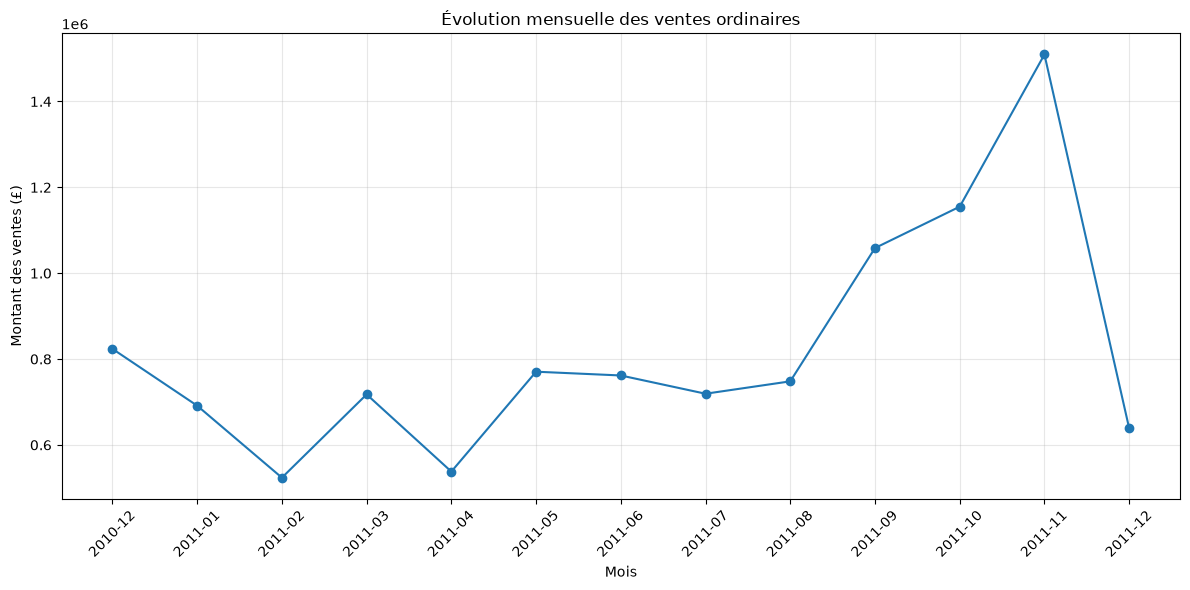

In [98]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["YearMonth"].astype(str),
    monthly_sales["LineTotal"],
    marker="o"
)

plt.title("Évolution mensuelle des ventes ordinaires")
plt.xlabel("Mois")
plt.ylabel("Montant des ventes (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [99]:
monthly_invoices = (
    sales_analytic_df
    .groupby("YearMonth")["InvoiceNo"]
    .nunique()
    .reset_index(name="InvoiceCount")
)

display(monthly_invoices)

,YearMonth,InvoiceCount
0,2010-12,1699
1,2011-01,1216
2,2011-02,1174
3,2011-03,1665
4,2011-04,1504
5,2011-05,1848
6,2011-06,1683
7,2011-07,1657
8,2011-08,1456
9,2011-09,1994


In [100]:
monthly_analysis = monthly_sales.merge(
    monthly_invoices,
    on="YearMonth"
)

monthly_analysis["AverageInvoiceValue"] = (
    monthly_analysis["LineTotal"] /
    monthly_analysis["InvoiceCount"]
)

display(monthly_analysis.round(2))

C:\Users\abiyi\AppData\Local\Temp\ipykernel_23192\898085209.py:11: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_analysis.round(2))


,YearMonth,LineTotal,InvoiceCount,AverageInvoiceValue
0,2010-12,823746.14,1699,484.84
1,2011-01,691364.56,1216,568.56
2,2011-02,523631.89,1174,446.02
3,2011-03,717639.36,1665,431.01
4,2011-04,537808.62,1504,357.59
5,2011-05,770536.02,1848,416.96
6,2011-06,761739.90,1683,452.61
7,2011-07,719221.19,1657,434.05
8,2011-08,748076.32,1456,513.79
9,2011-09,1058590.17,1994,530.89


In [101]:
top_products = (
    sales_analytic_df
    .groupby(["StockCode", "Description"])["LineTotal"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

display(top_products.round(2))

,StockCode,Description,LineTotal
0,DOT,DOTCOM POSTAGE,206248.77
1,22423,REGENCY CAKESTAND 3 TIER,174484.74
2,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104340.29
4,47566,PARTY BUNTING,99504.33
5,85099B,JUMBO BAG RED RETROSPOT,94340.05
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
7,M,Manual,78110.27
8,POST,POSTAGE,78101.88
9,23084,RABBIT NIGHT LIGHT,66964.99


In [102]:
non_product_codes = [
    "POST", "DOT", "M", "D", "S",
    "BANK CHARGES", "AMAZONFEE", "CRUK",
    "DCGSSGIRL", "DCGSSBOY", "PADS", "B", "m"
]

physical_products_df = sales_analytic_df[
    ~sales_analytic_df["StockCode"].astype(str).isin(non_product_codes)
].copy()

top_physical_products = (
    physical_products_df
    .groupby(["StockCode", "Description"])["LineTotal"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

display(top_physical_products.round(2))

,StockCode,Description,LineTotal
0,22423,REGENCY CAKESTAND 3 TIER,174484.74
1,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104340.29
3,47566,PARTY BUNTING,99504.33
4,85099B,JUMBO BAG RED RETROSPOT,94340.05
5,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
6,23084,RABBIT NIGHT LIGHT,66964.99
7,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64952.29
8,84879,ASSORTED COLOUR BIRD ORNAMENT,59094.93
9,79321,CHILLI LIGHTS,54117.76


In [103]:
top_products_quantity = (
    physical_products_df
    .groupby(["StockCode", "Description"])["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

display(top_products_quantity)

,StockCode,Description,Quantity
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033
2,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,55047
3,85099B,JUMBO BAG RED RETROSPOT,48478
4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37603
5,22197,POPCORN HOLDER,36761
6,84879,ASSORTED COLOUR BIRD ORNAMENT,36461
7,21212,PACK OF 72 RETROSPOT CAKE CASES,36419
8,23084,RABBIT NIGHT LIGHT,30788
9,22492,MINI PAINT SET VINTAGE,26633


In [104]:
product_comparison = top_physical_products.merge(
    top_products_quantity,
    on=["StockCode", "Description"],
    how="outer"
)

product_comparison = product_comparison.rename(
    columns={
        "LineTotal": "Revenue",
        "Quantity": "NetQuantity"
    }
)

product_comparison = product_comparison.sort_values(
    by="Revenue",
    ascending=False
)

display(product_comparison.round(2))

,StockCode,Description,Revenue,NetQuantity
3,22423,REGENCY CAKESTAND 3 TIER,174484.74,NaN
7,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995.0
13,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104340.29,37603.0
8,47566,PARTY BUNTING,99504.33,NaN
12,85099B,JUMBO BAG RED RETROSPOT,94340.05,48478.0
6,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033.0
5,23084,RABBIT NIGHT LIGHT,66964.99,30788.0
1,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64952.29,NaN
11,84879,ASSORTED COLOUR BIRD ORNAMENT,59094.93,36461.0
9,79321,CHILLI LIGHTS,54117.76,NaN


In [105]:
customer_df = sales_analytic_df.dropna(
    subset=["CustomerID"]
).copy()

top_customers = (
    customer_df
    .groupby("CustomerID")
    .agg(
        Revenue=("LineTotal", "sum"),
        InvoiceCount=("InvoiceNo", "nunique"),
        TotalQuantity=("Quantity", "sum")
    )
    .sort_values(
        by="Revenue",
        ascending=False
    )
    .head(10)
    .reset_index()
)

display(top_customers.round(2))

,CustomerID,Revenue,InvoiceCount,TotalQuantity
0,14646.0,280206.02,74,197491
1,18102.0,259657.30,60,64124
2,17450.0,194550.79,46,69993
3,16446.0,168472.50,2,80997
4,14911.0,143825.06,201,80515
5,12415.0,124914.53,21,77670
6,14156.0,117379.63,55,57885
7,17511.0,91062.38,31,64549
8,16029.0,81024.84,63,40208
9,12346.0,77183.60,1,74215


In [106]:
top_customers["AverageInvoiceValue"] = (
    top_customers["Revenue"] /
    top_customers["InvoiceCount"]
)

display(
    top_customers.sort_values(
        by="AverageInvoiceValue",
        ascending=False
    ).round(2)
)

,CustomerID,Revenue,InvoiceCount,TotalQuantity,AverageInvoiceValue
3,16446.0,168472.50,2,80997,84236.25
9,12346.0,77183.60,1,74215,77183.60
5,12415.0,124914.53,21,77670,5948.31
1,18102.0,259657.30,60,64124,4327.62
2,17450.0,194550.79,46,69993,4229.36
0,14646.0,280206.02,74,197491,3786.57
7,17511.0,91062.38,31,64549,2937.50
6,14156.0,117379.63,55,57885,2134.18
8,16029.0,81024.84,63,40208,1286.11
4,14911.0,143825.06,201,80515,715.55


In [107]:
# Revenus de tous les clients identifiés
total_customer_revenue = customer_df["LineTotal"].sum()

# Revenus des 10 premiers clients
top_10_revenue = top_customers["Revenue"].sum()

# Part des 10 premiers clients
top_10_share = (
    top_10_revenue / total_customer_revenue
) * 100

print(f"Revenus des clients identifiés : {total_customer_revenue:,.2f} £")
print(f"Revenus des 10 premiers clients : {top_10_revenue:,.2f} £")
print(f"Part des 10 premiers clients : {top_10_share:.2f} %")

Revenus des clients identifiés : 8,911,407.90 £
Revenus des 10 premiers clients : 1,538,276.65 £
Part des 10 premiers clients : 17.26 %


In [108]:
country_analysis = (
    sales_analytic_df
    .groupby("Country")
    .agg(
        Revenue=("LineTotal", "sum"),
        InvoiceCount=("InvoiceNo", "nunique"),
        CustomerCount=("CustomerID", "nunique"),
        TotalQuantity=("Quantity", "sum")
    )
    .sort_values(
        by="Revenue",
        ascending=False
    )
    .reset_index()
)

display(country_analysis.head(15).round(2))

,Country,Revenue,InvoiceCount,CustomerCount,TotalQuantity
0,United Kingdom,9014160.02,20119,3921,4526859
1,Netherlands,285446.34,95,9,200937
2,EIRE,283453.96,288,3,147447
3,Germany,228867.14,457,94,119263
4,France,209715.11,392,87,112104
5,Australia,138521.31,57,9,84209
6,Spain,61577.11,90,30,27951
7,Switzerland,57089.90,54,21,30630
8,Belgium,41196.34,98,25,23237
9,Sweden,38378.33,36,8,36083


In [109]:
# Part de chaque pays dans les revenus totaux
total_revenue = country_analysis["Revenue"].sum()

country_analysis["RevenueShare"] = (
    country_analysis["Revenue"] / total_revenue
) * 100

# Revenu moyen par facture
country_analysis["AverageInvoiceValue"] = (
    country_analysis["Revenue"] /
    country_analysis["InvoiceCount"]
)

# Affichage des 15 premiers pays
display(
    country_analysis[
        [
            "Country",
            "Revenue",
            "RevenueShare",
            "InvoiceCount",
            "CustomerCount",
            "AverageInvoiceValue"
        ]
    ].head(15).round(2)
)

,Country,Revenue,RevenueShare,InvoiceCount,CustomerCount,AverageInvoiceValue
0,United Kingdom,9014160.02,84.60,20119,3921,448.04
1,Netherlands,285446.34,2.68,95,9,3004.70
2,EIRE,283453.96,2.66,288,3,984.22
3,Germany,228867.14,2.15,457,94,500.80
4,France,209715.11,1.97,392,87,534.99
5,Australia,138521.31,1.30,57,9,2430.20
6,Spain,61577.11,0.58,90,30,684.19
7,Switzerland,57089.90,0.54,54,21,1057.22
8,Belgium,41196.34,0.39,98,25,420.37
9,Sweden,38378.33,0.36,36,8,1066.06


In [110]:
country_analysis["CumulativeRevenueShare"] = (
    country_analysis["RevenueShare"].cumsum()
)

display(
    country_analysis[
        [
            "Country",
            "RevenueShare",
            "CumulativeRevenueShare"
        ]
    ].head(15).round(2)
)

,Country,RevenueShare,CumulativeRevenueShare
0,United Kingdom,84.60,84.60
1,Netherlands,2.68,87.27
2,EIRE,2.66,89.93
3,Germany,2.15,92.08
4,France,1.97,94.05
5,Australia,1.30,95.35
6,Spain,0.58,95.93
7,Switzerland,0.54,96.46
8,Belgium,0.39,96.85
9,Sweden,0.36,97.21


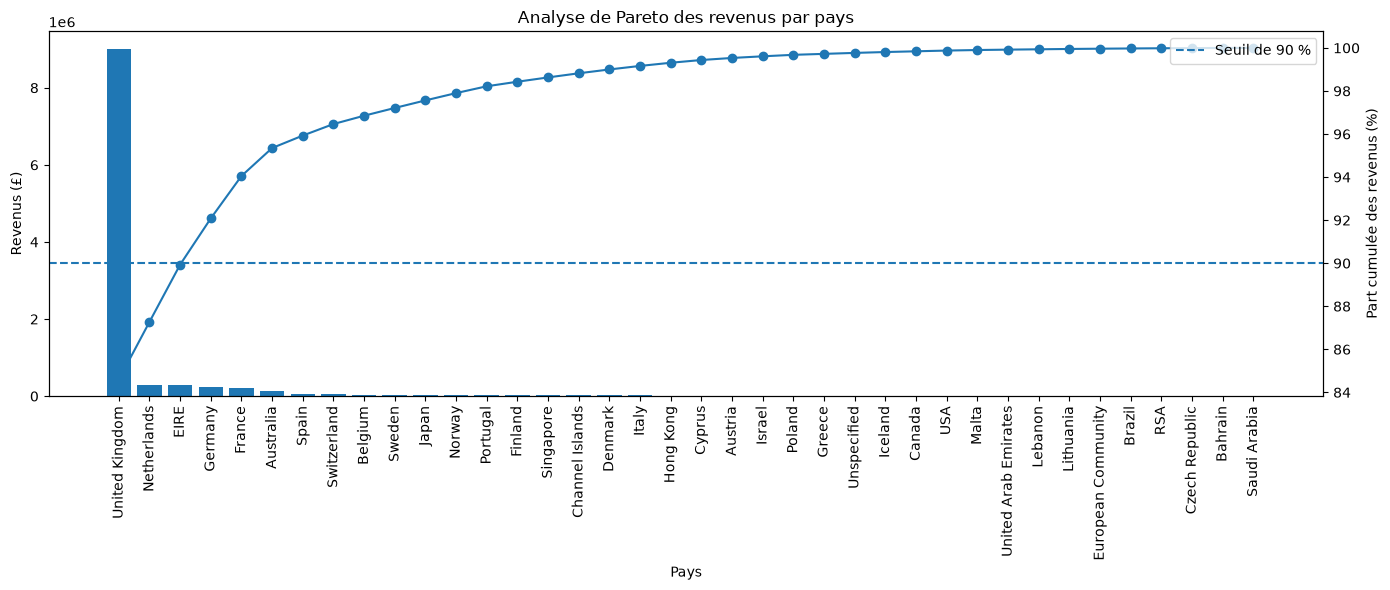

In [111]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(14, 6))

# Barres : revenus par pays
ax1.bar(
    country_analysis["Country"],
    country_analysis["Revenue"]
)

ax1.set_xlabel("Pays")
ax1.set_ylabel("Revenus (£)")
ax1.set_title("Analyse de Pareto des revenus par pays")
ax1.tick_params(axis="x", rotation=90)

# Courbe : part cumulée
ax2 = ax1.twinx()

ax2.plot(
    country_analysis["Country"],
    country_analysis["CumulativeRevenueShare"],
    marker="o"
)

ax2.set_ylabel("Part cumulée des revenus (%)")
ax2.axhline(
    y=90,
    linestyle="--",
    label="Seuil de 90 %"
)

ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

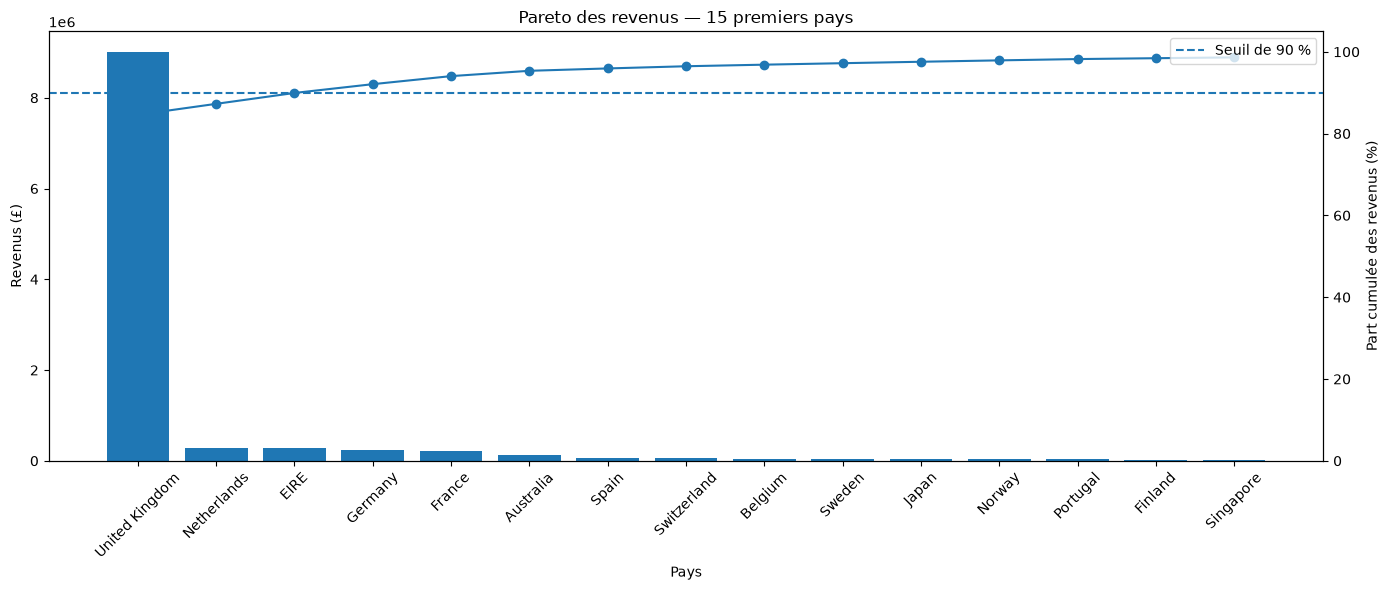

In [112]:
top_15_countries = country_analysis.head(15)

fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.bar(
    top_15_countries["Country"],
    top_15_countries["Revenue"]
)

ax1.set_xlabel("Pays")
ax1.set_ylabel("Revenus (£)")
ax1.set_title("Pareto des revenus — 15 premiers pays")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()

ax2.plot(
    top_15_countries["Country"],
    top_15_countries["CumulativeRevenueShare"],
    marker="o"
)

ax2.set_ylabel("Part cumulée des revenus (%)")
ax2.set_ylim(0, 105)
ax2.axhline(y=90, linestyle="--", label="Seuil de 90 %")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [113]:
print("Nombre de pays :", len(country_analysis))
print(
    "Premier pays :",
    country_analysis.iloc[0]["Country"]
)
print(
    "Part cumulée du premier pays :",
    country_analysis.iloc[0]["CumulativeRevenueShare"]
)
print(
    "Part cumulée du quatrième pays :",
    country_analysis.iloc[3]["CumulativeRevenueShare"]
)

Nombre de pays : 38
Premier pays : United Kingdom
Part cumulée du premier pays : 84.59533957340601
Part cumulée du quatrième pays : 92.0821611194761


In [114]:
from pathlib import Path

figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

print("Dossier des graphiques :", figures_dir.resolve())

Dossier des graphiques : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\figures


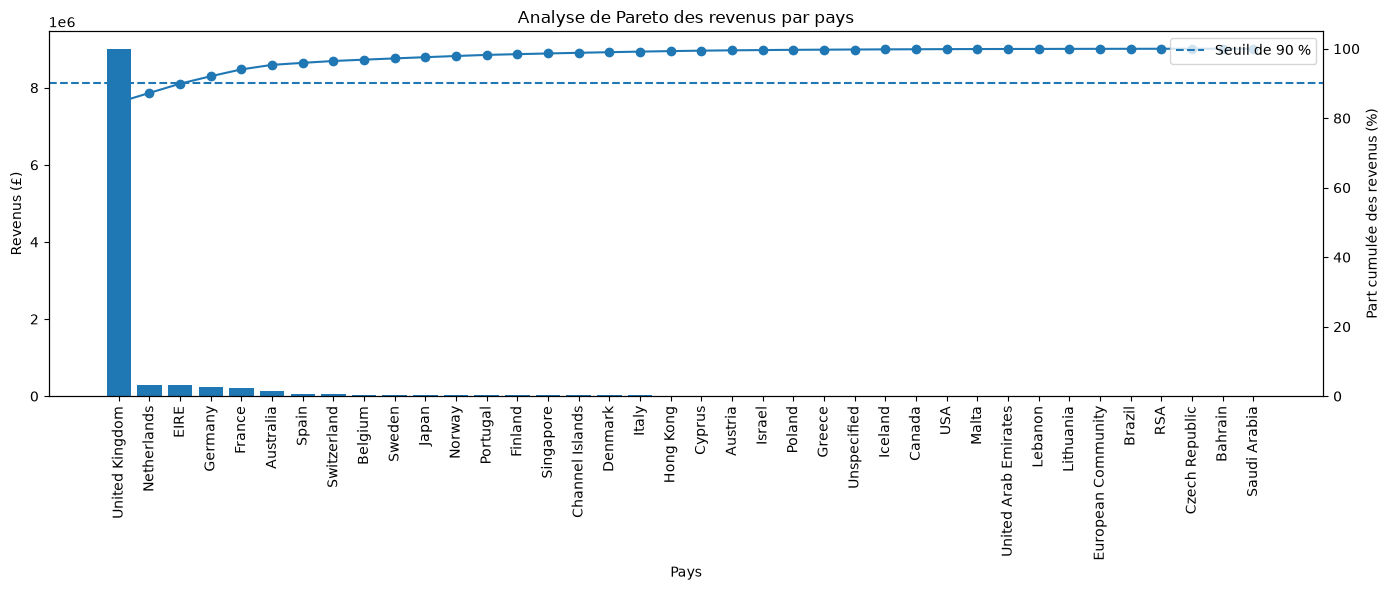

In [115]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.bar(
    country_analysis["Country"],
    country_analysis["Revenue"]
)

ax1.set_xlabel("Pays")
ax1.set_ylabel("Revenus (£)")
ax1.set_title("Analyse de Pareto des revenus par pays")
ax1.tick_params(axis="x", rotation=90)

ax2 = ax1.twinx()

ax2.plot(
    country_analysis["Country"],
    country_analysis["CumulativeRevenueShare"],
    marker="o"
)

ax2.set_ylabel("Part cumulée des revenus (%)")
ax2.set_ylim(0, 105)

ax2.axhline(
    y=90,
    linestyle="--",
    label="Seuil de 90 %"
)

ax2.legend(loc="upper right")

plt.tight_layout()

# Enregistrement du graphique
plt.savefig(
    figures_dir / "pareto_revenus_pays.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [116]:
print("=== RÉSUMÉ DU GRAPHIQUE DE PARETO ===")

print(f"Nombre de pays : {len(country_analysis)}")

print("\nTop 5 des pays :")

display(
    country_analysis[
        ["Country", "Revenue", "RevenueShare",
         "CumulativeRevenueShare"]
    ].head(5).round(2)
)

print("\nPremier pays :", country_analysis.iloc[0]["Country"])

print(
    "Part du premier pays :",
    round(country_analysis.iloc[0]["RevenueShare"], 2),
    "%"
)

countries_90 = country_analysis[
    country_analysis["CumulativeRevenueShare"] >= 90
]

print(
    "Nombre de pays nécessaires pour atteindre 90 % :",
    len(countries_90.head(1)) if not countries_90.empty else "Non atteint"
)

=== RÉSUMÉ DU GRAPHIQUE DE PARETO ===
Nombre de pays : 38

Top 5 des pays :


,Country,Revenue,RevenueShare,CumulativeRevenueShare
0,United Kingdom,9014160.02,84.60,84.60
1,Netherlands,285446.34,2.68,87.27
2,EIRE,283453.96,2.66,89.93
3,Germany,228867.14,2.15,92.08
4,France,209715.11,1.97,94.05



Premier pays : United Kingdom
Part du premier pays : 84.6 %
Nombre de pays nécessaires pour atteindre 90 % : 1


In [117]:
from pathlib import Path

PROJECT_ROOT = Path("..")

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

FIGURE_CATEGORIES = [
    "temporal_analysis",
    "product_analysis",
    "customer_analysis",
    "geographic_analysis"
]

for category in FIGURE_CATEGORIES:
    (FIGURES_DIR / category).mkdir(
        parents=True,
        exist_ok=True
    )

print("Structure des graphiques créée.")

Structure des graphiques créée.


In [118]:
def save_figure(fig, filename, category):
    """
    Sauvegarde une figure en PNG, SVG et PDF.

    Parameters
    ----------
    fig : matplotlib.figure.Figure
        Figure à sauvegarder.
    filename : str
        Nom du fichier sans extension.
    category : str
        Catégorie du graphique.
    """

    output_dir = FIGURES_DIR / category
    output_dir.mkdir(parents=True, exist_ok=True)

    formats = ["png", "svg", "pdf"]

    for file_format in formats:
        output_path = output_dir / f"{filename}.{file_format}"

        if file_format == "png":
            fig.savefig(
                output_path,
                dpi=300,
                bbox_inches="tight"
            )
        else:
            fig.savefig(
                output_path,
                bbox_inches="tight"
            )

    print(f"Graphique sauvegardé : {output_dir / filename}")

Graphique sauvegardé : ..\reports\figures\geographic_analysis\pareto_revenue_by_country


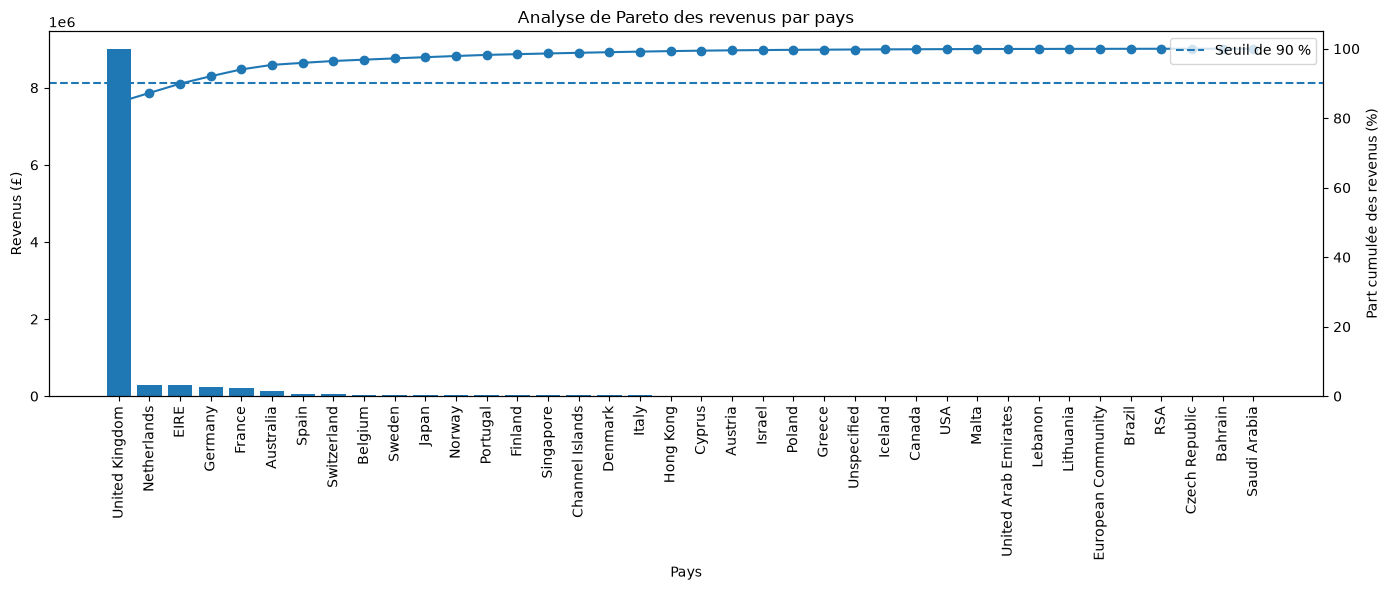

In [119]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.bar(
    country_analysis["Country"],
    country_analysis["Revenue"]
)

ax1.set_xlabel("Pays")
ax1.set_ylabel("Revenus (£)")
ax1.set_title("Analyse de Pareto des revenus par pays")
ax1.tick_params(axis="x", rotation=90)

ax2 = ax1.twinx()

ax2.plot(
    country_analysis["Country"],
    country_analysis["CumulativeRevenueShare"],
    marker="o"
)

ax2.set_ylabel("Part cumulée des revenus (%)")
ax2.set_ylim(0, 105)

ax2.axhline(
    y=90,
    linestyle="--",
    label="Seuil de 90 %"
)

ax2.legend(loc="upper right")

plt.tight_layout()

save_figure(
    fig=fig,
    filename="pareto_revenue_by_country",
    category="geographic_analysis"
)

plt.show()

In [120]:
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)

country_analysis.to_csv(
    TABLES_DIR / "country_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Tableau géographique sauvegardé.")

Tableau géographique sauvegardé.


In [121]:
# Codes opérationnels identifiés pendant l'audit
non_product_codes = [
    "POST", "DOT", "M", "D", "S",
    "BANK CHARGES", "AMAZONFEE", "CRUK",
    "DCGSSGIRL", "DCGSSBOY", "PADS", "B", "m"
]

# Séparer les opérations particulières
operational_df = sales_analytic_df[
    sales_analytic_df["StockCode"].astype(str).isin(non_product_codes)
].copy()

# Calculer leur impact
operational_analysis = (
    operational_df
    .groupby("StockCode")
    .agg(
        Description=("Description", "first"),
        LineCount=("InvoiceNo", "size"),
        InvoiceCount=("InvoiceNo", "nunique"),
        Revenue=("LineTotal", "sum"),
        TotalQuantity=("Quantity", "sum")
    )
    .sort_values("Revenue", ascending=False)
    .reset_index()
)

display(operational_analysis.round(2))

,StockCode,Description,LineCount,InvoiceCount,Revenue,TotalQuantity
0,DOT,DOTCOM POSTAGE,709,709,206248.77,1708
1,M,Manual,327,294,78110.27,7230
2,POST,POSTAGE,1130,1130,78101.88,6500
3,AMAZONFEE,AMAZON FEE,2,2,13761.09,2
4,BANK CHARGES,Bank Charges,12,11,165.00,12
5,DCGSSBOY,BOYS PARTY BAG,11,11,150.55,47
6,DCGSSGIRL,GIRLS PARTY BAG,13,13,144.43,47
7,S,SAMPLES,2,2,63.05,2
8,m,Manual,1,1,2.55,1
9,PADS,PADS TO MATCH ALL CUSHIONS,4,4,0.00,4


In [122]:
total_revenue = sales_analytic_df["LineTotal"].sum()

operational_revenue = operational_df["LineTotal"].sum()

operational_share = (
    operational_revenue / total_revenue
) * 100

print(f"Revenus totaux : {total_revenue:,.2f} £")
print(f"Revenus des opérations particulières : {operational_revenue:,.2f} £")
print(f"Part des opérations particulières : {operational_share:.2f} %")

Revenus totaux : 10,655,622.48 £
Revenus des opérations particulières : 376,747.59 £
Part des opérations particulières : 3.54 %


In [123]:
# Dictionnaire de classification provisoire
operational_mapping = {
    "POST": "Frais d'expédition",
    "DOT": "Frais d'expédition",
    "M": "Opérations manuelles",
    "m": "Opérations manuelles",
    "AMAZONFEE": "Frais et commissions",
    "BANK CHARGES": "Frais et commissions",
    "S": "Échantillons",
    "DCGSSBOY": "Articles physiques particuliers",
    "DCGSSGIRL": "Articles physiques particuliers",
    "PADS": "Articles physiques particuliers"
}

# Copie de travail
sales_classified_df = sales_analytic_df.copy()

# Classification
sales_classified_df["OperationalCategory"] = (
    sales_classified_df["StockCode"]
    .astype(str)
    .map(operational_mapping)
    .fillna("Produit ou code non classifié")
)

# Résumé par catégorie
category_analysis = (
    sales_classified_df
    .groupby("OperationalCategory")
    .agg(
        LineCount=("InvoiceNo", "size"),
        InvoiceCount=("InvoiceNo", "nunique"),
        Revenue=("LineTotal", "sum"),
        TotalQuantity=("Quantity", "sum")
    )
    .sort_values("Revenue", ascending=False)
    .reset_index()
)

display(category_analysis.round(2))

,OperationalCategory,LineCount,InvoiceCount,Revenue,TotalQuantity
0,Produit ou code non classifié,530407,21881,10278874.89,5438468
1,Frais d'expédition,1839,1839,284350.65,8208
2,Opérations manuelles,328,295,78112.82,7231
3,Frais et commissions,14,13,13926.09,14
4,Articles physiques particuliers,28,22,294.98,98
5,Échantillons,2,2,63.05,2


In [124]:
# Identifier les codes sans chiffre encore classés comme non classifiés
unclassified_df = sales_classified_df[
    sales_classified_df["OperationalCategory"]
    == "Produit ou code non classifié"
].copy()

unclassified_special_codes = (
    unclassified_df[
        ~unclassified_df["StockCode"].astype(str).str.contains(r"\d")
    ]
    .groupby("StockCode")
    .agg(
        Description=("Description", "first"),
        LineCount=("InvoiceNo", "size"),
        InvoiceCount=("InvoiceNo", "nunique"),
        Revenue=("LineTotal", "sum"),
        TotalQuantity=("Quantity", "sum")
    )
    .sort_values("LineCount", ascending=False)
    .reset_index()
)

display(unclassified_special_codes.round(2))

,StockCode,Description,LineCount,InvoiceCount,Revenue,TotalQuantity


In [125]:
display(unclassified_special_codes.round(2))

,StockCode,Description,LineCount,InvoiceCount,Revenue,TotalQuantity


In [126]:
# Vérifier les codes D et CRUK dans le dataset
verification_codes = (
    sales_analytic_df[
        sales_analytic_df["StockCode"].astype(str).isin(["D", "CRUK"])
    ]
    .groupby("StockCode")
    .agg(
        Description=("Description", "first"),
        LineCount=("InvoiceNo", "size"),
        InvoiceCount=("InvoiceNo", "nunique"),
        Revenue=("LineTotal", "sum"),
        TotalQuantity=("Quantity", "sum")
    )
    .reset_index()
)

display(verification_codes.round(2))

,StockCode,Description,LineCount,InvoiceCount,Revenue,TotalQuantity


In [127]:
# Catégories provisoirement considérées comme annexes
excluded_categories = [
    "Frais d'expédition",
    "Opérations manuelles",
    "Frais et commissions"
]

# Dataset commercial provisoire
commercial_sales_df = sales_classified_df[
    ~sales_classified_df["OperationalCategory"].isin(
        excluded_categories
    )
].copy()

# Contrôle des volumes et montants
print("Nombre de lignes :", len(commercial_sales_df))
print("Nombre de factures :", commercial_sales_df["InvoiceNo"].nunique())
print(
    "Revenus commerciaux provisoires :",
    round(commercial_sales_df["LineTotal"].sum(), 2),
    "£"
)

print(
    "Nombre de codes produits :",
    commercial_sales_df["StockCode"].nunique()
)

Nombre de lignes : 530437
Nombre de factures : 21883
Revenus commerciaux provisoires : 10279232.92 £
Nombre de codes produits : 4052


In [128]:
# Contrôle des types de lignes dans le périmètre commercial
commercial_line_analysis = (
    commercial_sales_df
    .groupby("TransactionCategory")
    .agg(
        LineCount=("InvoiceNo", "size"),
        InvoiceCount=("InvoiceNo", "nunique"),
        Revenue=("LineTotal", "sum"),
        TotalQuantity=("Quantity", "sum")
    )
    .reset_index()
    .sort_values("LineCount", ascending=False)
)

display(commercial_line_analysis.round(2))

,TransactionCategory,LineCount,InvoiceCount,Revenue,TotalQuantity
2,Vente standard,527935,19778,10279232.92,5577280
1,Mouvement non commercial potentiel,1336,1336,0.00,-206957
0,Ligne gratuite ou opération sans montant,1166,808,0.00,68245


In [129]:
# 1. Ventes standard
sales_standard_df = commercial_sales_df[
    commercial_sales_df["TransactionCategory"] == "Vente standard"
].copy()

# 2. Lignes gratuites ou sans montant
free_lines_df = commercial_sales_df[
    commercial_sales_df["TransactionCategory"]
    == "Ligne gratuite ou opération sans montant"
].copy()

# 3. Mouvements non commerciaux potentiels
potential_movements_df = commercial_sales_df[
    commercial_sales_df["TransactionCategory"]
    == "Mouvement non commercial potentiel"
].copy()

# Vérification des volumes
print("Ventes standard :", len(sales_standard_df))
print("Lignes gratuites :", len(free_lines_df))
print("Mouvements potentiels :", len(potential_movements_df))

# Vérification de la conservation des lignes
total_lines = (
    len(sales_standard_df)
    + len(free_lines_df)
    + len(potential_movements_df)
)

print("\nTotal des lignes réparties :", total_lines)
print("Total commercial initial :", len(commercial_sales_df))

assert total_lines == len(commercial_sales_df)

Ventes standard : 527935
Lignes gratuites : 1166
Mouvements potentiels : 1336

Total des lignes réparties : 530437
Total commercial initial : 530437


In [130]:
# Analyse des produits distribués gratuitement
free_products_analysis = (
    free_lines_df
    .groupby(["StockCode", "Description"])
    .agg(
        LineCount=("InvoiceNo", "size"),
        InvoiceCount=("InvoiceNo", "nunique"),
        TotalFreeQuantity=("Quantity", "sum")
    )
    .sort_values("TotalFreeQuantity", ascending=False)
    .reset_index()
)

display(free_products_analysis.head(20))

,StockCode,Description,LineCount,InvoiceCount,TotalFreeQuantity
0,84826,ASSTD DESIGN 3D PAPER STICKERS,1,1,12540
1,37413,ICON MUG REVOLUTIONARY,1,1,5568
2,85123A,?,1,1,4000
3,23343,came coded as 20713,1,1,3100
4,84988,?,1,1,3000
5,79063D,"RETRO PILL BOX , REVOLUTIONARY",1,1,2560
6,47566B,incorrectly credited C550456 see 47,1,1,1300
7,47556B,did a credit and did not tick ret,1,1,1300
8,84611B,thrown away,1,1,1287
9,46000S,POLYESTER FILLER PAD 40x40cm,5,5,1070


In [131]:
# Examiner les 20 lignes gratuites avec les quantités les plus élevées
free_lines_detail = (
    free_lines_df
    .sort_values("Quantity", ascending=False)
    [[
        "InvoiceNo",
        "InvoiceDate",
        "CustomerID",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "LineTotal",
        "Country"
    ]]
)

display(free_lines_detail.head(20))

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice,LineTotal,Country
502122,578841,2011-11-25 15:57:00,13256.0,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.0,0.0,United Kingdom
74614,542504,2011-01-28 12:03:00,NaN,37413,ICON MUG REVOLUTIONARY,5568,0.0,0.0,United Kingdom
220843,556231,2011-06-09 15:04:00,NaN,85123A,?,4000,0.0,0.0,United Kingdom
263885,560040,2011-07-14 14:28:00,NaN,23343,came coded as 20713,3100,0.0,0.0,United Kingdom
115807,546139,2011-03-09 16:35:00,NaN,84988,?,3000,0.0,0.0,United Kingdom
74615,542505,2011-01-28 12:04:00,NaN,79063D,"RETRO PILL BOX , REVOLUTIONARY",2560,0.0,0.0,United Kingdom
160541,550460,2011-04-18 13:18:00,NaN,47556B,did a credit and did not tick ret,1300,0.0,0.0,United Kingdom
203751,554550,2011-05-25 09:57:00,NaN,47566B,incorrectly credited C550456 see 47,1300,0.0,0.0,United Kingdom
82795,543258,2011-02-04 16:06:00,NaN,84611B,thrown away,1287,0.0,0.0,United Kingdom
422750,573114,2011-10-27 15:36:00,NaN,20713,wrongly coded 23343,1000,0.0,0.0,United Kingdom


In [132]:
# Définir des seuils exploratoires de quantité
quantity_thresholds = [100, 500, 1000, 5000]

for threshold in quantity_thresholds:
    count = (free_lines_df["Quantity"] >= threshold).sum()

    percentage = count / len(free_lines_df) * 100

    print(
        f"Quantité >= {threshold:>5} : "
        f"{count:>4} lignes ({percentage:.2f} %)"
    )

# Statistiques descriptives
display(
    free_lines_df["Quantity"].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Quantité >=   100 :  108 lignes (9.26 %)
Quantité >=   500 :   15 lignes (1.29 %)
Quantité >=  1000 :   10 lignes (0.86 %)
Quantité >=  5000 :    2 lignes (0.17 %)


count     1166.000000
mean        58.529160
std        452.838141
min          1.000000
50%          3.000000
75%         20.000000
90%         83.000000
95%        170.000000
99%        768.800000
max      12540.000000
Name: Quantity, dtype: float64

In [133]:
# Examiner les 15 lignes gratuites ayant les quantités les plus élevées
high_quantity_free_lines = (
    free_lines_df[
        free_lines_df["Quantity"] >= 500
    ]
    .sort_values("Quantity", ascending=False)
    [[
        "InvoiceNo",
        "InvoiceDate",
        "CustomerID",
        "StockCode",
        "Description",
        "Quantity",
        "Country"
    ]]
)

display(high_quantity_free_lines)

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,Country
502122,578841,2011-11-25 15:57:00,13256.0,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,United Kingdom
74614,542504,2011-01-28 12:03:00,NaN,37413,ICON MUG REVOLUTIONARY,5568,United Kingdom
220843,556231,2011-06-09 15:04:00,NaN,85123A,?,4000,United Kingdom
263885,560040,2011-07-14 14:28:00,NaN,23343,came coded as 20713,3100,United Kingdom
115807,546139,2011-03-09 16:35:00,NaN,84988,?,3000,United Kingdom
74615,542505,2011-01-28 12:04:00,NaN,79063D,"RETRO PILL BOX , REVOLUTIONARY",2560,United Kingdom
160541,550460,2011-04-18 13:18:00,NaN,47556B,did a credit and did not tick ret,1300,United Kingdom
203751,554550,2011-05-25 09:57:00,NaN,47566B,incorrectly credited C550456 see 47,1300,United Kingdom
82795,543258,2011-02-04 16:06:00,NaN,84611B,thrown away,1287,United Kingdom
422750,573114,2011-10-27 15:36:00,NaN,20713,wrongly coded 23343,1000,United Kingdom


In [134]:
# 1. Vérifier les caractéristiques générales
print("Nombre de lignes :", len(potential_movements_df))
print("Factures distinctes :", potential_movements_df["InvoiceNo"].nunique())
print("Codes produits distincts :", potential_movements_df["StockCode"].nunique())
print("Quantité totale :", potential_movements_df["Quantity"].sum())
print("Montant total :", potential_movements_df["LineTotal"].sum())

# 2. Examiner les descriptions les plus fréquentes
movement_description_analysis = (
    potential_movements_df
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        LineCount=("InvoiceNo", "size"),
        InvoiceCount=("InvoiceNo", "nunique"),
        TotalQuantity=("Quantity", "sum")
    )
    .sort_values("LineCount", ascending=False)
)

display(movement_description_analysis.head(20))

# 3. Examiner les factures les plus concernées
movement_invoice_analysis = (
    potential_movements_df
    .groupby("InvoiceNo")
    .agg(
        LineCount=("InvoiceNo", "size"),
        TotalQuantity=("Quantity", "sum"),
        InvoiceDate=("InvoiceDate", "first")
    )
    .sort_values("LineCount", ascending=False)
)

display(movement_invoice_analysis.head(15))

Nombre de lignes : 1336
Factures distinctes : 1336
Codes produits distincts : 1082
Quantité totale : -206957
Montant total : 0.0


,,LineCount,InvoiceCount,TotalQuantity
StockCode,Description,,,
22162,HEART GARLAND RUSTIC PADDED,3,3,-104
21161,KEEP OUT BOYS DOOR HANGER,3,3,-168
20892,SET/3 TALL GLASS CANDLE HOLDER PINK,3,3,-34
22034,ROBIN CHRISTMAS CARD,3,3,-246
20966,SANDWICH BATH SPONGE,3,3,-194
22114,HOT WATER BOTTLE TEA AND SYMPATHY,3,3,-219
84631,FRUIT TREE AND BIRDS WALL PLAQUE,3,3,-32
72802B,check,3,3,-290
72802C,check,3,3,-75


,LineCount,TotalQuantity,InvoiceDate
InvoiceNo,,,
536589,1,-10,2010-12-01 16:50:00
536764,1,-38,2010-12-02 14:42:00
536996,1,-20,2010-12-03 15:30:00
536997,1,-20,2010-12-03 15:30:00
536998,1,-6,2010-12-03 15:30:00
537000,1,-22,2010-12-03 15:32:00
537001,1,-6,2010-12-03 15:33:00
537003,1,-2,2010-12-03 15:33:00
537004,1,-30,2010-12-03 15:34:00


In [135]:
# Examiner les 20 mouvements aux quantités les plus extrêmes
extreme_movements = (
    potential_movements_df
    .assign(AbsQuantity=lambda x: x["Quantity"].abs())
    .sort_values("AbsQuantity", ascending=False)
    [[
        "InvoiceNo",
        "InvoiceDate",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "CustomerID",
        "Country"
    ]]
    .head(20)
)

display(extreme_movements)

,InvoiceNo,InvoiceDate,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
225529,556690,2011-06-14 10:37:00,23005,printing smudges/thrown away,-9600,0.0,NaN,United Kingdom
225530,556691,2011-06-14 10:37:00,23005,printing smudges/thrown away,-9600,0.0,NaN,United Kingdom
225528,556687,2011-06-14 10:36:00,23003,Printing smudges/thrown away,-9058,0.0,NaN,United Kingdom
115818,546152,2011-03-09 17:25:00,72140F,throw away,-5368,0.0,NaN,United Kingdom
431381,573596,2011-10-31 15:17:00,79323W,"Unsaleable, destroyed.",-4830,0.0,NaN,United Kingdom
341601,566768,2011-09-14 17:53:00,16045,NaN,-3667,0.0,NaN,United Kingdom
323458,565304,2011-09-02 12:18:00,16259,PIECE OF CAMO STATIONERY SET,-3167,0.0,NaN,United Kingdom
263884,560039,2011-07-14 14:27:00,20713,wrongly marked. 23343 in box,-3100,0.0,NaN,United Kingdom
113580,545990,2011-03-08 13:07:00,84598,check,-3000,0.0,NaN,United Kingdom
375429,569466,2011-10-04 11:42:00,23270,incorrect stock entry.,-2880,0.0,NaN,United Kingdom


In [136]:

# Copie de travail
potential_movements_df = potential_movements_df.copy()

# Normalisation des descriptions
description_normalized = (
    potential_movements_df["Description"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.strip()
)

# Création de conditions explicitement booléennes
conditions = [
    description_normalized.str.contains(
        r"thrown away|throw away|destroyed|mouldy|"
        r"unsaleable|damages|damaged|rusty|smudges",
        regex=True,
        na=False
    ).to_numpy(dtype=bool),

    description_normalized.str.contains(
        r"wrongly|incorrect|coded as|stock entry",
        regex=True,
        na=False
    ).to_numpy(dtype=bool),

    description_normalized.str.contains(
        r"\bcheck\b|\?missing",
        regex=True,
        na=False
    ).to_numpy(dtype=bool)
]

categories = [
    "Perte ou destruction probable",
    "Erreur de stock ou de codification probable",
    "Contrôle ou vérification nécessaire"
]

potential_movements_df["MovementSubcategory"] = np.select(
    conditions,
    categories,
    default="Nature indéterminée"
)

# Vérification des résultats
movement_subcategory_analysis = (
    potential_movements_df
    .groupby("MovementSubcategory")
    .agg(
        LineCount=("InvoiceNo", "size"),
        TotalQuantity=("Quantity", "sum"),
        InvoiceCount=("InvoiceNo", "nunique")
    )
    .sort_values("LineCount", ascending=False)
)

display(movement_subcategory_analysis)


,LineCount,TotalQuantity,InvoiceCount
MovementSubcategory,,,
Nature indéterminée,1023,-86853,1023
Perte ou destruction probable,165,-89155,165
Contrôle ou vérification nécessaire,134,-16562,134
Erreur de stock ou de codification probable,14,-14387,14


In [137]:

# Vérifier que toutes les lignes ont été classifiées
assert potential_movements_df["MovementSubcategory"].notna().all()

# Vérifier la réconciliation du nombre de lignes
assert movement_subcategory_analysis["LineCount"].sum() == len(
    potential_movements_df
)

# Vérifier la réconciliation des quantités
assert movement_subcategory_analysis["TotalQuantity"].sum() == (
    potential_movements_df["Quantity"].sum()
)

# Vérifier l'unicité des factures
assert potential_movements_df["InvoiceNo"].nunique() == len(
    potential_movements_df
)

print("Tous les contrôles sont validés.")


Tous les contrôles sont validés.


In [138]:

# Créer une copie du dataset principal
final_sales_df = sales_classified_df.copy()

# Réintégrer les sous-catégories des mouvements potentiels
final_sales_df["MovementSubcategory"] = (
    potential_movements_df["MovementSubcategory"]
    .reindex(final_sales_df.index)
)

# Vérifier la réintégration
print("Nombre total de lignes :", len(final_sales_df))

print(
    "Mouvements potentiels :",
    final_sales_df["MovementSubcategory"].notna().sum()
)

print(
    "Sous-catégories manquantes parmi les mouvements potentiels :",
    final_sales_df.loc[
        final_sales_df["TransactionCategory"]
        == "Mouvement non commercial potentiel",
        "MovementSubcategory"
    ].isna().sum()
)

# Contrôles
assert len(final_sales_df) == len(sales_classified_df)

assert (
    final_sales_df["MovementSubcategory"].notna().sum()
    == len(potential_movements_df)
)

assert (
    final_sales_df.loc[
        final_sales_df["TransactionCategory"]
        == "Mouvement non commercial potentiel",
        "MovementSubcategory"
    ].notna().all()
)

print("Réintégration validée.")


Nombre total de lignes : 532618
Mouvements potentiels : 1336
Sous-catégories manquantes parmi les mouvements potentiels : 0
Réintégration validée.


In [139]:

# Catégories opérationnelles exclues des analyses commerciales
excluded_categories = [
    "Frais d'expédition",
    "Opérations manuelles",
    "Frais et commissions"
]

# 1. Dataset commercial
final_commercial_df = final_sales_df[
    ~final_sales_df["OperationalCategory"].isin(excluded_categories)
].copy()

# 2. Dataset des ventes standard
final_sales_standard_df = final_commercial_df[
    final_commercial_df["TransactionCategory"] == "Vente standard"
].copy()

# 3. Contrôle des volumes
print("DATASET CONSOLIDÉ")
print("Lignes :", len(final_sales_df))

print("\nDATASET COMMERCIAL")
print("Lignes :", len(final_commercial_df))
print("Factures :", final_commercial_df["InvoiceNo"].nunique())
print("Chiffre d'affaires :", round(final_commercial_df["LineTotal"].sum(), 2))

print("\nDATASET DES VENTES STANDARD")
print("Lignes :", len(final_sales_standard_df))
print("Factures :", final_sales_standard_df["InvoiceNo"].nunique())
print("Codes distincts :", final_sales_standard_df["StockCode"].nunique())
print("Chiffre d'affaires :", round(final_sales_standard_df["LineTotal"].sum(), 2))
print("Quantité vendue :", final_sales_standard_df["Quantity"].sum())

# 4. Vérifications de cohérence
assert len(final_sales_df) == 532618
assert len(final_commercial_df) == 530437
assert len(final_sales_standard_df) == 527935

assert (
    final_sales_standard_df["TransactionCategory"]
    .eq("Vente standard")
    .all()
)

assert (final_sales_standard_df["Quantity"] > 0).all()
assert (final_sales_standard_df["UnitPrice"] > 0).all()

print("\nTous les contrôles sont validés.")


DATASET CONSOLIDÉ
Lignes : 532618

DATASET COMMERCIAL
Lignes : 530437
Factures : 21883
Chiffre d'affaires : 10279232.92

DATASET DES VENTES STANDARD
Lignes : 527935
Factures : 19778
Codes distincts : 3915
Chiffre d'affaires : 10279232.92
Quantité vendue : 5577280

Tous les contrôles sont validés.


In [140]:

# Analyse temporelle définitive
temporal_analysis = final_sales_standard_df.copy()

temporal_analysis["YearMonth"] = (
    temporal_analysis["InvoiceDate"].dt.to_period("M")
)

monthly_kpis = (
    temporal_analysis
    .groupby("YearMonth")
    .agg(
        Revenue=("LineTotal", "sum"),
        InvoiceCount=("InvoiceNo", "nunique"),
        QuantitySold=("Quantity", "sum"),
        LineCount=("InvoiceNo", "size")
    )
    .reset_index()
)

monthly_kpis["AverageInvoiceValue"] = (
    monthly_kpis["Revenue"] / monthly_kpis["InvoiceCount"]
)

monthly_kpis["Revenue"] = monthly_kpis["Revenue"].round(2)
monthly_kpis["AverageInvoiceValue"] = (
    monthly_kpis["AverageInvoiceValue"].round(2)
)

display(monthly_kpis)


,YearMonth,Revenue,InvoiceCount,QuantitySold,LineCount,AverageInvoiceValue
0,2010-12,778608.36,1551,358761,41327,502.00
1,2011-01,672192.41,1081,387431,34155,621.82
2,2011-02,509167.87,1093,283256,26972,465.84
3,2011-03,692015.94,1440,377125,35623,480.57
4,2011-04,516739.79,1236,308527,28970,418.07
5,2011-05,741711.74,1668,395404,35992,444.67
6,2011-06,739426.88,1525,388843,35790,484.87
7,2011-07,689947.74,1452,401369,38456,475.17
8,2011-08,726005.16,1340,421459,34339,541.79
9,2011-09,1031400.36,1819,569967,49076,567.02


In [141]:

# Analyse des performances par produit
product_analysis = (
    final_sales_standard_df
    .groupby(["StockCode", "Description"])
    .agg(
        Revenue=("LineTotal", "sum"),
        QuantitySold=("Quantity", "sum"),
        InvoiceCount=("InvoiceNo", "nunique"),
        LineCount=("InvoiceNo", "size")
    )
    .reset_index()
)

# Classement par chiffre d'affaires
top_products_revenue = (
    product_analysis
    .sort_values("Revenue", ascending=False)
    .head(10)
)

# Classement par quantités vendues
top_products_quantity = (
    product_analysis
    .sort_values("QuantitySold", ascending=False)
    .head(10)
)

print("TOP 10 — CHIFFRE D'AFFAIRES")
display(top_products_revenue)

print("TOP 10 — QUANTITÉS VENDUES")
display(top_products_quantity)


TOP 10 — CHIFFRE D'AFFAIRES


,StockCode,Description,Revenue,QuantitySold,InvoiceCount,LineCount
1262,22423,REGENCY CAKESTAND 3 TIER,174484.74,13879,1988,2017
2590,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1,1
3773,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104340.29,37599,2189,2256
2669,47566,PARTY BUNTING,99504.33,18295,1685,1706
3761,85099B,JUMBO BAG RED RETROSPOT,94340.05,48474,2089,2112
2045,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247,250
1951,23084,RABBIT NIGHT LIGHT,66964.99,30788,994,1036
944,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64952.29,19355,1160,1200
2875,84879,ASSORTED COLOUR BIRD ORNAMENT,59094.93,36461,1455,1489
2737,79321,CHILLI LIGHTS,54117.76,10306,661,670


TOP 10 — QUANTITÉS VENDUES


,StockCode,Description,Revenue,QuantitySold,InvoiceCount,LineCount
2590,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1,1
2045,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247,250
2769,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,13841.85,55047,535,537
3761,85099B,JUMBO BAG RED RETROSPOT,94340.05,48474,2089,2112
3773,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104340.29,37599,2189,2256
1051,22197,POPCORN HOLDER,34298.87,36761,803,829
2875,84879,ASSORTED COLOUR BIRD ORNAMENT,59094.93,36461,1455,1489
370,21212,PACK OF 72 RETROSPOT CAKE CASES,21259.10,36419,1320,1370
1951,23084,RABBIT NIGHT LIGHT,66964.99,30788,994,1036
1327,22492,MINI PAINT SET VINTAGE,16937.82,26633,380,380


In [142]:

# Inspection des transactions du produit atypique
product_23843 = final_sales_standard_df[
    final_sales_standard_df["StockCode"].astype(str) == "23843"
]

display(
    product_23843[
        [
            "InvoiceNo",
            "InvoiceDate",
            "StockCode",
            "Description",
            "Quantity",
            "UnitPrice",
            "LineTotal",
            "CustomerID",
            "Country"
        ]
    ]
)

print("Nombre de lignes :", len(product_23843))
print("Nombre de factures :", product_23843["InvoiceNo"].nunique())
print("Quantité totale :", product_23843["Quantity"].sum())
print("Chiffre d'affaires :", product_23843["LineTotal"].sum())


,InvoiceNo,InvoiceDate,StockCode,Description,Quantity,UnitPrice,LineTotal,CustomerID,Country
540421,581483,2011-12-09 09:15:00,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,16446.0,United Kingdom


Nombre de lignes : 1
Nombre de factures : 1
Quantité totale : 80995
Chiffre d'affaires : 168469.6


In [143]:

# Analyse limitée aux clients identifiés
customer_analysis = (
    final_sales_standard_df
    .dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        Revenue=("LineTotal", "sum"),
        InvoiceCount=("InvoiceNo", "nunique"),
        QuantitySold=("Quantity", "sum"),
        LineCount=("InvoiceNo", "size")
    )
    .reset_index()
)

customer_analysis["AverageInvoiceValue"] = (
    customer_analysis["Revenue"] / customer_analysis["InvoiceCount"]
)

customer_analysis = customer_analysis.round({
    "Revenue": 2,
    "AverageInvoiceValue": 2
})

# Top 10 des clients par chiffre d'affaires
top_customers = (
    customer_analysis
    .sort_values("Revenue", ascending=False)
    .head(10)
)

display(top_customers)


,CustomerID,Revenue,InvoiceCount,QuantitySold,LineCount,AverageInvoiceValue
1689,14646.0,279138.02,72,196844,2060,3876.92
4197,18102.0,259657.30,60,64124,431,4327.62
3725,17450.0,194550.79,46,69993,337,4229.36
3006,16446.0,168472.50,2,80997,3,84236.25
1879,14911.0,140450.72,199,80263,5673,705.78
55,12415.0,124564.53,20,77373,713,6228.23
1333,14156.0,117379.63,55,57885,1400,2134.18
3768,17511.0,91062.38,31,64549,963,2937.50
0,12346.0,77183.60,1,74215,1,77183.60
2700,16029.0,72882.09,62,40207,241,1175.52


In [144]:

# Indicateurs de concentration du chiffre d'affaires

total_revenue = final_sales_standard_df["LineTotal"].sum()

identified_revenue = customer_analysis["Revenue"].sum()

unknown_customer_revenue = total_revenue - identified_revenue

top_10_revenue = top_customers["Revenue"].sum()

top_10_share_global = (top_10_revenue / total_revenue) * 100

top_10_share_identified = (
    top_10_revenue / identified_revenue
) * 100

print(f"Chiffre d'affaires global : {total_revenue:,.2f} £")
print(f"CA des clients identifiés : {identified_revenue:,.2f} £")
print(f"CA sans CustomerID : {unknown_customer_revenue:,.2f} £")
print(f"Part du Top 10 dans le CA global : {top_10_share_global:.2f} %")
print(f"Part du Top 10 parmi les clients identifiés : {top_10_share_identified:.2f} %")
print(f"Nombre de clients identifiés : {customer_analysis['CustomerID'].nunique():,}")


Chiffre d'affaires global : 10,279,232.92 £
CA des clients identifiés : 8,767,752.65 £
CA sans CustomerID : 1,511,480.27 £
Part du Top 10 dans le CA global : 14.84 %
Part du Top 10 parmi les clients identifiés : 17.40 %
Nombre de clients identifiés : 4,334


In [145]:

# Analyse géographique des ventes standard

geographic_analysis = (
    final_sales_standard_df
    .groupby("Country")
    .agg(
        Revenue=("LineTotal", "sum"),
        InvoiceCount=("InvoiceNo", "nunique"),
        CustomerCount=("CustomerID", "nunique"),
        QuantitySold=("Quantity", "sum"),
        LineCount=("InvoiceNo", "size")
    )
    .reset_index()
)

# Indicateurs complémentaires
geographic_analysis["AverageInvoiceValue"] = (
    geographic_analysis["Revenue"]
    / geographic_analysis["InvoiceCount"]
)

total_revenue = final_sales_standard_df["LineTotal"].sum()

geographic_analysis["RevenueShare"] = (
    geographic_analysis["Revenue"] / total_revenue
) * 100

# Classement par chiffre d'affaires décroissant
geographic_analysis = (
    geographic_analysis
    .sort_values("Revenue", ascending=False)
    .reset_index(drop=True)
)

# Arrondir les indicateurs financiers
geographic_analysis = geographic_analysis.round({
    "Revenue": 2,
    "AverageInvoiceValue": 2,
    "RevenueShare": 2
})

display(geographic_analysis.head(15))

print("Nombre de pays :", geographic_analysis["Country"].nunique())

print(
    "Somme des chiffres d'affaires par pays :",
    round(geographic_analysis["Revenue"].sum(), 2),
    "£"
)


,Country,Revenue,InvoiceCount,CustomerCount,QuantitySold,LineCount,AverageInvoiceValue,RevenueShare
0,United Kingdom,8749785.52,17903,3916,4654423,484070,488.73,85.12
1,Netherlands,283889.34,93,9,200258,2322,3052.57,2.76
2,EIRE,276404.30,284,3,147168,7885,973.25,2.69
3,Germany,205569.89,443,94,118139,8658,464.04,2.00
4,France,184768.74,383,87,111272,8102,482.42,1.80
5,Australia,138171.31,56,9,83900,1181,2467.34,1.34
6,Spain,55725.11,88,30,27731,2422,633.24,0.54
7,Switzerland,53087.90,50,21,30527,1935,1061.76,0.52
8,Japan,37416.37,19,8,26016,321,1969.28,0.36
9,Belgium,36927.34,98,25,22962,1935,376.81,0.36


Nombre de pays : 38
Somme des chiffres d'affaires par pays : 10279232.92 £


In [146]:

# Analyse de Pareto géographique

geographic_pareto = geographic_analysis.copy()

geographic_pareto = geographic_pareto.sort_values(
    "Revenue",
    ascending=False
).reset_index(drop=True)

# Part individuelle exacte
geographic_pareto["RevenueShare"] = (
    geographic_pareto["Revenue"] / total_revenue
) * 100

# Part cumulée
geographic_pareto["CumulativeRevenue"] = (
    geographic_pareto["Revenue"].cumsum()
)

geographic_pareto["CumulativeShare"] = (
    geographic_pareto["CumulativeRevenue"] / total_revenue
) * 100

display(
    geographic_pareto[
        [
            "Country",
            "Revenue",
            "RevenueShare",
            "CumulativeShare"
        ]
    ].head(15).round(2)
)

# Nombre de pays nécessaires pour atteindre certains seuils
for threshold in [80, 90, 95]:
    countries_needed = (
        geographic_pareto["CumulativeShare"] >= threshold
    ).idxmax() + 1

    print(
        f"Pays nécessaires pour atteindre {threshold} % : "
        f"{countries_needed}"
    )


,Country,Revenue,RevenueShare,CumulativeShare
0,United Kingdom,8749785.52,85.12,85.12
1,Netherlands,283889.34,2.76,87.88
2,EIRE,276404.30,2.69,90.57
3,Germany,205569.89,2.00,92.57
4,France,184768.74,1.80,94.37
5,Australia,138171.31,1.34,95.71
6,Spain,55725.11,0.54,96.26
7,Switzerland,53087.90,0.52,96.77
8,Japan,37416.37,0.36,97.14
9,Belgium,36927.34,0.36,97.50


Pays nécessaires pour atteindre 80 % : 1
Pays nécessaires pour atteindre 90 % : 3
Pays nécessaires pour atteindre 95 % : 6


In [147]:

from pathlib import Path
import matplotlib.pyplot as plt

# Racine du projet
PROJECT_ROOT = Path("..")

# Répertoire principal des graphiques
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

# Répertoires par catégorie
FIGURE_CATEGORIES = [
    "temporal_analysis",
    "product_analysis",
    "customer_analysis",
    "geographic_analysis"
]

for category in FIGURE_CATEGORIES:
    (FIGURES_DIR / category).mkdir(
        parents=True,
        exist_ok=True
    )


def save_figure(fig, filename, category):
    """
    Sauvegarde une figure en PNG, SVG et PDF.
    """
    output_dir = FIGURES_DIR / category
    output_dir.mkdir(parents=True, exist_ok=True)

    for file_format in ["png", "svg", "pdf"]:
        output_path = output_dir / f"{filename}.{file_format}"

        if file_format == "png":
            fig.savefig(
                output_path,
                dpi=300,
                bbox_inches="tight"
            )
        else:
            fig.savefig(
                output_path,
                bbox_inches="tight"
            )

    print(f"Graphique sauvegardé : {output_dir / filename}")


print("Répertoires de graphiques préparés.")
print("Fonction save_figure() disponible.")


Répertoires de graphiques préparés.
Fonction save_figure() disponible.


Graphique sauvegardé : ..\reports\figures\temporal_analysis\monthly_revenue_evolution


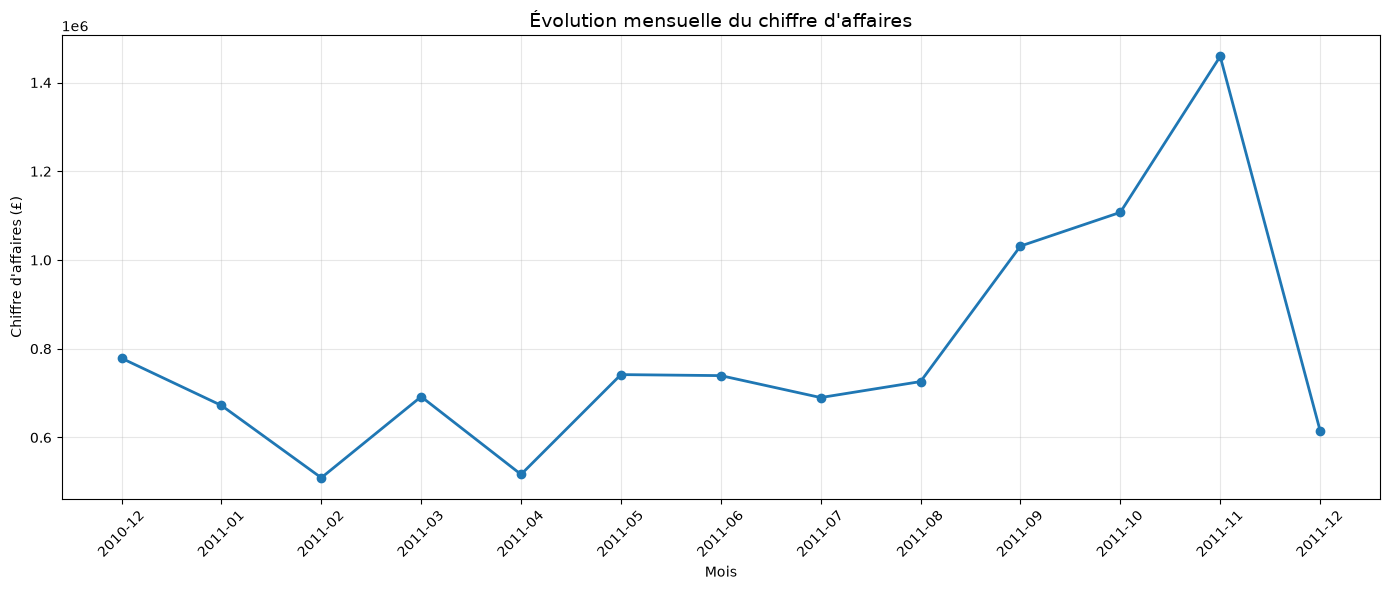

In [148]:

# Préparation des données
plot_data = monthly_kpis.copy()

plot_data["YearMonth"] = (
    plot_data["YearMonth"].astype(str)
)

# Création du graphique
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    plot_data["YearMonth"],
    plot_data["Revenue"],
    marker="o",
    linewidth=2
)

ax.set_title(
    "Évolution mensuelle du chiffre d'affaires",
    fontsize=14
)

ax.set_xlabel("Mois")
ax.set_ylabel("Chiffre d'affaires (£)")

ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)

fig.tight_layout()

# Sauvegarde dans les trois formats
save_figure(
    fig,
    "monthly_revenue_evolution",
    "temporal_analysis"
)

plt.show()


In [149]:

from pathlib import Path

output_dir = (
    Path("..")
    / "reports"
    / "figures"
    / "temporal_analysis"
)

expected_files = [
    "monthly_revenue_evolution.png",
    "monthly_revenue_evolution.svg",
    "monthly_revenue_evolution.pdf"
]

for filename in expected_files:
    file_path = output_dir / filename

    if file_path.exists():
        print(f"OK : {filename} ({file_path.stat().st_size:,} octets)")
    else:
        print(f"ABSENT : {filename}")


OK : monthly_revenue_evolution.png (212,316 octets)
OK : monthly_revenue_evolution.svg (43,598 octets)
OK : monthly_revenue_evolution.pdf (16,473 octets)


Graphique sauvegardé : ..\reports\figures\product_analysis\top_10_products_revenue


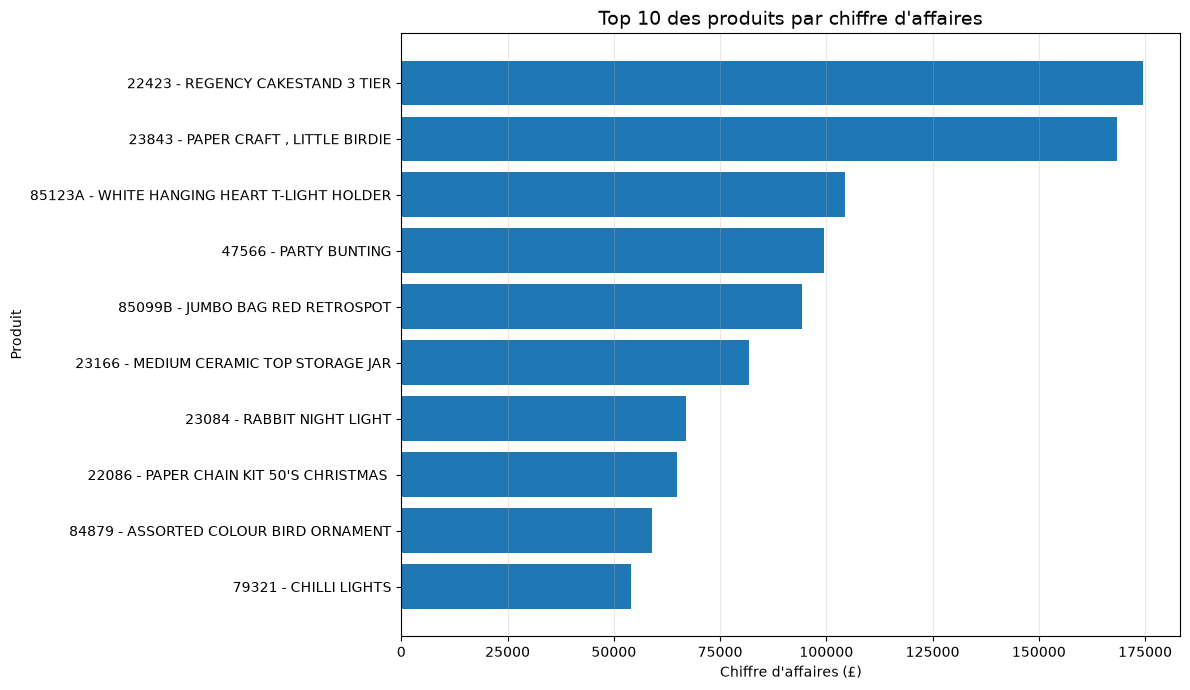

In [150]:

# Préparation des données
top_revenue_plot = (
    top_products_revenue
    .sort_values("Revenue", ascending=True)
    .copy()
)

# Libellés des produits
top_revenue_plot["ProductLabel"] = (
    top_revenue_plot["StockCode"].astype(str)
    + " - "
    + top_revenue_plot["Description"].str.slice(0, 35)
)

# Création du graphique
fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    top_revenue_plot["ProductLabel"],
    top_revenue_plot["Revenue"]
)

ax.set_title(
    "Top 10 des produits par chiffre d'affaires",
    fontsize=14
)

ax.set_xlabel("Chiffre d'affaires (£)")
ax.set_ylabel("Produit")
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()

save_figure(
    fig,
    "top_10_products_revenue",
    "product_analysis"
)

plt.show()


Graphique sauvegardé : ..\reports\figures\product_analysis\top_10_products_quantity


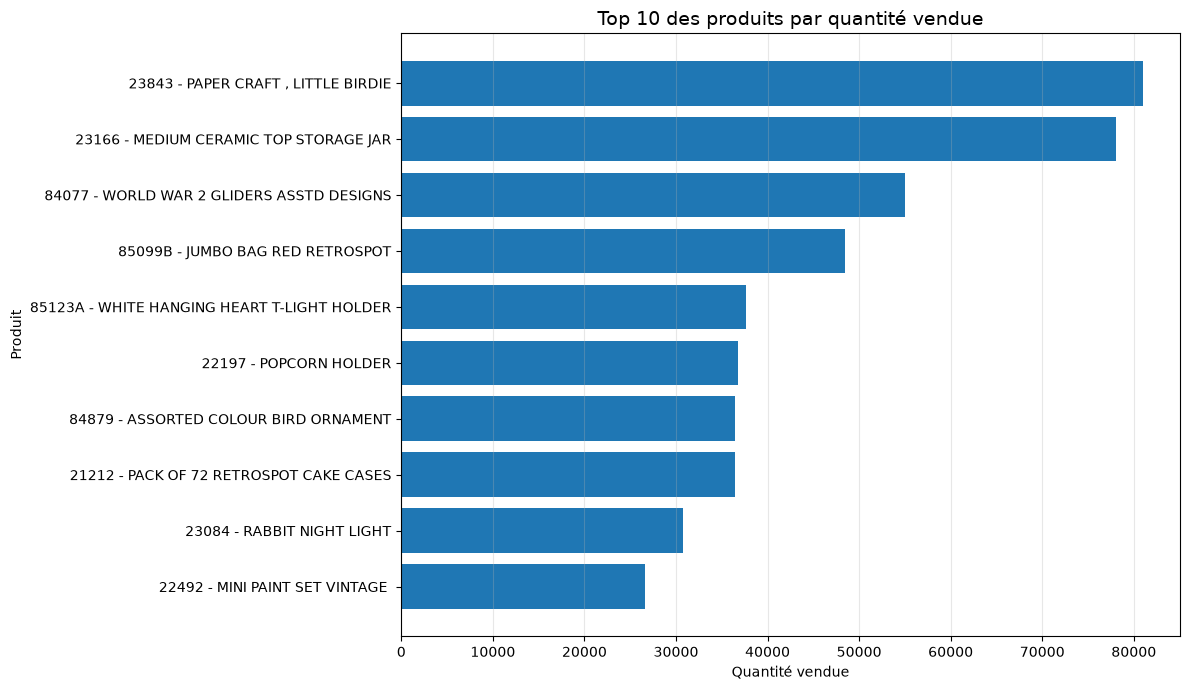

In [151]:

# Préparation des données
top_quantity_plot = (
    top_products_quantity
    .sort_values("QuantitySold", ascending=True)
    .copy()
)

top_quantity_plot["ProductLabel"] = (
    top_quantity_plot["StockCode"].astype(str)
    + " - "
    + top_quantity_plot["Description"].str.slice(0, 35)
)

# Création du graphique
fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    top_quantity_plot["ProductLabel"],
    top_quantity_plot["QuantitySold"]
)

ax.set_title(
    "Top 10 des produits par quantité vendue",
    fontsize=14
)

ax.set_xlabel("Quantité vendue")
ax.set_ylabel("Produit")
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()

# Sauvegarde PNG, SVG et PDF
save_figure(
    fig,
    "top_10_products_quantity",
    "product_analysis"
)

plt.show()


Graphique sauvegardé : ..\reports\figures\customer_analysis\top_10_customers_revenue


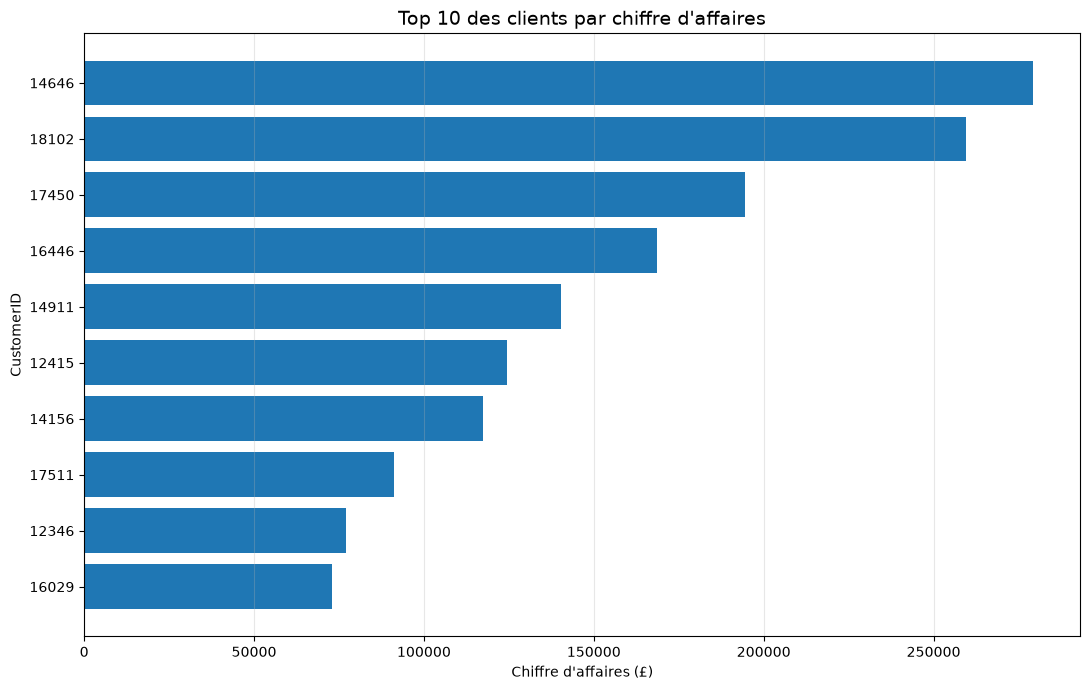

In [152]:

# Préparation des données
top_customers_plot = (
    top_customers
    .sort_values("Revenue", ascending=True)
    .copy()
)

top_customers_plot["CustomerLabel"] = (
    top_customers_plot["CustomerID"].astype(int).astype(str)
)

# Création du graphique
fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    top_customers_plot["CustomerLabel"],
    top_customers_plot["Revenue"]
)

ax.set_title(
    "Top 10 des clients par chiffre d'affaires",
    fontsize=14
)

ax.set_xlabel("Chiffre d'affaires (£)")
ax.set_ylabel("CustomerID")
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()

save_figure(
    fig,
    "top_10_customers_revenue",
    "customer_analysis"
)

plt.show()


Graphique sauvegardé : ..\reports\figures\geographic_analysis\geographic_revenue_pareto


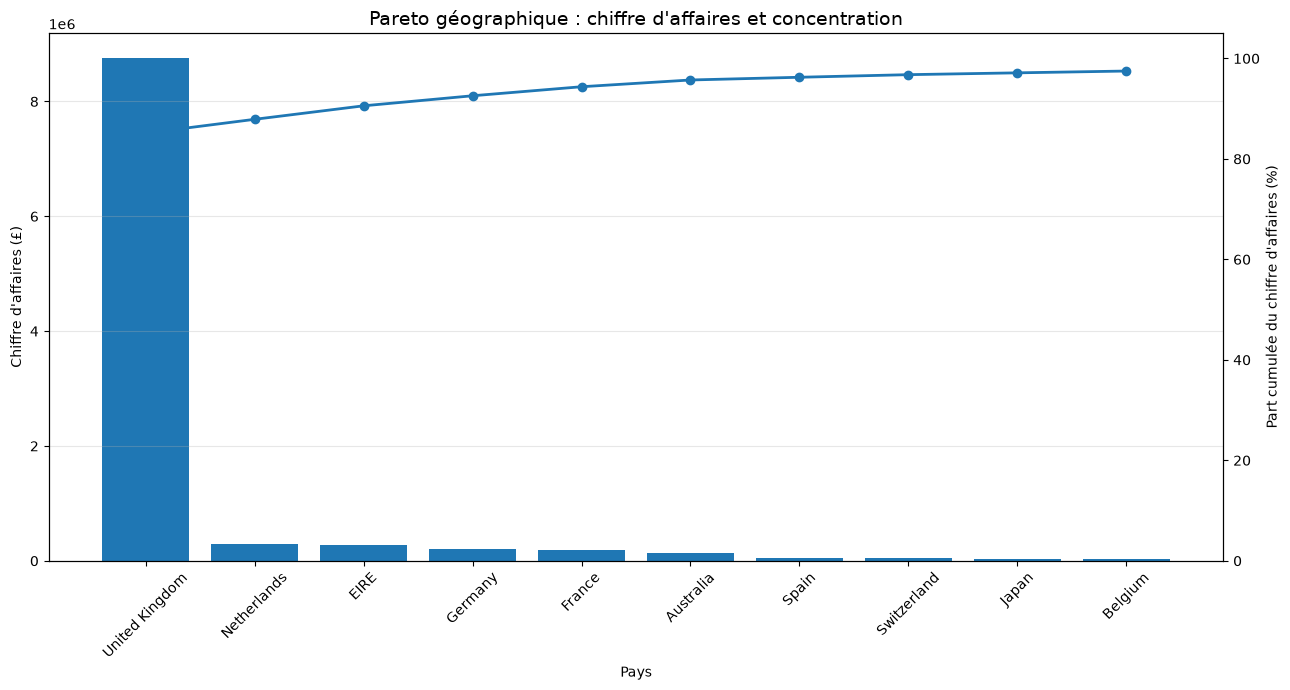

In [153]:

# Les 10 premiers pays pour conserver une bonne lisibilité
pareto_plot = geographic_pareto.head(10).copy()

fig, ax1 = plt.subplots(figsize=(13, 7))

# Barres : chiffre d'affaires
ax1.bar(
    pareto_plot["Country"],
    pareto_plot["Revenue"]
)

ax1.set_title(
    "Pareto géographique : chiffre d'affaires et concentration",
    fontsize=14
)

ax1.set_xlabel("Pays")
ax1.set_ylabel("Chiffre d'affaires (£)")
ax1.tick_params(axis="x", rotation=45)
ax1.grid(axis="y", alpha=0.3)

# Courbe : part cumulée
ax2 = ax1.twinx()

ax2.plot(
    pareto_plot["Country"],
    pareto_plot["CumulativeShare"],
    marker="o",
    linewidth=2
)

ax2.set_ylabel("Part cumulée du chiffre d'affaires (%)")
ax2.set_ylim(0, 105)

fig.tight_layout()

save_figure(
    fig,
    "geographic_revenue_pareto",
    "geographic_analysis"
)

plt.show()


In [154]:

from pathlib import Path

expected_figures = {
    "temporal_analysis": [
        "monthly_revenue_evolution"
    ],
    "product_analysis": [
        "top_10_products_revenue",
        "top_10_products_quantity"
    ],
    "customer_analysis": [
        "top_10_customers_revenue"
    ],
    "geographic_analysis": [
        "geographic_revenue_pareto"
    ]
}

formats = ["png", "svg", "pdf"]

missing_files = []
verified_files = []

for category, filenames in expected_figures.items():
    for filename in filenames:
        for file_format in formats:
            path = FIGURES_DIR / category / f"{filename}.{file_format}"

            if path.exists() and path.stat().st_size > 0:
                verified_files.append(path)
                print(f"OK      : {path}")
            else:
                missing_files.append(path)
                print(f"MANQUANT: {path}")

print("\n" + "=" * 50)
print(f"Fichiers vérifiés : {len(verified_files)}/15")
print(f"Fichiers manquants : {len(missing_files)}")

if not missing_files:
    print("VALIDATION RÉUSSIE : les 15 fichiers sont présents.")
else:
    print("VALIDATION INCOMPLÈTE : certains fichiers doivent être régénérés.")


OK      : ..\reports\figures\temporal_analysis\monthly_revenue_evolution.png
OK      : ..\reports\figures\temporal_analysis\monthly_revenue_evolution.svg
OK      : ..\reports\figures\temporal_analysis\monthly_revenue_evolution.pdf
OK      : ..\reports\figures\product_analysis\top_10_products_revenue.png
OK      : ..\reports\figures\product_analysis\top_10_products_revenue.svg
OK      : ..\reports\figures\product_analysis\top_10_products_revenue.pdf
OK      : ..\reports\figures\product_analysis\top_10_products_quantity.png
OK      : ..\reports\figures\product_analysis\top_10_products_quantity.svg
OK      : ..\reports\figures\product_analysis\top_10_products_quantity.pdf
OK      : ..\reports\figures\customer_analysis\top_10_customers_revenue.png
OK      : ..\reports\figures\customer_analysis\top_10_customers_revenue.svg
OK      : ..\reports\figures\customer_analysis\top_10_customers_revenue.pdf
OK      : ..\reports\figures\geographic_analysis\geographic_revenue_pareto.png
OK      : ..\re

In [155]:

from pathlib import Path
import importlib.util
import pandas as pd

# Dossier de destination
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Jeux de données à exporter
datasets = {
    "final_sales_df": final_sales_df,
    "final_commercial_df": final_commercial_df,
    "final_sales_standard_df": final_sales_standard_df,
    "free_lines_df": free_lines_df,
    "potential_movements_df": potential_movements_df
}

# Vérification et export CSV
export_summary = []

for name, dataframe in datasets.items():
    output_path = OUTPUT_DIR / f"{name}.csv"

    dataframe.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )

    export_summary.append({
        "Dataset": name,
        "Lignes": len(dataframe),
        "Colonnes": len(dataframe.columns),
        "Taille (Ko)": round(output_path.stat().st_size / 1024, 2),
        "Format": "CSV",
        "Statut": "OK"
    })

    print(f"Export terminé : {output_path}")

# Vérifier si un moteur Parquet est disponible
parquet_available = (
    importlib.util.find_spec("pyarrow") is not None
    or importlib.util.find_spec("fastparquet") is not None
)

if parquet_available:
    for name, dataframe in datasets.items():
        output_path = OUTPUT_DIR / f"{name}.parquet"
        dataframe.to_parquet(output_path, index=False)

        print(f"Export Parquet terminé : {output_path}")
else:
    print("\nParquet non disponible : export CSV uniquement.")

# Tableau récapitulatif
export_report = pd.DataFrame(export_summary)
display(export_report)

print("\nNombre de datasets exportés :", len(export_summary))
print("Dossier de destination :", OUTPUT_DIR.resolve())


Export terminé : ..\data\processed\final_sales_df.csv
Export terminé : ..\data\processed\final_commercial_df.csv
Export terminé : ..\data\processed\final_sales_standard_df.csv
Export terminé : ..\data\processed\free_lines_df.csv
Export terminé : ..\data\processed\potential_movements_df.csv

Parquet non disponible : export CSV uniquement.


,Dataset,Lignes,Colonnes,Taille (Ko),Format,Statut
0,final_sales_df,532618,14,87363.16,CSV,OK
1,final_commercial_df,530437,14,87079.26,CSV,OK
2,final_sales_standard_df,527935,14,86620.24,CSV,OK
3,free_lines_df,1166,13,203.07,CSV,OK
4,potential_movements_df,1336,14,255.14,CSV,OK



Nombre de datasets exportés : 5
Dossier de destination : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\data\processed


In [156]:

import pandas as pd

validation_results = []

for name, original_df in datasets.items():
    file_path = OUTPUT_DIR / f"{name}.csv"

    # Relecture du fichier exporté
    exported_df = pd.read_csv(file_path, encoding="utf-8-sig")

    # Contrôles structurels
    same_rows = len(exported_df) == len(original_df)
    same_columns = list(exported_df.columns) == list(original_df.columns)

    # Contrôle des valeurs numériques importantes
    numeric_checks = {}

    for column in ["Quantity", "UnitPrice", "LineTotal"]:
        if column in original_df.columns:
            original_sum = pd.to_numeric(
                original_df[column], errors="coerce"
            ).sum()

            exported_sum = pd.to_numeric(
                exported_df[column], errors="coerce"
            ).sum()

            numeric_checks[column] = abs(
                original_sum - exported_sum
            ) < 0.01

    numeric_ok = all(numeric_checks.values())

    validation_results.append({
        "Dataset": name,
        "Lignes identiques": same_rows,
        "Colonnes identiques": same_columns,
        "Valeurs numériques cohérentes": numeric_ok,
        "Validation": "OK" if (
            same_rows and same_columns and numeric_ok
        ) else "À vérifier"
    })

validation_df = pd.DataFrame(validation_results)
display(validation_df)

if (validation_df["Validation"] == "OK").all():
    print("VALIDATION RÉUSSIE : les 5 exports sont cohérents.")
else:
    print("ATTENTION : au moins un export nécessite une vérification.")


,Dataset,Lignes identiques,Colonnes identiques,Valeurs numériques cohérentes,Validation
0,final_sales_df,True,True,True,OK
1,final_commercial_df,True,True,True,OK
2,final_sales_standard_df,True,True,True,OK
3,free_lines_df,True,True,True,OK
4,potential_movements_df,True,True,True,OK


VALIDATION RÉUSSIE : les 5 exports sont cohérents.


In [157]:

from pathlib import Path

readme_content = r"""
# Analyse et nettoyage d'un jeu de données de ventes

## 1. Présentation du projet

Ce projet porte sur l'audit, le nettoyage et l'analyse exploratoire
d'un jeu de données transactionnelles de vente au détail en ligne.

L'objectif est de transformer des données brutes en jeux de données
fiables, documentés et exploitables pour l'analyse décisionnelle.

## 2. Source des données

- Dataset : Online Retail
- Source : UCI Machine Learning Repository
- Période couverte : décembre 2010 à décembre 2011
- Nombre de lignes initial : 541 909
- Nombre de colonnes initial : 8

Les données décrivent des transactions d'un détaillant en ligne
britannique, avec notamment les factures, les produits, les quantités,
les prix, les dates et les pays.

## 3. Technologies utilisées

- Python
- pandas
- NumPy
- Matplotlib
- Jupyter Notebook
- openpyxl

## 4. Structure du projet

```text
sales-data-analysis/
├── data/
│   ├── raw/
│   │   └── Online Retail.xlsx
│   └── processed/
│       ├── final_sales_df.csv
│       ├── final_commercial_df.csv
│       ├── final_sales_standard_df.csv
│       ├── free_lines_df.csv
│       └── potential_movements_df.csv
├── notebooks/
│   └── 01_audit_qualite.ipynb
├── reports/
│   ├── figures/
│   │   ├── temporal_analysis/
│   │   ├── product_analysis/
│   │   ├── customer_analysis/
│   │   └── geographic_analysis/
│   └── tables/
├── README.md
└── requirements.txt
```

## 5. Méthodologie

Le travail a été organisé en plusieurs étapes :

1. Chargement et inspection des données.
2. Audit de qualité : valeurs manquantes, doublons,
   incohérences et valeurs atypiques.
3. Traitement des descriptions manquantes lorsque la correspondance
   avec le code produit était suffisamment fiable.
4. Analyse des quantités, prix, factures et codes produits.
5. Identification des opérations non commerciales potentielles.
6. Classification des transactions.
7. Construction des jeux de données analytiques.
8. Analyses temporelles, produits, clients et géographie.
9. Visualisation et export des résultats.
10. Vérification de l'intégrité des fichiers exportés.

## 6. Principales décisions de nettoyage

- Les CustomerID manquants ont été conservés : leur absence ne
  justifie pas la suppression d'une transaction.
- Les descriptions manquantes ont été récupérées uniquement lorsque
  la correspondance avec le code produit était suffisamment fiable.
- Les doublons exacts ont été identifiés, mais aucune suppression
  automatique n'a été appliquée sans justification métier.
- Les factures d'annulation identifiées par le préfixe C ont été
  distinguées des ventes standard.
- Les ajustements et opérations manuelles ont été isolés.
- Les lignes gratuites ont été conservées dans un dataset dédié.
- Les mouvements non commerciaux potentiels ont été isolés sans
  les présenter comme des pertes comptables avérées.
- La cohérence entre Quantity, UnitPrice et LineTotal a été vérifiée.

## 7. Jeux de données produits

| Fichier | Description | Nombre de lignes |
|---|---|---:|
| final_sales_df.csv | Données commerciales consolidées | 532 618 |
| final_commercial_df.csv | Périmètre commercial après exclusions opérationnelles | 530 437 |
| final_sales_standard_df.csv | Ventes standard utilisées pour les analyses | 527 935 |
| free_lines_df.csv | Lignes gratuites ou sans montant | 1 166 |
| potential_movements_df.csv | Mouvements non commerciaux potentiels | 1 336 |

Les exports sont disponibles au format CSV encodé en UTF-8 avec BOM.

## 8. Résultats principaux

### Ventes standard

- Nombre de lignes : 527 935
- Nombre de factures : 19 778
- Chiffre d'affaires : 10 279 232,92 £
- Quantité vendue : 5 577 280

### Analyse temporelle

Le chiffre d'affaires atteint son niveau mensuel le plus élevé
en novembre 2011, avec 1 458 895,53 £.

Décembre 2011 est incomplet dans le jeu de données, qui s'arrête
au 9 décembre 2011.

### Analyse géographique

Le Royaume-Uni représente environ 85,12 % du chiffre d'affaires.
Les six premiers pays représentent environ 95,71 % du chiffre
d'affaires total.

### Analyse clients

4 334 clients disposent d'un identifiant exploitable dans le
périmètre des ventes standard.

Le chiffre d'affaires associé aux lignes sans CustomerID est
conservé séparément dans les analyses de couverture client.

### Analyse produits

Les classements par chiffre d'affaires et par quantité ont été
étudiés séparément. Une transaction exceptionnelle concernant
le produit 23843 a été identifiée et documentée ; elle n'a pas
été supprimée automatiquement.

## 9. Visualisations

Les graphiques sont disponibles dans `reports/figures/`.

Les analyses comprennent :

- Évolution mensuelle du chiffre d'affaires.
- Top 10 des produits par chiffre d'affaires.
- Top 10 des produits par quantité.
- Top 10 des clients par chiffre d'affaires.
- Analyse Pareto du chiffre d'affaires par pays.

Chaque graphique est sauvegardé en PNG, SVG et PDF.

## 10. Installation et exécution

Cloner ou télécharger le projet, puis installer les dépendances :

```bash
pip install -r requirements.txt
```

Placer le fichier source `Online Retail.xlsx` dans `data/raw/`.

Ouvrir ensuite le notebook :

```bash
jupyter notebook
```

Exécuter `notebooks/01_audit_qualite.ipynb` dans l'ordre.

Les chemins du notebook sont relatifs au dossier `notebooks`.

## 11. Limites et précautions d'interprétation

- Les identifiants clients manquants limitent l'analyse individuelle
  de la clientèle.
- Certaines opérations atypiques ne peuvent pas être interprétées
  avec certitude à partir des seules données disponibles.
- Les mouvements non commerciaux potentiels sont des classifications
  heuristiques et ne constituent pas des preuves comptables.
- La période de décembre 2011 est partielle.
- Les résultats décrivent le jeu de données observé et ne démontrent
  pas de relations causales.

## 12. Conclusion

Ce projet fournit un processus documenté d'audit, de nettoyage,
de classification et d'analyse de données transactionnelles.

Les jeux de données exportés distinguent les ventes standard,
les opérations commerciales élargies et certains mouvements
spécifiques afin de préserver la traçabilité des décisions.

"""

project_root = Path("..")
readme_path = project_root / "README.md"

readme_path.write_text(readme_content.strip() + "\n", encoding="utf-8")

print("README créé :", readme_path.resolve())
print("Taille :", round(readme_path.stat().st_size / 1024, 2), "Ko")


README créé : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\README.md
Taille : 6.5 Ko


In [158]:

from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

# Bibliothèques utilisées par le projet
packages = [
    "pandas",
    "numpy",
    "matplotlib",
    "openpyxl",
    "jupyter",
    "ipykernel"
]

requirements = []

for package in packages:
    try:
        installed_version = version(package)
        requirements.append(f"{package}=={installed_version}")
        print(f"OK : {package}=={installed_version}")
    except PackageNotFoundError:
        print(f"NON INSTALLÉ : {package}")

# Création du fichier à la racine du projet
requirements_path = Path("..") / "requirements.txt"

requirements_path.write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)

print("\nFichier créé :", requirements_path.resolve())
print("\nContenu :")
print(requirements_path.read_text(encoding="utf-8"))


OK : pandas==3.1.0
OK : numpy==2.5.4
OK : matplotlib==3.11.2
OK : openpyxl==3.1.5
OK : jupyter==1.1.1
OK : ipykernel==7.4.0

Fichier créé : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\requirements.txt

Contenu :
pandas==3.1.0
numpy==2.5.4
matplotlib==3.11.2
openpyxl==3.1.5
jupyter==1.1.1
ipykernel==7.4.0



In [159]:

from pathlib import Path

project_root = Path("..")

expected_files = [
    "README.md",
    "requirements.txt",
    "data/raw/Online Retail.xlsx",
    "data/processed/final_sales_df.csv",
    "data/processed/final_commercial_df.csv",
    "data/processed/final_sales_standard_df.csv",
    "data/processed/free_lines_df.csv",
    "data/processed/potential_movements_df.csv",
    "notebooks/01_audit_qualite.ipynb"
]

for relative_path in expected_files:
    path = project_root / relative_path

    if path.exists() and path.stat().st_size > 0:
        print(f"OK      : {relative_path}")
    else:
        print(f"MANQUANT: {relative_path}")


OK      : README.md
OK      : requirements.txt
OK      : data/raw/Online Retail.xlsx
OK      : data/processed/final_sales_df.csv
OK      : data/processed/final_commercial_df.csv
OK      : data/processed/final_sales_standard_df.csv
OK      : data/processed/free_lines_df.csv
OK      : data/processed/potential_movements_df.csv
OK      : notebooks/01_audit_qualite.ipynb
